In [1]:
%%capture
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Snake photo dataset: what do we actually have?

SerpentGuard AI, Group 5 (IIT Madras DS and AI Lab, 2026 T3), Milestone 2.

This notebook goes through the snake photos step by step: what is in the tables, how clean the data is, how the splits were made, what the images look like, and which extra sources could add something. Every number below is computed from the files when the notebook runs. It runs on the licence-clean dataset, so photos under all-rights-reserved and no-derivatives licences are not included.

- Setup
- Where the data lives
- Helpers
- Loading the tables
- 1. Know the files
- 2. Labels
- 3. Splits and leakage
- 4. Images: every photo, from the metadata
- 5. Looking at the images
- 6. Context: where, when, who and under which licence
- 7. Safety lookalikes
- 9. Summary

## Setup
Imports first, then a few settings that the rest of the notebook uses.

In [2]:
import json
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from PIL import Image
from scipy.fft import dctn

warnings.filterwarnings("ignore")

In [3]:
ON_KAGGLE = Path("/kaggle/input").exists()
SMOKE = os.environ.get("SMOKE") == "1"
SEED = 42
SAMPLE_PER_CLASS = 3 if SMOKE else 30
print("on Kaggle:", ON_KAGGLE, "| quick test mode:", SMOKE)

on Kaggle: True | quick test mode: False


## Where the data lives
The team datasets are private on Kaggle. When the notebook runs on Kaggle they are attached as inputs, otherwise the helper below downloads them.

In [4]:
HANDLES = {
    "processed": "puneetbajajiitm/serpentguard-indian-snakes-clean",
    "splits": "puneetbajajiitm/serpentguard-m2-splits",
    "masks": "puneetbajajiitm/serpentguard-sam-masks",
}

In [5]:
def find(name):
    handle = HANDLES[name]
    owner, slug = handle.split("/")
    local = Path(os.environ.get("SERPENT_LOCAL", "no-local-copy")) / name
    for p in (Path("/kaggle/input/datasets") / owner / slug, Path("/kaggle/input") / slug, local):
        if p.exists():
            return p
    if ON_KAGGLE:
        raise FileNotFoundError(f"{handle} is not attached to this notebook")
    import kagglehub
    return Path(kagglehub.dataset_download(handle))

In [6]:
BASE, SPLITS, MASKS = find("processed"), find("splits"), find("masks")
for p in (BASE, SPLITS, MASKS):
    print(p)

/kaggle/input/datasets/puneetbajajiitm/serpentguard-indian-snakes-clean
/kaggle/input/datasets/puneetbajajiitm/serpentguard-m2-splits
/kaggle/input/datasets/puneetbajajiitm/serpentguard-sam-masks


In [7]:
WORK = Path("/kaggle/working") if ON_KAGGLE else Path(os.environ.get("SERPENT_WORK", "work_out"))
FIG = WORK / "figures"
FIG.mkdir(parents=True, exist_ok=True)

## Helpers
A few small helpers used all the way through. The colours stay the same in every chart: red for WHO category 1, orange for category 2 and grey for the rest.

In [8]:
WHO_COLORS = {"1": "#d62728", "2": "#ff7f0e", "not_listed": "#8a9bb0"}
WHO_LABEL = {"1": "WHO category 1", "2": "WHO category 2", "not_listed": "Not listed"}
SPLIT_ORDER = ["train", "val", "test", "test_extra", "unknown_pool"]
FMT = mticker.FuncFormatter(lambda x, _: f"{int(x):,}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

In [9]:
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=90, bbox_inches="tight")
    plt.show()

In [10]:
CHECKS = []

def check(label, ok, detail=""):
    CHECKS.append((label, bool(ok)))
    print(("PASS  " if ok else "FAIL  ") + label + (f"  ({detail})" if detail else ""))

In [11]:
def is_cc(license_code):
    return str(license_code).lower().startswith("cc")

def img_file(path):
    return BASE / "data" / path

In [12]:
def sample_ids(df, per_class, seed=SEED):
    if not ON_KAGGLE:
        df = df[df["path"].map(lambda p: img_file(p).exists())]
    shuffled = df.sample(frac=1, random_state=seed)
    return shuffled[shuffled.groupby("species").cumcount() < per_class]

In [13]:
# same perceptual hash as the dataset notebook: 32x32 grey, DCT, keep 8x8, median threshold
def phash64(image):
    gray = np.asarray(image.convert("L").resize((32, 32), Image.LANCZOS), dtype=np.float32)
    low = dctn(gray, norm="ortho")[:8, :8].flatten()
    bits = low > np.median(low[1:])
    return f"{int(''.join('1' if b else '0' for b in bits), 2):016x}"

In [14]:
def hamming(a, b):
    return bin(int(a, 16) ^ int(b, 16)).count("1")

## Loading the tables
Ids are read as text so they don't turn into floats. `created_at` carries a time-zone offset, so it is parsed as UTC.

In [15]:
ID_COLS = {"obs_id": str, "photo_id": str, "observer_id": str, "sha1": str, "phash": str, "who_category": str}
meta = pd.read_csv(BASE / "metadata.csv", dtype=ID_COLS)
meta.shape

(121566, 33)

In [16]:
meta["created_at"] = pd.to_datetime(meta["created_at"], utc=True)
meta["observed_on"] = pd.to_datetime(meta["observed_on"], errors="coerce")
meta["year"] = meta["observed_on"].dt.year
meta["month"] = meta["observed_on"].dt.month

In [17]:
classes = pd.read_csv(BASE / "classes.csv", dtype={"who_category": str})
splits_all = pd.read_csv(SPLITS / "splits.csv", dtype=ID_COLS)
excluded = pd.read_csv(SPLITS / "excluded.csv", dtype=ID_COLS)
mask_stats = pd.read_csv(MASKS / "mask_stats.csv", dtype={"photo_id": str, "who_category": str})
mask_stats = mask_stats[mask_stats["path"].isin(meta.loc[meta["split"] == "train", "path"])]  # masks of clean training photos only
report = json.loads((BASE / "processing_report.json").read_text())
ALLOWED_LICENCES = ["cc0", "cc-by", "cc-by-sa", "cc-by-nc", "cc-by-nc-sa"]
allowed_rows = splits_all["license"].isin(ALLOWED_LICENCES)

In [18]:
for name, d in [("metadata", meta), ("classes", classes), ("splits.csv", splits_all), ("excluded", excluded), ("mask_stats", mask_stats)]:
    print(f"{name:12s} {d.shape[0]:>8,} rows  {d.shape[1]:>2} columns")

metadata      121,566 rows  35 columns
classes           184 rows  13 columns
splits.csv    181,503 rows  31 columns
excluded          994 rows  25 columns
mask_stats     85,067 rows  17 columns


### Lookalike pairs
Some not-listed snakes are easy to confuse with dangerous ones. These are the pairs from the Milestone 1 report (section 3.6, taken from iNaturalist's similar-species counts), plus two pairs where both snakes are dangerous. The WHO category of each species is always read from `classes.csv`, never typed in by hand.

In [19]:
LOOKALIKE_PAIRS = [
    ("Naja naja", "Ptyas mucosa", "spectacled cobra and oriental rat snake"),
    ("Bungarus caeruleus", "Lycodon aulicus", "common krait and Indian wolf snake"),
    ("Bungarus caeruleus", "Lycodon travancoricus", "common krait and Travancore wolf snake"),
    ("Bungarus caeruleus", "Lycodon fasciolatus", "common krait and Russell's wolf snake"),
    ("Daboia russelii", "Eryx conicus", "Russell's viper and rough-scaled sand boa"),
    ("Daboia russelii", "Python molurus", "Russell's viper and Indian rock python"),
    ("Echis carinatus", "Boiga trigonata", "saw-scaled viper and common cat snake"),
    ("Naja naja", "Fowlea piscator", "spectacled cobra and checkered keelback"),
    ("Craspedocephalus gramineus", "Rhabdophis plumbicolor", "bamboo pit viper and green keelback"),
]

In [20]:
DANGEROUS_PAIRS = [
    ("Hypnale hypnale", "Craspedocephalus malabaricus", "hump-nosed and Malabar pit viper"),
    ("Hypnale hypnale", "Echis carinatus", "hump-nosed pit viper and saw-scaled viper"),
]

In [21]:
who_of = classes.set_index("species")["who_category"].to_dict()
LOOKALIKES = [p for p in LOOKALIKE_PAIRS if p[0] in who_of and p[1] in who_of]
DANGEROUS = [p for p in DANGEROUS_PAIRS if p[0] in who_of and p[1] in who_of]
print(len(LOOKALIKES), "of", len(LOOKALIKE_PAIRS), "pairs found in classes.csv")

9 of 9 pairs found in classes.csv


## 1. Know the files
Before any charts, let's check what is in each file: the columns and their types, what is missing, whether the table matches the images on disk, and whether the counts agree between the files.

In [22]:
import time
import itertools
from scipy import stats

### 1.1 Columns and types
`metadata.csv` has one row per photo. Here is each column with its type, how many values are filled in and how many different values it has.

In [23]:
tab_schema = pd.DataFrame({"dtype": meta.dtypes.astype(str), "filled": meta.notna().sum(), "unique": meta.nunique()})
tab_schema

,dtype,filled,unique
file,object,121566,121566
source,object,121566,1
source_record_id,int64,121566,62772
obs_id,object,121566,62772
photo_id,object,121566,121566
photo_position,int64,121566,85
species,object,121566,281
genus,object,121566,77
taxon_id,int64,121566,281
record_taxon,object,121566,344


Ids such as `photo_id`, `obs_id` and `observer_id` are kept as text so they can't turn into floats. A few quick sanity checks on the table before going on.

In [24]:
check("photo_id is unique", meta["photo_id"].is_unique)
check("metadata.csv has the 33 raw columns", meta.shape[1] - 2 == 33, f"{meta.shape[1]} columns including year and month")
check("who_category holds the strings 1, 2 and not_listed", set(meta["who_category"]) == {"1", "2", "not_listed"})
check("every photo comes from iNaturalist", set(meta["source"]) == {"inaturalist"})

PASS  photo_id is unique
PASS  metadata.csv has the 33 raw columns  (35 columns including year and month)
PASS  who_category holds the strings 1, 2 and not_listed
PASS  every photo comes from iNaturalist


### 1.2 Missing values

In [25]:
tab_missing = meta.isna().sum()
tab_missing = tab_missing[tab_missing > 0].to_frame("missing")
tab_missing["share of rows %"] = (100 * tab_missing["missing"] / len(meta)).round(2)
tab_missing

,missing,share of rows %
latitude,763,0.63
longitude,763,0.63


In [26]:
check("only latitude and longitude have gaps", list(tab_missing.index) == ["latitude", "longitude"])
check("763 rows have no coordinates", tab_missing["missing"].tolist() == [763, 763])

PASS  only latitude and longitude have gaps
PASS  763 rows have no coordinates


The only gaps are in the two coordinate columns. Let's see what the rows without coordinates have in common.

In [27]:
tab_nocoord = meta[meta["latitude"].isna()]
print(f"{len(tab_nocoord):,} photos have no coordinates")
print("obscured:", tab_nocoord["obscured"].value_counts().to_dict())
print("inside India:", tab_nocoord["in_india"].value_counts().to_dict())
print("by split:", tab_nocoord["split"].value_counts().to_dict())
check("every photo without coordinates is marked obscured", tab_nocoord["obscured"].all())

763 photos have no coordinates
obscured: {True: 763}
inside India: {False: 763}
by split: {'train': 625, 'val': 75, 'test_extra': 59, 'unknown_pool': 4}
PASS  every photo without coordinates is marked obscured


So a missing coordinate is not random: the observer hid the location. Maps and any location feature have to live with that, and the `in_india` flag is still filled for these rows.

### 1.3 Metadata rows against image files on disk
Each row has a `path` under `data/<split>/<species>/`. On Kaggle we list the folders and compare the names with the table. This is skipped in the quick test mode.

In [28]:
tab_disk, tab_t0 = set(), time.time()
if ON_KAGGLE and not SMOKE:
    try:
        for tab_split in os.scandir(BASE / "data"):
            for tab_sp in os.scandir(tab_split.path):
                tab_disk.update(f"{tab_split.name}/{tab_sp.name}/{f.name}" for f in os.scandir(tab_sp.path))
        print(f"listed {len(tab_disk):,} files in {time.time() - tab_t0:.0f} s")
    except OSError as err:
        print("could not list the image folders:", err)
else:
    print("skipped: the image folders are only listed in a full run on Kaggle")

listed 121,566 files in 0 s


In [29]:
if tab_disk:
    tab_no_file, tab_no_row = set(meta["path"]) - tab_disk, tab_disk - set(meta["path"])
    check("every metadata row has an image file", not tab_no_file, f"{len(tab_no_file):,} rows without a file")
    check("every image file has a metadata row", not tab_no_row, f"{len(tab_no_row):,} files without a row")
else:
    print("nothing to compare in this run")

PASS  every metadata row has an image file  (0 rows without a file)
PASS  every image file has a metadata row  (0 files without a row)


The `bytes` column should also match the real file size. Checking all 121k sizes would be slow on a network mount, so we look at 1,000 random photos.

In [30]:
def tab_size(p):
    try:
        return img_file(p).stat().st_size
    except OSError:
        return -1

if tab_disk:
    tab_pick = meta.sample(1000, random_state=SEED)
    tab_bad = int((tab_pick["path"].map(tab_size).values != tab_pick["bytes"].values).sum())
    check("file size on disk equals the bytes column (1,000 random photos)", tab_bad == 0, f"{tab_bad} differ")
else:
    print("skipped")

PASS  file size on disk equals the bytes column (1,000 random photos)  (0 differ)


### 1.4 `classes.csv` against the metadata
`classes.csv` has one row per class with the photo count in every split. Let's count the same thing from the metadata and compare.

In [31]:
tab_cols = ["train", "val", "test", "test_extra"]
tab_cls = classes.set_index("species")
tab_pivot = pd.crosstab(meta["species"], meta["split"]).reindex(index=tab_cls.index, columns=tab_cols, fill_value=0)
tab_diff = (tab_cls[tab_cols] - tab_pivot).abs()
print(f"classes.csv: {len(tab_cls)} classes, metadata: {meta['species'].nunique()} species")
print("classes where a split count differs:", int((tab_diff.sum(axis=1) > 0).sum()))
check("classes.csv counts equal the metadata counts for every class and split", tab_diff.values.sum() == 0)
check("classes.csv total equals the sum of its split columns", (tab_cls["total"] == tab_cls[tab_cols].sum(axis=1)).all())

classes.csv: 184 classes, metadata: 281 species
classes where a split count differs: 0
PASS  classes.csv counts equal the metadata counts for every class and split
PASS  classes.csv total equals the sum of its split columns


The metadata has more species than `classes.csv`. Let's see whether the extra ones are the unknown pool.

In [32]:
tab_extra_sp = set(meta["species"]) - set(tab_cls.index)
tab_unk_sp = set(meta.loc[meta["tier"] == "unknown_pool", "species"])
print(f"{len(tab_extra_sp)} species are in the metadata but not in classes.csv")
check("those species are exactly the unknown pool", tab_extra_sp == tab_unk_sp)

97 species are in the metadata but not in classes.csv
PASS  those species are exactly the unknown pool


In [33]:
tab_split_n = pd.DataFrame({"metadata.csv": meta["split"].value_counts(), "classes.csv": classes[tab_cols].sum()}).reindex(SPLIT_ORDER)
tab_split_n["share of photos %"] = (100 * tab_split_n["metadata.csv"] / len(meta)).round(1)
tab_split_n

,metadata.csv,classes.csv,share of photos %
train,85067,85067.0,70.0
val,17151,17151.0,14.1
test,5144,5144.0,4.2
test_extra,13389,13389.0,11.0
unknown_pool,815,NaN,0.7


The unknown pool has no row in `classes.csv`, which is why its column is empty. For every other split the two files agree.

### 1.5 What `processing_report.json` says
The report was written by the cleaning notebook. Let's compare its main numbers with what we can count ourselves.

In [34]:
tab_rows = [
    ("photos kept", report["photos"], len(meta)),
    ("restricted licences removed", sum(report["removed_by_licence"].values()), int((~allowed_rows).sum())),
    ("near copies removed", sum(report["near_copies_removed_by_split"].values()), int((allowed_rows & ~splits_all["photo_id"].isin(meta["photo_id"])).sum())),
    ("classes", report["classes"], len(classes)),
    ("tier1 classes", report["classes_by_tier"]["tier1"], int((classes["tier"] == "tier1").sum())),
    ("tier2 classes", report["classes_by_tier"]["tier2"], int((classes["tier"] == "tier2").sum())),
]
tab_rows += [(f"{s} photos", n, int((meta["split"] == s).sum())) for s, n in report["kept_by_split"].items()]
tab_rep = pd.DataFrame(tab_rows, columns=["what", "report says", "computed here"])
tab_rep

,what,report says,computed here
0,photos kept,121566,121566
1,restricted licences removed,59752,59752
2,near copies removed,185,185
3,classes,184,184
4,tier1 classes,56,56
5,tier2 classes,128,128
6,train photos,85067,85067
7,val photos,17151,17151
8,test_extra photos,13389,13389
9,test photos,5144,5144


In [35]:
for what, said, got in tab_rows:
    check(f"processing_report: {what}", said == got, f"report {said:,}, computed {got:,}")
check("processing_report: no sha1 mismatches among kept photos", report["sha1_mismatches"] == 0)

PASS  processing_report: photos kept  (report 121,566, computed 121,566)
PASS  processing_report: restricted licences removed  (report 59,752, computed 59,752)
PASS  processing_report: near copies removed  (report 185, computed 185)
PASS  processing_report: classes  (report 184, computed 184)
PASS  processing_report: tier1 classes  (report 56, computed 56)
PASS  processing_report: tier2 classes  (report 128, computed 128)
PASS  processing_report: train photos  (report 85,067, computed 85,067)
PASS  processing_report: val photos  (report 17,151, computed 17,151)
PASS  processing_report: test_extra photos  (report 13,389, computed 13,389)
PASS  processing_report: test photos  (report 5,144, computed 5,144)
PASS  processing_report: unknown_pool photos  (report 815, computed 815)
PASS  processing_report: no sha1 mismatches among kept photos


The report also lists the leakage counts it measured. We repeat that measurement ourselves in section 3.

In [36]:
tab_split_rep = json.loads((SPLITS / "split_report.json").read_text()) if (SPLITS / "split_report.json").exists() else {}
print("split_report.json found:", bool(tab_split_rep))
pd.Series(report["leakage"], name="overlap reported by the cleaning notebook").to_frame()

split_report.json found: True


,overlap reported by the cleaning notebook
observer_id_in_more_than_one_of_train_val_testfold,0
obs_id_in_more_than_one_of_train_val_testfold,0
sha1_in_more_than_one_of_train_val_testfold,0
phash_in_more_than_one_of_train_val_testfold,0


## 2. Labels
The task is to name the species, so the labels come first: how many photos each species has, how the species group into families, and how the WHO safety categories are spread.

### 2.1 Species long tail
The unknown-pool species are not classes, so this section counts only the classes listed in `classes.csv`. Let's rank the classes by photo count.

In [37]:
tab_in = meta[meta["tier"] != "unknown_pool"]
tab_n = tab_in.groupby("species").size().sort_values(ascending=False)
tab_rank = np.arange(1, len(tab_n) + 1)
print(f"{len(tab_n)} classes, {len(tab_in):,} photos; the unknown pool adds {len(meta) - len(tab_in):,} photos that are not used as classes")
tab_cum = 100 * tab_n.cumsum() / tab_n.sum()
print(f"top 10 classes hold {tab_n.head(10).sum() / tab_n.sum():.1%} of the photos, the 50 smallest hold {tab_n.tail(50).sum() / tab_n.sum():.1%}")
print(f"{int((tab_cum < 50).sum()) + 1} classes are enough to cover half of the photos")

184 classes, 120,751 photos; the unknown pool adds 815 photos that are not used as classes
top 10 classes hold 45.1% of the photos, the 50 smallest hold 1.6%
13 classes are enough to cover half of the photos


In [38]:
def tab_who_legend(ax, **kw):
    from matplotlib.lines import Line2D
    hs = [Line2D([], [], marker="o", ls="", color=c, label=WHO_LABEL[k]) for k, c in WHO_COLORS.items()]
    ax.legend(handles=hs, **kw)

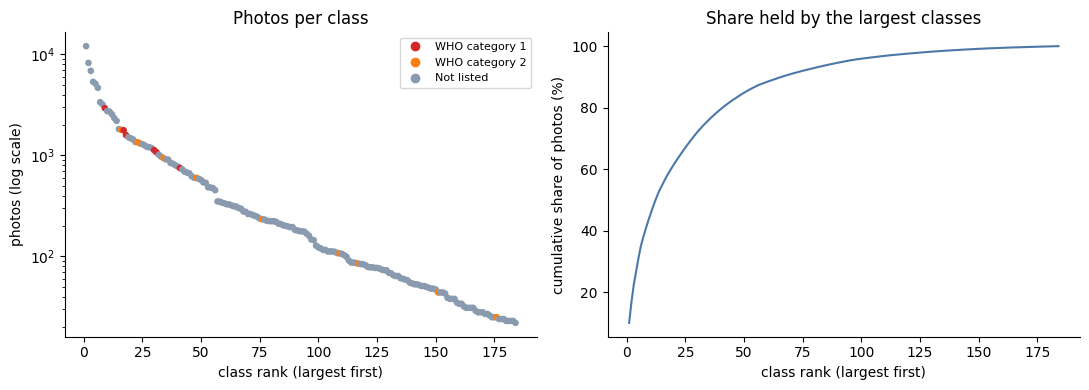

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(tab_rank, tab_n.values, c=[WHO_COLORS[who_of[s]] for s in tab_n.index], s=14)
ax[0].set(yscale="log", xlabel="class rank (largest first)", ylabel="photos (log scale)", title="Photos per class")
tab_who_legend(ax[0], loc="upper right", fontsize=8)
ax[1].plot(tab_rank, tab_cum.values, color="#4c78a8")
ax[1].set(xlabel="class rank (largest first)", ylabel="cumulative share of photos (%)", title="Share held by the largest classes")
savefig("02_long_tail"); plt.close()

On a log axis the classes fall along a long, fairly straight slope, which is what a long tail looks like. The dots are coloured by WHO category, so we can see where the dangerous species sit in the ranking. The quantiles below put numbers on it.

In [40]:
tab_q = tab_n.quantile([0, 0.1, 0.25, 0.5, 0.75, 0.9, 1]).round(0).astype(int).to_frame("photos per class")
tab_q.index = [f"{int(q * 100)}th percentile" for q in tab_q.index]
tab_q

,photos per class
0th percentile,22
10th percentile,31
25th percentile,57
50th percentile,178
75th percentile,605
90th percentile,1502
100th percentile,12038


### 2.2 Class imbalance
Three numbers describe how uneven the classes are: the ratio between the largest and smallest class, the Gini coefficient of the counts (0 means all equal, 1 means one class has everything) and the effective number of classes (how many equally sized classes would give the same spread).

In [41]:
def tab_gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    return float((2 * np.arange(1, len(x) + 1) - len(x) - 1).dot(x) / (len(x) * x.sum()))

def tab_imbalance(counts):
    p = counts / counts.sum()
    return pd.Series({"classes": len(counts), "largest class": counts.max(), "median class": counts.median(), "smallest class": counts.min(),
                      "imbalance ratio (largest / smallest)": counts.max() / counts.min(), "Gini of class counts": tab_gini(counts),
                      "effective classes (1 / sum p^2)": 1 / (p ** 2).sum(), "effective classes (exp of entropy)": np.exp(-(p * np.log(p)).sum())})

In [42]:
tab_imb = pd.DataFrame({"all splits": tab_imbalance(tab_n), "train only": tab_imbalance(classes.set_index("species")["train"])})
tab_imb.round(2)

,all splits,train only
classes,184.00,184.00
largest class,12038.00,8760.00
median class,177.50,120.50
smallest class,22.00,10.00
imbalance ratio (largest / smallest),547.18,876.00
Gini of class counts,0.73,0.73
effective classes (1 / sum p^2),32.58,31.88
effective classes (exp of entropy),61.28,60.79


Now the tiny classes. Let's count how many classes fall under a few photo-count cut-offs.

In [43]:
tab_trn = classes.set_index("species")["train"]
tab_tiny = pd.DataFrame({"classes below": [(tab_n < c).sum() for c in (30, 50, 100, 200)], "train photos below": [(tab_trn < c).sum() for c in (30, 50, 100, 200)]}, index=[30, 50, 100, 200])
tab_tiny.index.name = "photo cut-off"
tab_tiny

,classes below,train photos below
photo cut-off,,
30,18,29
50,38,55
100,73,88
200,98,116


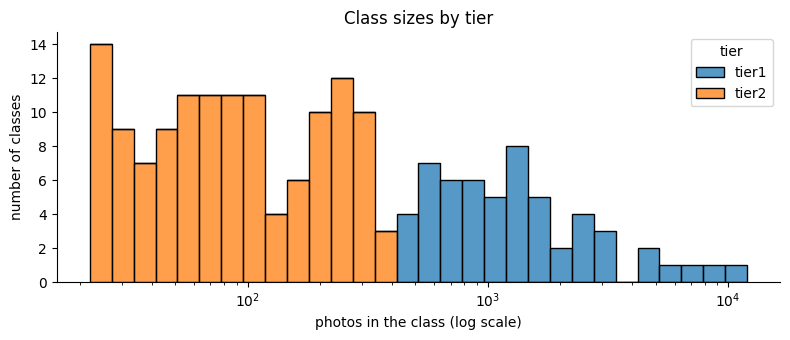

In [44]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(data=classes, x="total", hue="tier", multiple="stack", log_scale=True, bins=30, ax=ax)
ax.set(xlabel="photos in the class (log scale)", ylabel="number of classes", title="Class sizes by tier")
savefig("02_class_sizes"); plt.close()

The tiers are cut by class size, at about the same point, so the stacked histogram shows the same long tail from another side. The smallest classes are listed next, since a model is likely to struggle most with these.

In [45]:
tab_small = classes.sort_values("total").head(12)[["species", "family", "who_category", "tier", "train", "val", "test", "test_extra", "total"]]
tab_small.set_index("species")

,family,who_category,tier,train,val,test,test_extra,total
species,,,,,,,,
Platyceps josephi,Colubridae,not_listed,tier2,18,1,1,2,22
Bungarus andamanensis,Elapidae,not_listed,tier2,22,0,1,0,23
Rhinophis melanoleucus,Uropeltidae,not_listed,tier2,21,0,2,0,23
Platyceps gracilis,Colubridae,not_listed,tier2,14,5,3,1,23
Rhinophis karinthandani,Uropeltidae,not_listed,tier2,19,0,4,0,23
Wallaceophis gujaratensis,Colubridae,not_listed,tier2,24,0,0,0,24
Psammophis condanarus,Psammophiidae,not_listed,tier2,16,3,1,4,24
Trimeresurus medoensis,Viperidae,not_listed,tier2,17,0,3,4,24
Bungarus bungaroides,Elapidae,not_listed,tier2,21,4,0,0,25


### 2.3 Taxonomy
`family` and `genus` come with the metadata. Let's see how the species spread over the families, and over the genera inside each family.

In [46]:
tab_fam = meta.groupby("family").agg(photos=("photo_id", "size"), species=("species", "nunique"), genera=("genus", "nunique"))
tab_fam["classes"] = classes.groupby("family").size().reindex(tab_fam.index).fillna(0).astype(int)
tab_fam = tab_fam.sort_values("photos", ascending=False)
check("14 families in the metadata", len(tab_fam) == 14, f"{len(tab_fam)} found")
check("genus is the first word of the species name", (meta["species"].str.split().str[0] == meta["genus"]).all())
tab_fam

PASS  14 families in the metadata  (14 found)
PASS  genus is the first word of the species name


,photos,species,genera,classes
family,,,,
Colubridae,61496,145,33,101
Viperidae,15783,31,9,20
Elapidae,12755,35,8,25
Typhlopidae,12404,4,4,4
Pythonidae,6736,3,2,3
Psammodynastidae,4663,1,1,1
Homalopsidae,1691,7,7,7
Boidae,1502,4,1,3
Xenopeltidae,1476,1,1,1


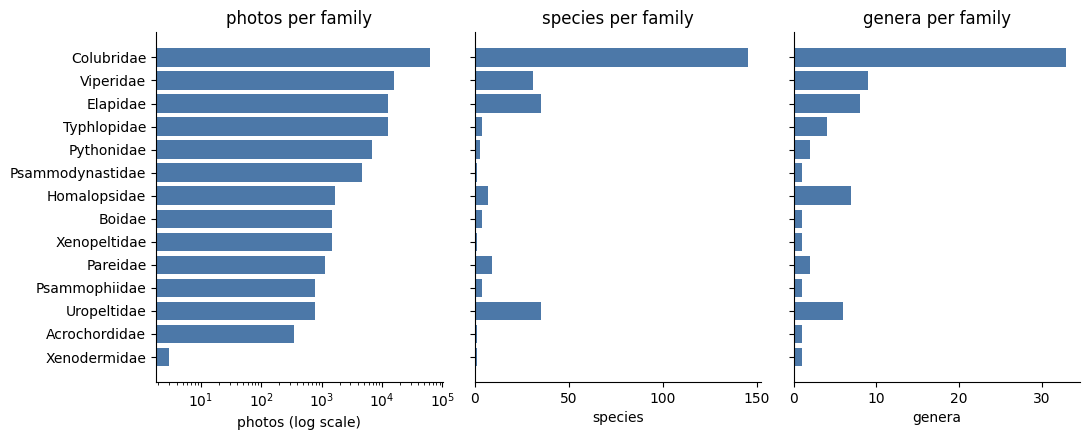

In [47]:
fig, ax = plt.subplots(1, 3, figsize=(11, 4.5), sharey=True)
for a, col, title in zip(ax, ["photos", "species", "genera"], ["photos (log scale)", "species", "genera"]):
    a.barh(tab_fam.index, tab_fam[col], color="#4c78a8")
    a.set(xlabel=title, title=f"{col} per family")
ax[0].set_xscale("log"); ax[0].invert_yaxis()
savefig("02_families"); plt.close()

A few families hold most of the photos and species, while the smallest families have only a handful. The family with the fewest photos has no class of its own: all of its photos sit in the unknown pool. Next, the genera with the most species.

In [48]:
tab_gen = meta.groupby(["family", "genus"]).agg(species=("species", "nunique"), photos=("photo_id", "size")).reset_index()
print(f"{meta['genus'].nunique()} genera in {meta['family'].nunique()} families, {tab_gen['species'].eq(1).sum()} of them with a single species")
tab_gen.sort_values(["species", "photos"], ascending=False).head(10).set_index("genus")

77 genera in 14 families, 30 of them with a single species


,family,species,photos
genus,,,
Uropeltis,Uropeltidae,18,434
Lycodon,Colubridae,17,3819
Boiga,Colubridae,17,3577
Oligodon,Colubridae,16,2416
Ahaetulla,Colubridae,13,11180
Dendrelaphis,Colubridae,12,3072
Hydrophis,Elapidae,11,2214
Trimeresurus,Viperidae,11,637
Craspedocephalus,Viperidae,8,3744


### 2.4 WHO categories
The WHO SEARO 2016 list marks medically important snakes: category 1 is the highest concern, category 2 the next. Everything else is "not listed". The category of each species comes from `classes.csv`.

In [49]:
tab_who = pd.DataFrame({"photos": meta["who_category"].value_counts(), "species": meta.groupby("who_category")["species"].nunique(),
                        "classes": classes["who_category"].value_counts()}).reindex(["1", "2", "not_listed"])
tab_who["share of photos %"] = (100 * tab_who["photos"] / tab_who["photos"].sum()).round(1)
tab_who["median photos per class"] = tab_in.groupby(["who_category", "species"]).size().groupby("who_category").median()
tab_who

,photos,species,classes,share of photos %,median photos per class
who_category,,,,,
1,9237,6,6,7.6,1357.5
2,6501,12,10,5.3,416.0
not_listed,105828,263,168,87.1,153.5


In [50]:
check("each species has a single WHO category in the metadata", (meta.groupby("species")["who_category"].nunique() == 1).all())
check("metadata and classes.csv give the same WHO category", (tab_in.drop_duplicates("species").set_index("species")["who_category"].reindex(tab_cls.index) == tab_cls["who_category"]).all())
check("6 classes in category 1 and 10 in category 2", classes["who_category"].value_counts().reindex(["1", "2"]).tolist() == [6, 10])

PASS  each species has a single WHO category in the metadata
PASS  metadata and classes.csv give the same WHO category
PASS  6 classes in category 1 and 10 in category 2


Let's put photos and classes side by side, and compare how many photos a class gets in each category.

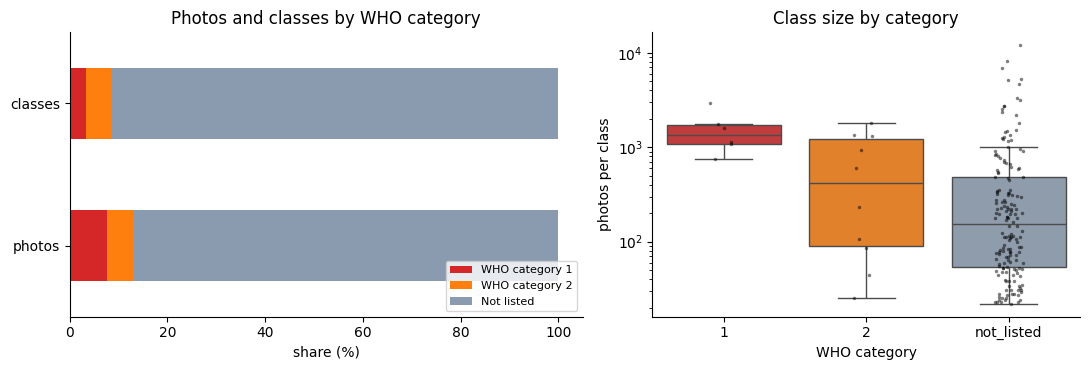

In [51]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
tab_pc = pd.DataFrame({"photos": tab_who["photos"], "classes": tab_who["classes"]})
(100 * tab_pc / tab_pc.sum()).T.plot.barh(stacked=True, color=[WHO_COLORS[c] for c in tab_pc.index], ax=ax[0], legend=False)
ax[0].set(xlabel="share (%)", title="Photos and classes by WHO category")
ax[0].legend([WHO_LABEL[c] for c in tab_pc.index], loc="lower right", fontsize=8)
sns.boxplot(data=classes, x="who_category", y="total", order=["1", "2", "not_listed"], palette=WHO_COLORS, ax=ax[1], fliersize=0)
sns.stripplot(data=classes, x="who_category", y="total", order=["1", "2", "not_listed"], color="black", size=2.5, alpha=0.5, ax=ax[1])
ax[1].set(yscale="log", xlabel="WHO category", ylabel="photos per class", title="Class size by category")
savefig("02_who"); plt.close()

The dangerous categories are a small part of the classes, and category 1 snakes are rather well photographed. The listed species themselves are in the table below, with their photos in each split.

In [52]:
tab_listed = classes[classes["who_category"] != "not_listed"].sort_values(["who_category", "total"], ascending=[True, False])
tab_listed.set_index("species")[["who_category", "tier", "train", "val", "test", "test_extra", "total"]]

,who_category,tier,train,val,test,test_extra,total
species,,,,,,,
Naja naja,1,tier1,2076,338,324,190,2928
Echis carinatus,1,tier1,1238,273,64,196,1771
Daboia russelii,1,tier1,1123,196,170,99,1588
Bungarus caeruleus,1,tier1,799,177,107,44,1127
Hypnale hypnale,1,tier1,747,155,124,47,1073
Naja kaouthia,1,tier1,486,127,22,115,750
Craspedocephalus malabaricus,2,tier1,1236,279,217,57,1789
Craspedocephalus gramineus,2,tier1,813,180,298,58,1349
Bungarus fasciatus,2,tier1,952,140,17,202,1311


### 2.5 Tiers, the milestone-1 core 27 and the unknown pool
`tier1` classes have plenty of photos, `tier2` classes have fewer, and the unknown pool holds species that are too rare to be a class. `m1_core27` marks the 27 classes used in milestone 1.

In [53]:
tab_tier = meta.groupby("tier").agg(photos=("photo_id", "size"), species=("species", "nunique"))
tab_tier["median photos per species"] = meta.groupby(["tier", "species"]).size().groupby("tier").median()
tab_tier["category 1 or 2 species"] = meta[meta["who_category"] != "not_listed"].groupby("tier")["species"].nunique()
tab_tier.fillna(0).astype(int)

,photos,species,median photos per species,category 1 or 2 species
tier,,,,
tier1,105435,56,1191,11
tier2,15316,128,80,5
unknown_pool,815,97,7,2


In [54]:
tab_core = classes[classes["m1_core27"]]
print(f"core set: {len(tab_core)} classes, {tab_core['total'].sum():,} photos ({tab_core['total'].sum() / classes['total'].sum():.1%} of the class photos)")
print("tiers:", tab_core["tier"].value_counts().to_dict(), "| WHO:", tab_core["who_category"].value_counts().to_dict())
check("27 classes are in the milestone-1 core set", len(tab_core) == 27)
check("the unknown pool has 815 photos from 97 species", (len(meta[meta["tier"] == "unknown_pool"]), len(tab_unk_sp)) == (815, 97))

core set: 27 classes, 51,556 photos (42.7% of the class photos)
tiers: {'tier1': 27} | WHO: {'not_listed': 20, '1': 5, '2': 2}
PASS  27 classes are in the milestone-1 core set
PASS  the unknown pool has 815 photos from 97 species


PASS  every unknown-pool species has fewer photos than the smallest class  (19 vs 22)


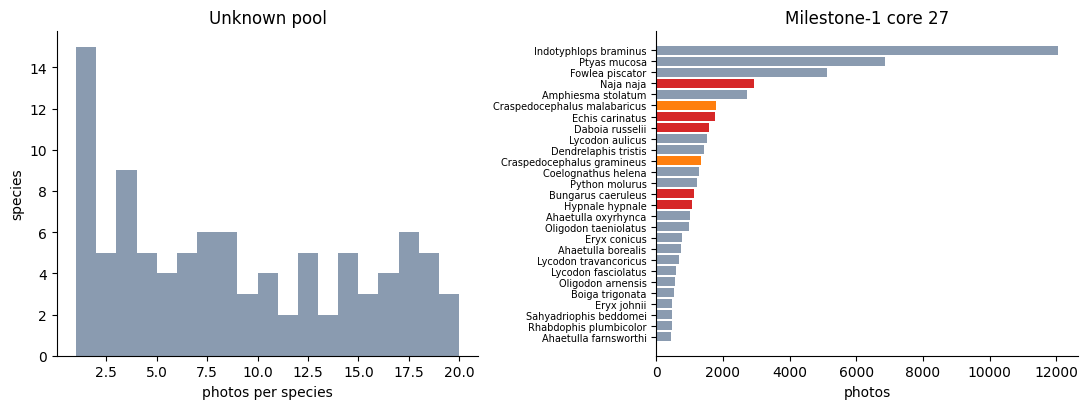

In [55]:
tab_unk_n = meta[meta["tier"] == "unknown_pool"].groupby("species").size()
check("every unknown-pool species has fewer photos than the smallest class", tab_unk_n.max() < classes["total"].min(), f"{tab_unk_n.max()} vs {classes['total'].min()}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].hist(tab_unk_n, bins=range(1, int(tab_unk_n.max()) + 2), color="#8a9bb0")
ax[0].set(xlabel="photos per species", ylabel="species", title="Unknown pool")
tab_c = tab_core.sort_values("total")
ax[1].barh(tab_c["species"], tab_c["total"], color=[WHO_COLORS[w] for w in tab_c["who_category"]])
ax[1].set(xlabel="photos", title="Milestone-1 core 27"); ax[1].tick_params(axis="y", labelsize=7)
savefig("02_tiers"); plt.close()

Unknown-pool species have only a few photos each, so they can't be trained as classes, but they are useful later as examples of snakes the model has never been taught. The core 27 are all well covered.

## 3. Splits and leakage
The photos are split into train, val, test, test_extra and the unknown pool. Let's check that the split is balanced per class, and that no observer, observation or image shows up on both sides of a split.

### 3.1 Per-class split balance
For every class we take its share of photos in each split. If the split was done evenly, these shares should be similar from class to class.

In [56]:
tab_share = tab_cls[tab_cols].div(tab_cls[tab_cols].sum(axis=1), axis=0)
tab_share_long = tab_share.reset_index().melt(id_vars="species", var_name="split", value_name="share").merge(classes[["species", "who_category", "total"]], on="species")
print("median share of a class's photos in each split:", (100 * tab_share.median()).round(1).to_dict())
tab_share.describe().loc[["mean", "std", "min", "max"]].round(3)

median share of a class's photos in each split: {'train': 70.7, 'val': 14.4, 'test': 6.2, 'test_extra': 7.7}


,train,val,test,test_extra
mean,0.711,0.137,0.067,0.085
std,0.073,0.055,0.065,0.063
min,0.400,0.000,0.000,0.000
max,1.000,0.360,0.404,0.292


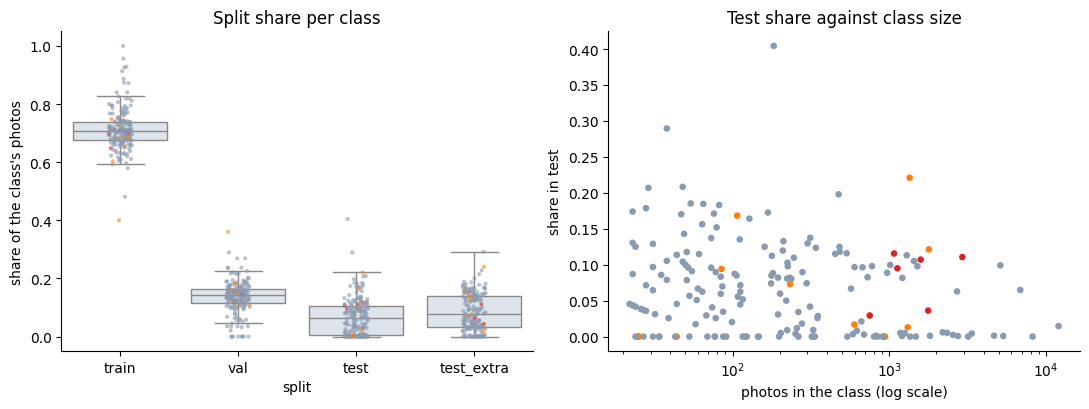

In [57]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
sns.boxplot(data=tab_share_long, x="split", y="share", color="#dbe4ee", fliersize=0, ax=ax[0])
sns.stripplot(data=tab_share_long, x="split", y="share", hue="who_category", palette=WHO_COLORS, size=3, alpha=0.6, legend=False, ax=ax[0])
ax[0].set(ylabel="share of the class's photos", title="Split share per class")
tab_t = tab_share_long[tab_share_long["split"] == "test"]
ax[1].scatter(tab_t["total"], tab_t["share"], c=[WHO_COLORS[w] for w in tab_t["who_category"]], s=14)
ax[1].set(xscale="log", xlabel="photos in the class (log scale)", ylabel="share in test", title="Test share against class size")
savefig("03_split_balance"); plt.close()

The train share is steady for big classes and varies more only for small ones. The test share jumps around at every class size: some classes get about a tenth of their photos in test and many get none. That fits the test rule in 3.4: only India photos uploaded in 2022 or later can go to test, so a class with few such photos ends up with little or no test data.

### 3.2 WHO share per split

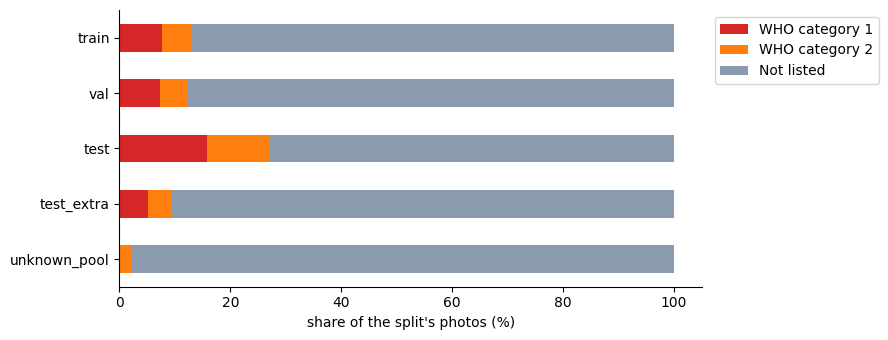

who_category,1,2,not_listed
split,,,
train,7.60,5.27,87.12
val,7.38,5.04,87.58
test,15.77,11.37,72.86
test_extra,5.16,4.08,90.76
unknown_pool,0.00,2.33,97.67


In [58]:
tab_ws = pd.crosstab(meta["split"], meta["who_category"], normalize="index").reindex(SPLIT_ORDER)[["1", "2", "not_listed"]] * 100
ax = tab_ws.plot.barh(stacked=True, color=[WHO_COLORS[c] for c in tab_ws.columns], figsize=(9, 3.5))
ax.set(xlabel="share of the split's photos (%)", ylabel=""); ax.invert_yaxis(); ax.legend([WHO_LABEL[c] for c in tab_ws.columns], bbox_to_anchor=(1.01, 1), loc="upper left")
savefig("03_who_per_split"); plt.close()
tab_ws.round(2)

Train and val have almost the same WHO mix. Test has a clearly larger share of category 1 and 2 photos than train, because India is where those snakes are most photographed, and test_extra has a smaller share. So a test score weighs the dangerous snakes more than a val score does.

### 3.3 Classes with no test photos

In [59]:
tab_zero = classes[classes["test"] == 0]
print(f"{len(tab_zero)} of {len(classes)} classes have no test photos; {(tab_zero['who_category'] != 'not_listed').sum()} of them are in WHO category 1 or 2")
print(f"{((classes['test'] == 0) & (classes['test_extra'] == 0)).sum()} classes have neither test nor test_extra photos, {(classes['val'] == 0).sum()} has no val photos")
check("36 classes have no test photos", len(tab_zero) == 36, f"{len(tab_zero)} found")
tab_zero.sort_values("total", ascending=False).set_index("species")[["who_category", "tier", "train", "val", "test_extra"]]

36 of 184 classes have no test photos; 3 of them are in WHO category 1 or 2
3 classes have neither test nor test_extra photos, 8 has no val photos
PASS  36 classes have no test photos  (36 found)


,who_category,tier,train,val,test_extra
species,,,,,
Ahaetulla prasina,not_listed,tier1,5847,1167,1206
Malayopython reticulatus,not_listed,tier1,2260,472,454
Xenopeltis unicolor,not_listed,tier1,997,230,249
Gonyosoma oxycephalum,not_listed,tier1,1002,167,188
Macrovipera lebetinus,2,tier1,709,115,116
Xenochrophis trianguligerus,not_listed,tier1,671,90,151
Pareas carinatus,not_listed,tier1,620,138,150
Laticauda laticaudata,not_listed,tier1,610,114,116
Coelognathus flavolineatus,not_listed,tier1,571,95,133


For these classes the test score cannot be computed. Most of them still have val and test_extra photos, so they can be checked there, with the caveat that those photos don't follow the test rule.

### 3.4 The test rule: India, uploaded 2022-01-01 or later

In [60]:
tab_cut = pd.Timestamp("2022-01-01", tz="UTC")
tab_rule = meta.groupby("split").agg(photos=("photo_id", "size"), in_india=("in_india", "mean"), uploaded_2022_or_later=("created_at", lambda s: (s >= tab_cut).mean()))
tab_rule = (100 * tab_rule[["in_india", "uploaded_2022_or_later"]]).round(1).join(tab_rule["photos"]).reindex(SPLIT_ORDER)
tab_test = meta[meta["split"] == "test"]
tab_viol = (~tab_test["in_india"]) | (tab_test["created_at"] < tab_cut)
check("every test photo is in India and uploaded 2022-01-01 or later", tab_viol.sum() == 0, f"{int(tab_viol.sum())} violations in {len(tab_test):,} photos")
tab_rule.rename(columns={"in_india": "in India %", "uploaded_2022_or_later": "uploaded 2022+ %"})

PASS  every test photo is in India and uploaded 2022-01-01 or later  (0 violations in 5,144 photos)


,in India %,uploaded 2022+ %,photos
split,,,
train,37.4,83.7,85067
val,37.1,81.3,17151
test,100.0,100.0,5144
test_extra,14.7,68.3,13389
unknown_pool,82.2,83.8,815


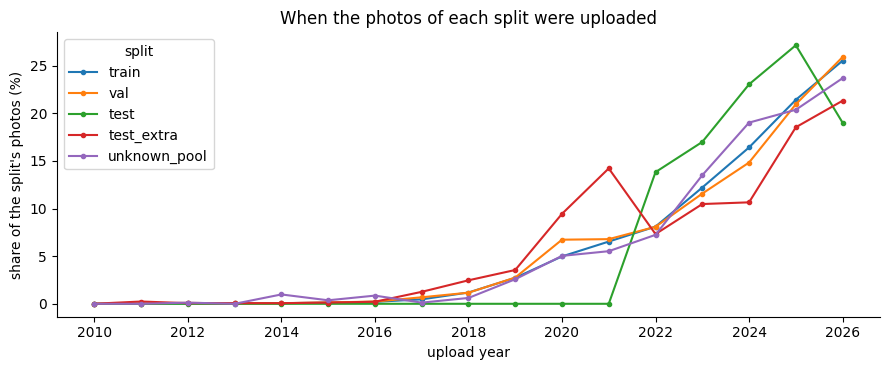

In [61]:
tab_up = pd.crosstab(meta["created_at"].dt.year, meta["split"], normalize="columns").reindex(columns=SPLIT_ORDER) * 100
ax = tab_up.plot(figsize=(9, 3.8), marker="o", ms=3)
ax.set(xlabel="upload year", ylabel="share of the split's photos (%)", title="When the photos of each split were uploaded")
savefig("03_upload_year"); plt.close()

Uploads grow fast over the years in every split, so most photos everywhere are recent. The difference is that test is cut at 2022 and holds India only, while train and val also hold older uploads and many photos from outside India. test_extra does not follow the rule, which is why it is kept apart.

### 3.5 Overlap between splits
A photo, an observation or an observer must not appear on both sides of a split. We count the shared values of four keys for every pair among train, val and test.

In [62]:
def tab_overlap(col, splits):
    sets = {s: set(meta.loc[meta["split"] == s, col]) for s in splits}
    return {f"{a} and {b}": len(sets[a] & sets[b]) for a, b in itertools.combinations(splits, 2)}

tab_leak = pd.DataFrame({col: tab_overlap(col, ["train", "val", "test"]) for col in ["observer_id", "obs_id", "sha1", "phash"]})
tab_leak

,observer_id,obs_id,sha1,phash
train and val,0,0,0,0
train and test,0,0,0,0
val and test,0,0,0,0


In [63]:
for col in tab_leak.columns:
    check(f"no {col} shared between train, val and test", tab_leak[col].sum() == 0, f"{tab_leak[col].sum()} shared")

PASS  no observer_id shared between train, val and test  (0 shared)
PASS  no obs_id shared between train, val and test  (0 shared)
PASS  no sha1 shared between train, val and test  (0 shared)
PASS  no phash shared between train, val and test  (0 shared)


For information, the same count when test_extra and the unknown pool are included. Only the pairs with a shared value are listed. These two splits are not part of the leakage rule.

In [64]:
tab_leak_all = pd.DataFrame({col: tab_overlap(col, ["train", "val", "test", "test_extra", "unknown_pool"]) for col in ["observer_id", "obs_id", "sha1", "phash"]})
tab_leak_all[tab_leak_all.sum(axis=1) > 0]

,observer_id,obs_id,sha1,phash
train and unknown_pool,147,0,0,2
val and unknown_pool,32,0,0,0
test and test_extra,73,0,0,0
test and unknown_pool,28,0,0,0
test_extra and unknown_pool,19,0,0,0


### 3.6 Beyond the split rule
The splits share no observer, observation, file hash or exact picture hash. That is a strict test, but it only catches identical copies. Two more questions: are there near-copies of training photos in val and test, and does the test set look like the training set in other ways such as country, photo shape and number of photographers?

#### Near-copies across splits
For every val, test and test_extra photo I look for the closest training photo by picture hash. Distance 0 is an identical hash. A few bits apart usually means the same scene, cropped or resized.

In [65]:
tab_hash = meta["phash"].map(lambda h: int(h, 16)).to_numpy(dtype=np.uint64)
tab_is_train = (meta["split"] == "train").to_numpy()
tab_train_hash = tab_hash[tab_is_train]
tab_train_species = meta.loc[tab_is_train, "species"].to_numpy()
len(tab_train_hash)

85067

In [66]:
def popcount(x):
    if hasattr(np, "bitwise_count"):
        return np.bitwise_count(x)
    bytes_view = np.ascontiguousarray(x).view(np.uint8).reshape(*x.shape, 8)
    return np.unpackbits(bytes_view, axis=-1).sum(axis=-1)

In [67]:
def nearest_train(query, step=128):
    best = np.zeros(len(query), dtype=int)
    arg = np.zeros(len(query), dtype=int)
    for i in range(0, len(query), step):
        d = popcount(query[i:i + step, None] ^ tab_train_hash[None, :])
        best[i:i + step], arg[i:i + step] = d.min(axis=1), d.argmin(axis=1)
    return best, arg

In [68]:
tab_near_rows = []
for name in ["val", "test", "test_extra"]:
    q = meta[meta["split"] == name]
    q = q.sample(min(len(q), 1500), random_state=SEED) if SMOKE else q
    qh = q["phash"].map(lambda h: int(h, 16)).to_numpy(dtype=np.uint64)
    dist, arg = nearest_train(qh)
    same = q["species"].to_numpy() == tab_train_species[arg]
    tab_near_rows.append({"split": name, "photos": len(q), "identical": int((dist == 0).sum()),
                          "within 2 bits": int((dist <= 2).sum()), "within 4 bits": int((dist <= 4).sum()),
                          "within 4 bits, same species": int(((dist <= 4) & same).sum())})
tab_near = pd.DataFrame(tab_near_rows).set_index("split")
tab_near

,photos,identical,within 2 bits,within 4 bits,"within 4 bits, same species"
split,,,,,
val,17151,0,0,0,0
test,5144,0,0,0,0
test_extra,13389,0,0,0,0


In [69]:
check("no val/test photo has an identical hash in train", tab_near["identical"].sum() == 0)
close = int(tab_near["within 2 bits"].sum())
print(f"{close} val/test photos are not identical to a training photo but sit within 2 bits of one")

PASS  no val/test photo has an identical hash in train
0 val/test photos are not identical to a training photo but sit within 2 bits of one


The dataset notebook drops a val or test photo within 4 bits of a photo in an earlier split, so nothing should be left within 2 or 4 bits. The table confirms it.

#### Country and danger level
The test set is India only by rule, but training photos also come from other countries. If danger level and country are linked in training, a model can read the scenery as a hint, and that hint is useless on an all-India test set.

In [70]:
tab_india = (meta[meta["split"].isin(SPLIT_ORDER[:4])].groupby(["split", "who_category"])["in_india"]
             .mean().unstack().mul(100).round(1).reindex(SPLIT_ORDER[:4]))
tab_india.rename(columns=WHO_LABEL)

who_category,WHO category 1,WHO category 2,Not listed
split,,,
train,77.8,53.4,33.0
val,76.2,65.3,32.2
test,100.0,100.0,100.0
test_extra,49.8,23.1,12.3


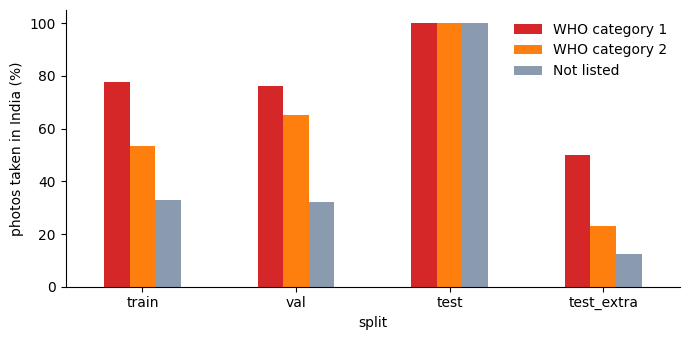

In [71]:
tab_india.plot(kind="bar", color=[WHO_COLORS[c] for c in tab_india.columns], figsize=(7, 3.5))
plt.ylabel("photos taken in India (%)")
plt.xticks(rotation=0)
plt.legend([WHO_LABEL[c] for c in tab_india.columns], frameon=False)
savefig("03b_india_share")
plt.close()

In training, 78% of category 1 photos and 53% of category 2 photos were taken in India, but only 33% of the not-listed ones. So in training, "looks like India" is a weak hint for "dangerous". The test set is all India, so that hint cannot help there. test_extra is the opposite and is mostly non-India.

#### Photo shape
Phones and cameras produce different shapes. If test photos are mostly portrait and training photos mostly landscape, random crops and flips in training will not cover what the test set looks like.

In [72]:
tab_shape = np.select([meta["height"] > meta["width"], meta["height"] < meta["width"]], ["portrait", "landscape"], "square")
tab_shape_share = pd.crosstab(meta["split"], tab_shape, normalize="index").mul(100).round(1)
tab_shape_share.reindex(SPLIT_ORDER[:4])

col_0,landscape,portrait,square
split,,,
train,58.4,39.5,2.1
val,58.4,39.5,2.2
test,38.5,60.3,1.2
test_extra,62.9,35.1,1.9


Training is mostly landscape (58%), test is mostly portrait (60%). Most of that lean comes from one photographer, who took 28% of test and shoots almost only in portrait. Flips do not change that. Rotating by 90 degrees or cropping so that both shapes are covered would help, and validation accuracy should be reported for portrait photos on their own.

#### Photographers per class
Every photographer has a style, a camera and favourite places. When a class has only a few photographers a model can learn the person instead of the snake, and a test class with few photographers gives a noisy score.

In [73]:
tab_obs_train = meta[meta["split"] == "train"].groupby("species")["observer_id"].nunique()
tab_obs_test = meta[meta["split"] == "test"].groupby("species")["observer_id"].nunique()
tab_n_le5 = int((tab_obs_train <= 5).sum())
tab_n_test_le3 = int((tab_obs_test <= 3).sum())
print(f"{tab_n_le5} of {len(tab_obs_train)} classes have 5 or fewer training photographers")
print(f"{tab_n_test_le3} of {len(tab_obs_test)} classes with test photos have 3 or fewer test photographers")

7 of 184 classes have 5 or fewer training photographers
71 of 148 classes with test photos have 3 or fewer test photographers


In [74]:
tab_test_view = pd.DataFrame({"test photos": meta[meta["split"] == "test"].groupby("species").size(),
                              "test photographers": tab_obs_test}).sort_values(["test photographers", "test photos"])
tab_test_view.head(10)

,test photos,test photographers
species,,
Ahaetulla laudankia,1,1
Boiga dightoni,1,1
Boiga multomaculata,1,1
Bungarus andamanensis,1,1
Lycodon fasciatus,1,1
Oligodon cinereus,1,1
Oreocryptophis porphyraceus,1,1
Platyceps josephi,1,1
Platyplectrurus madurensis,1,1


Only 7 of the 184 classes have five photographers or fewer in training, so photographer style is not a big worry on that side. The test side is thinner: 71 of the 148 classes with test photos have three photographers or fewer, and the ten smallest have one photo from one person. A test score for those classes says something about a single photo, so confidence intervals should be built by photographer and not by photo.

#### Several photos of the same sighting
One observation can carry up to five photos. They show the same animal, so they are not independent. The split keeps all photos of an observation together, which is why the observation overlap above is zero.

In [75]:
tab_per_obs = meta.groupby("obs_id").size()
tab_multi = tab_per_obs[tab_per_obs > 1]
print(f"{len(tab_per_obs):,} observations, {len(tab_multi):,} with more than one photo")
print(f"{100 * tab_multi.sum() / len(meta):.1f}% of photos belong to a multi-photo observation")

62,772 observations, 25,358 with more than one photo
69.2% of photos belong to a multi-photo observation


About two thirds of the photos come from observations with several photos, so they are far from independent. Because the split groups by observer, they stay on one side. Any validation split made inside the training set has to group by observation or observer as well, never by photo.

#### Subspecies and renamed species
The label is `species`. The column `record_taxon` keeps what the observer's identification said, which can be a subspecies or an older name.

In [76]:
tab_renamed = meta[meta["record_taxon"].notna() & (meta["record_taxon"] != meta["species"])]
print(f"{len(tab_renamed):,} photos ({100 * len(tab_renamed) / len(meta):.1f}%) have a record_taxon that differs from the label")
tab_renamed.groupby(["record_taxon", "species"]).size().sort_values(ascending=False).head(10)

6,099 photos (5.0%) have a record_taxon that differs from the label


record_taxon                             species                     
Coelognathus helena helena               Coelognathus helena             649
Echis carinatus sochureki                Echis carinatus                 633
Macrovipera lebetinus obtusa             Macrovipera lebetinus           460
Elaphe taeniura friesi                   Elaphe taeniura                 446
Oreocryptophis porphyraceus vaillanti    Oreocryptophis porphyraceus     416
Coelognathus helena monticollaris        Coelognathus helena             400
Oreocryptophis porphyraceus kawakamii    Oreocryptophis porphyraceus     342
Echis carinatus carinatus                Echis carinatus                 256
Psammodynastes pulverulentus papenfussi  Psammodynastes pulverulentus    220
Rhabdophis plumbicolor plumbicolor       Rhabdophis plumbicolor          190
dtype: int64

About one photo in twenty carries a subspecies name, for example *Coelognathus helena helena* and *Echis carinatus sochureki*. Folding subspecies into the species is right for a 184-class model, but it means a few classes mix forms that look quite different, so errors inside those classes need a second look before we blame the model.

## 4. Images: every photo, from the metadata
The table stores width, height and file size for all 121k photos, so we can describe the images without opening them. Looking at pixels comes in the next section, on a sample.

### 4.1 Width, height and file size

In [77]:
tab_img = meta[["photo_id", "species", "split", "who_category", "width", "height", "bytes", "url", "license", "cc_licensed"]].copy()
tab_img["short"] = tab_img[["width", "height"]].min(axis=1)
tab_img["long"] = tab_img[["width", "height"]].max(axis=1)
tab_img["aspect"] = tab_img["width"] / tab_img["height"]
tab_img["pixels"] = tab_img["width"] * tab_img["height"]
tab_img["bpp"] = tab_img["bytes"] / tab_img["pixels"]
tab_img["host"] = tab_img["url"].str.extract(r"//([^/]+)/")[0]
tab_img["url_ext"] = tab_img["url"].str.extract(r"\.(\w+)$")[0].str.lower()
tab_img.drop(columns=["url", "license"]).describe(percentiles=[0.01, 0.5, 0.99]).T.round(2)[["min", "1%", "50%", "99%", "max"]]

,min,1%,50%,99%,max
width,116.00,225.00,500.00,500.00,500.00
height,100.00,225.00,375.00,500.00,500.00
bytes,5059.00,21221.65,127093.50,322911.50,26155648.00
short,100.00,225.00,375.00,500.00,500.00
long,121.00,500.00,500.00,500.00,500.00
aspect,0.24,0.45,1.33,2.22,5.00
pixels,13794.00,112500.00,187500.00,250000.00,250000.00
bpp,0.03,0.13,0.74,1.77,154.71


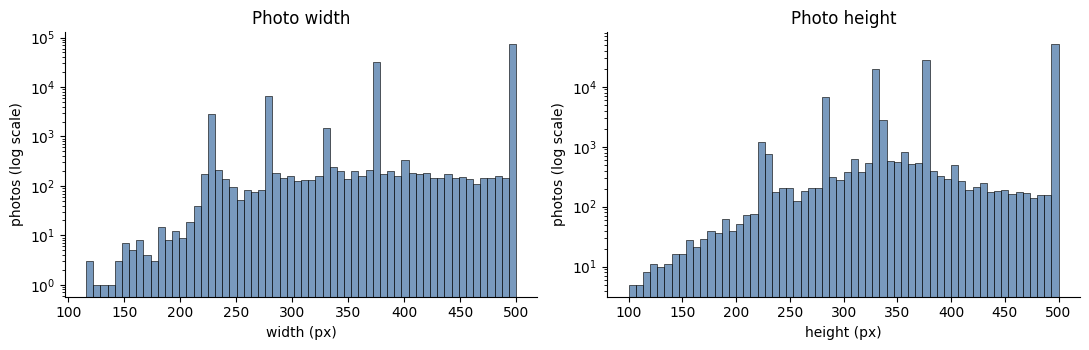

In [78]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, col in zip(ax, ["width", "height"]):
    sns.histplot(tab_img[col], bins=60, color="#4c78a8", ax=a)
    a.set(yscale="log", xlabel=f"{col} (px)", ylabel="photos (log scale)", title=f"Photo {col}")
savefig("04_width_height"); plt.close()

Both width and height pile up at 500, with the rest spread below it: landscape photos are 500 wide and portrait photos are 500 tall. The y-axis is logarithmic so that the small bars stay visible. This looks like a resize that caps the long side.

### 4.2 Aspect ratio and orientation

orientation share %: {'landscape': 57.9, 'portrait': 39.6, 'square': 2.5}


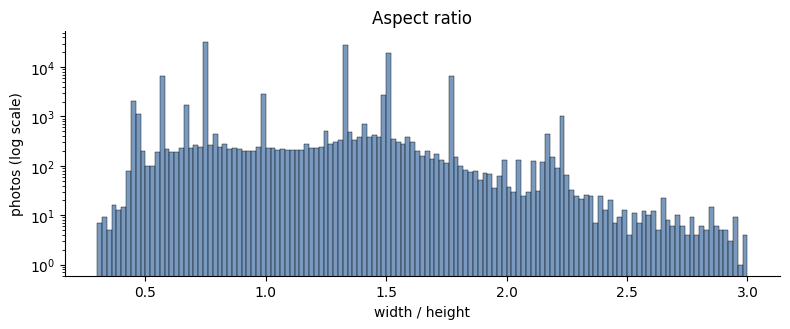

In [79]:
tab_ori = np.where(tab_img["aspect"] > 1.02, "landscape", np.where(tab_img["aspect"] < 0.98, "portrait", "square"))
print("orientation share %:", (100 * pd.Series(tab_ori).value_counts(normalize=True)).round(1).to_dict())
fig, ax = plt.subplots(figsize=(8, 3.4))
sns.histplot(tab_img["aspect"], bins=np.arange(0.3, 3.01, 0.02), color="#4c78a8", ax=ax)
ax.set(yscale="log", xlabel="width / height", ylabel="photos (log scale)", title="Aspect ratio")
savefig("04_aspect"); plt.close()

In [80]:
tab_asp = tab_img["aspect"].round(2).value_counts().head(8).to_frame("photos")
tab_asp["share %"] = (100 * tab_asp["photos"] / len(tab_img)).round(1)
tab_asp

,photos,share %
aspect,,
0.75,31366,25.8
1.33,27861,22.9
1.50,20411,16.8
0.56,6577,5.4
1.78,6047,5.0
1.00,2713,2.2
0.45,1748,1.4
0.67,1468,1.2


Camera shapes show up as spikes: a ratio of 1.33 is 4:3, 1.5 is 3:2 and 1.78 is 16:9, while 0.75, 0.67 and 0.56 are the same shapes held upright. A model has to deal with both landscape and portrait photos, so a plain square resize would distort many of them.

### 4.3 How many photos are small?
Many models take 224 px inputs, so let's count the photos whose short side is below 224, 256 and 320.

In [81]:
tab_small_share = pd.Series({t: (tab_img["short"] < t).mean() for t in (224, 256, 320)})
print("share of photos with the short side below each size (%):", (100 * tab_small_share).round(1).to_dict())
check("short side under 224 px for 0.7% of photos", round(100 * tab_small_share[224], 1) == 0.7)
check("short side under 256 px for 5.5% of photos", round(100 * tab_small_share[256], 1) == 5.5)
check("short side under 320 px for 19.5% of photos", round(100 * tab_small_share[320], 1) == 19.5)

share of photos with the short side below each size (%): {224: 0.7, 256: 5.5, 320: 19.5}
PASS  short side under 224 px for 0.7% of photos
PASS  short side under 256 px for 5.5% of photos
PASS  short side under 320 px for 19.5% of photos


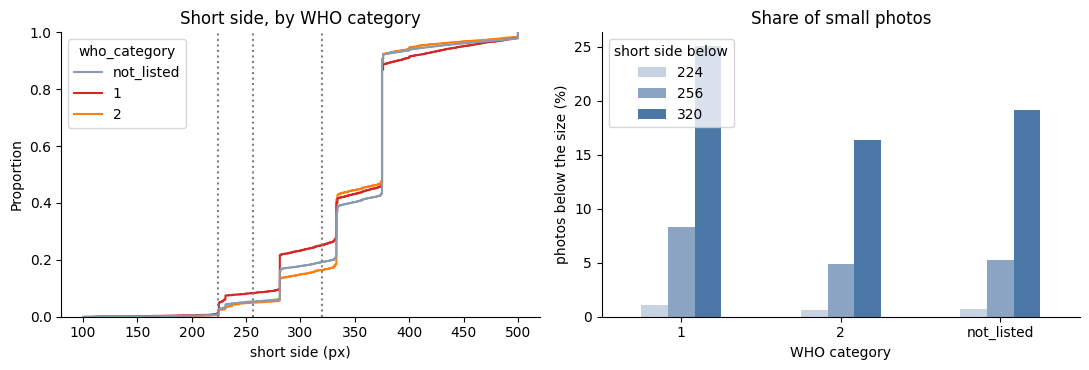

In [82]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.ecdfplot(data=tab_img, x="short", hue="who_category", palette=WHO_COLORS, ax=ax[0])
for t in (224, 256, 320):
    ax[0].axvline(t, color="grey", ls=":")
ax[0].set(xlabel="short side (px)", title="Short side, by WHO category")
tab_by = pd.DataFrame({t: tab_img.groupby("who_category")["short"].apply(lambda s, t=t: 100 * (s < t).mean()) for t in (224, 256, 320)})
tab_by.reindex(["1", "2", "not_listed"]).plot.bar(ax=ax[1], rot=0, color=["#c7d3e0", "#8aa4c1", "#4c78a8"])
ax[1].set(xlabel="WHO category", ylabel="photos below the size (%)", title="Share of small photos"); ax[1].legend(title="short side below", loc="upper left")
savefig("04_short_side"); plt.close()

The three curves have the same stair shape, with steps at the common camera sizes. Category 1 sits a little above the other two, so it has a somewhat larger share of small photos, but the gap is a few points. The dotted lines mark the three cut-offs used above.

### 4.4 The long side

In [83]:
tab_ls = tab_img["long"].value_counts()
print(f"long side exactly 500 px: {(tab_img['long'] == 500).mean():.2%}; below 500: {(tab_img['long'] < 500).sum():,}; above 500: {(tab_img['long'] > 500).sum():,}")
check("99.6% of photos have a long side of exactly 500 px", round(100 * (tab_img["long"] == 500).mean(), 1) == 99.6)
tab_img[tab_img["long"] < 500].groupby("url_ext").agg(photos=("photo_id", "size"), median_long_side=("long", "median"), median_short_side=("short", "median"))

long side exactly 500 px: 99.63%; below 500: 449; above 500: 0
PASS  99.6% of photos have a long side of exactly 500 px


,photos,median_long_side,median_short_side
url_ext,,,
gif,16,426.0,240.0
jpeg,156,405.0,325.0
jpg,257,408.0,301.0
png,20,423.0,246.0


Every address in the `url` column points to iNaturalist's "medium" size, which caps the long side at 500 px, so the few photos below that are smaller originals that were not enlarged. No photo is bigger than 500 px, which is small compared with what many models take as input.

### 4.5 File size

{'count': 121566.0, 'mean': 131.5, 'std': 150.8, 'min': 4.9, '1%': 20.7, '50%': 124.1, '99%': 315.3, 'max': 25542.6}
all photos together: 16.4 GB; the 100 largest files hold 1.6% of the bytes
PASS  the largest file is about 26 MB  (26.2 MB)


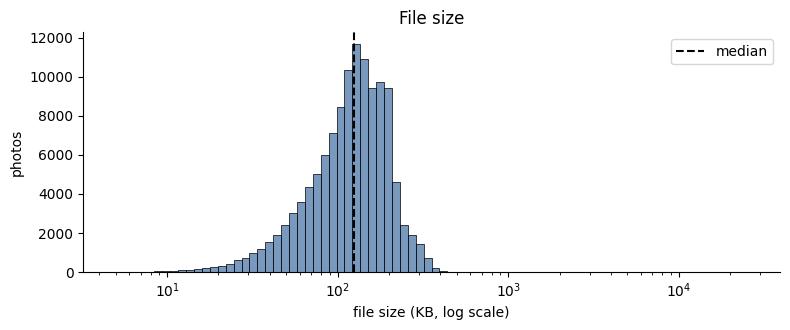

In [84]:
tab_kb = tab_img["bytes"] / 1024
print(tab_kb.describe(percentiles=[0.01, 0.5, 0.99]).round(1).to_dict())
print(f"all photos together: {tab_img['bytes'].sum() / 1e9:.1f} GB; the 100 largest files hold {tab_img['bytes'].nlargest(100).sum() / tab_img['bytes'].sum():.1%} of the bytes")
check("the largest file is about 26 MB", round(tab_img["bytes"].max() / 1e6) == 26, f"{tab_img['bytes'].max() / 1e6:.1f} MB")
fig, ax = plt.subplots(figsize=(8, 3.4))
sns.histplot(tab_kb, bins=80, log_scale=True, color="#4c78a8", ax=ax)
ax.axvline(tab_kb.median(), color="k", ls="--", label="median"); ax.legend()
ax.set(xlabel="file size (KB, log scale)", ylabel="photos", title="File size")
savefig("04_file_size"); plt.close()

Most files are around a hundred KB, but the right tail reaches far beyond what a 500 px JPEG should need. Let's look at bytes per pixel, which takes the image size out of the picture.

### 4.6 Bytes per pixel and the outliers

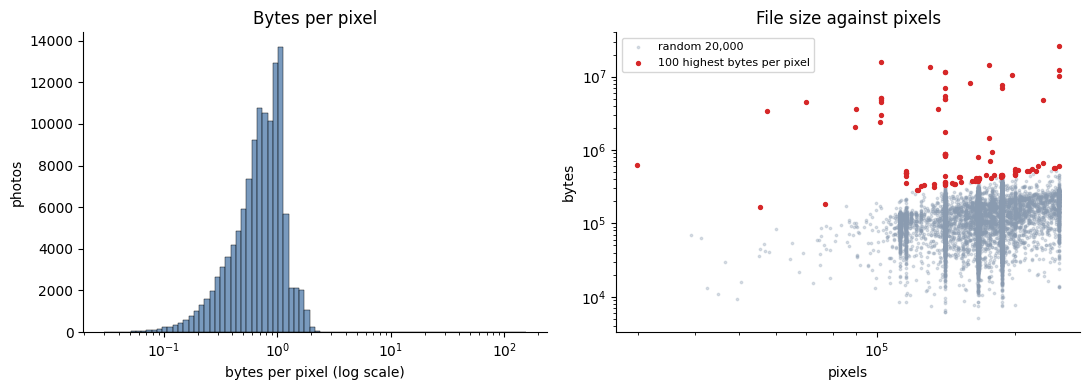

In [85]:
tab_s = tab_img.sample(20000, random_state=SEED)
tab_worst = tab_img.nlargest(100, "bpp")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(tab_img["bpp"], bins=80, log_scale=True, color="#4c78a8", ax=ax[0])
ax[0].set(xlabel="bytes per pixel (log scale)", ylabel="photos", title="Bytes per pixel")
ax[1].scatter(tab_s["pixels"], tab_s["bytes"], s=3, alpha=0.3, color="#8a9bb0", label="random 20,000")
ax[1].scatter(tab_worst["pixels"], tab_worst["bytes"], s=8, color="#d62728", label="100 highest bytes per pixel")
ax[1].set(xscale="log", yscale="log", xlabel="pixels", ylabel="bytes", title="File size against pixels"); ax[1].legend(fontsize=8)
savefig("04_bytes_per_pixel"); plt.close()

A normal JPEG sits in a tight band. The red points are far above that band: very large files for their size. Here are the worst ones.

In [86]:
tab_top = tab_img.nlargest(15, "bpp")
tab_top = tab_top.assign(MB=(tab_top["bytes"] / 1e6).round(1), bpp=tab_top["bpp"].round(1), size=tab_top["width"].astype(str) + " x " + tab_top["height"].astype(str))
tab_top[["photo_id", "species", "split", "size", "MB", "bpp", "url_ext", "host"]].set_index("photo_id")

,species,split,size,MB,bpp,url_ext,host
photo_id,,,,,,,
529154484,Elaphe taeniura,train,426 x 240,15.8,154.7,gif,inaturalist-open-data.s3.amazonaws.com
722159475,Python bivittatus,val,360 x 363,13.7,105.0,gif,inaturalist-open-data.s3.amazonaws.com
358893076,Indotyphlops braminus,val,500 x 500,26.2,104.6,gif,inaturalist-open-data.s3.amazonaws.com
420144884,Psammodynastes pulverulentus,train,500 x 282,11.6,82.2,gif,inaturalist-open-data.s3.amazonaws.com
420144851,Psammodynastes pulverulentus,train,500 x 282,11.5,81.4,gif,inaturalist-open-data.s3.amazonaws.com
336529607,Python bivittatus,val,500 x 352,14.2,80.7,gif,inaturalist-open-data.s3.amazonaws.com
267830672,Boiga cyanea,train,240 x 292,4.6,65.2,gif,inaturalist-open-data.s3.amazonaws.com
579667824,Protobothrops jerdonii,val,239 x 240,3.4,60.1,gif,inaturalist-open-data.s3.amazonaws.com
623670240,Ahaetulla prasina,train,445 x 444,10.4,52.6,gif,inaturalist-open-data.s3.amazonaws.com


Almost all of these point to a different file type in the `url` column. Every photo was saved with a `.jpg` name, but the address it was fetched from can end in `.gif` or `.png`. Let's group by the type in the address.

In [87]:
tab_ext = tab_img.groupby("url_ext").agg(photos=("photo_id", "size"), median_KB=("bytes", lambda s: s.median() / 1024), max_MB=("bytes", lambda s: s.max() / 1e6), median_bpp=("bpp", "median"))
tab_ext.round(2)
print("types among the 100 highest bytes-per-pixel files:", tab_worst["url_ext"].value_counts().to_dict())
print("type of the largest file:", tab_img.loc[tab_img["bytes"].idxmax(), "url_ext"])

types among the 100 highest bytes-per-pixel files: {'png': 64, 'gif': 32, 'jpg': 4}
type of the largest file: gif


So the largest file is a GIF, and the other extreme files are mostly PNG or GIF as well. A GIF can be an animation with many frames, which would explain the size. These files are few and make up a small part of the total bytes, but each one is slow to read. We'll keep this in mind for the image checks and for any model that reads files from disk.

### 4.7 The two image hosts
The `url` column points to two hosts: iNaturalist's open-data S3 bucket and `static.inaturalist.org`. These are two different sources of photos, so let's see whether they differ.

In [88]:
tab_host = pd.crosstab(tab_img["host"], tab_img["cc_licensed"])
tab_host["share of photos %"] = (100 * tab_host.sum(axis=1) / len(tab_img)).round(1)
tab_host

cc_licensed,True,share of photos %
host,,
inaturalist-open-data.s3.amazonaws.com,121562,100.0
static.inaturalist.org,4,0.0


In [89]:
tab_hg = tab_img.groupby("host").agg(photos=("photo_id", "size"), median_width=("width", "median"), median_height=("height", "median"), median_KB=("bytes", lambda s: s.median() / 1024),
                                      median_bpp=("bpp", "median"), under_224_pct=("short", lambda s: 100 * (s < 224).mean()), non_jpg_pct=("url_ext", lambda s: 100 * (~s.isin(["jpg", "jpeg"])).mean()))
tab_hg.round(2)

,photos,median_width,median_height,median_KB,median_bpp,under_224_pct,non_jpg_pct
host,,,,,,,
inaturalist-open-data.s3.amazonaws.com,121562,500.0,375.0,124.12,0.74,0.7,0.33
static.inaturalist.org,4,500.0,332.0,101.68,0.63,0.0,0.00


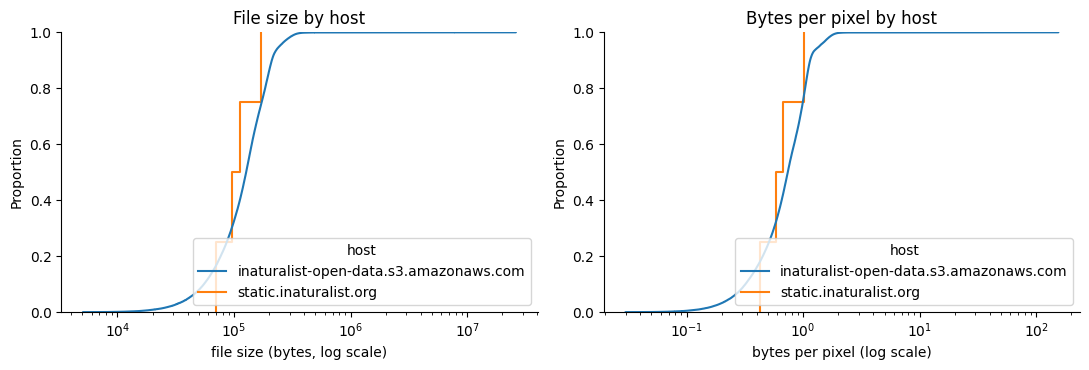

In [90]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.ecdfplot(data=tab_img, x="bytes", hue="host", log_scale=True, ax=ax[0])
sns.ecdfplot(data=tab_img, x="bpp", hue="host", log_scale=True, ax=ax[1])
ax[0].set(xlabel="file size (bytes, log scale)", title="File size by host"); ax[1].set(xlabel="bytes per pixel (log scale)", title="Bytes per pixel by host")
savefig("04_hosts"); plt.close()

If the two hosts had different image processing, the curves would separate. They lie close together, so the host mostly tells us which licence a photo has, not how it looks.

In [91]:
tab_a, tab_b = [g["bytes"].values for _, g in tab_img.groupby("host")]
tab_u = stats.mannwhitneyu(tab_a, tab_b, alternative="two-sided")
print(f"probability that a photo from the first host is larger than one from the second: {tab_u.statistic / (len(tab_a) * len(tab_b)):.3f} (0.5 means no difference)")
print(f"median file size: {np.median(tab_a) / 1024:.0f} KB against {np.median(tab_b) / 1024:.0f} KB")

probability that a photo from the first host is larger than one from the second: 0.597 (0.5 means no difference)
median file size: 124 KB against 102 KB


### 4.8 CC-licensed against other photos
`cc_licensed` is true for photos under any Creative Commons licence. Let's make the same comparison and see how much it overlaps with the host split.

In [92]:
tab_cg = tab_img.groupby("cc_licensed").agg(photos=("photo_id", "size"), median_width=("width", "median"), median_height=("height", "median"), median_KB=("bytes", lambda s: s.median() / 1024),
                                             median_bpp=("bpp", "median"), under_224_pct=("short", lambda s: 100 * (s < 224).mean()))
tab_cg.round(2)

,photos,median_width,median_height,median_KB,median_bpp,under_224_pct
cc_licensed,,,,,,
True,121566,500.0,375.0,124.11,0.74,0.7


In [93]:
tab_agree = ((tab_img["host"] == "inaturalist-open-data.s3.amazonaws.com") == tab_img["cc_licensed"]).mean()
print(f"the host and the cc_licensed flag agree for {tab_agree:.3%} of the photos")
print("cc share by split (%):", (100 * tab_img.groupby("split")["cc_licensed"].mean()).round(1).to_dict())

the host and the cc_licensed flag agree for 99.997% of the photos
cc share by split (%): {'test': 100.0, 'test_extra': 100.0, 'train': 100.0, 'unknown_pool': 100.0, 'val': 100.0}


The two groupings describe almost the same photos, so the host comparison and the licence comparison give the same answer. The photos we can show in this notebook (CC only) look just like the rest in size and compression, so what we see in the grids is representative of the files.

## 5. Looking at the images
So far we only used the tables. Now we open real photos and measure them. Reading all 121k files would take far too long, so we work with a sample: up to 30 photos per species, drawn at random with a fixed seed.

For each photo we measure size, brightness, contrast, colourfulness, sharpness, saturation, orientation and the number of faces. We also recompute the perceptual hash and compare it with the stored one.

Every picture in this section is a CC0 or CC BY photo, with the photographer credit in a table under the grid. CC BY-NC is only a fallback when there are too few of those, and the table says so. Photos with a detected person are not shown: the grids pick photos without a detected face, and a note is printed if that is not possible.

### 5.1 The sample
`sample_ids` takes the same number of photos from every species, so rare species are much better represented than in the full table. That suits a per-class look at image quality, but it also means shares in the sample are not the shares in the dataset.

In [94]:
img_sample = sample_ids(meta, SAMPLE_PER_CLASS).copy()
print(f"{len(img_sample):,} photos from {img_sample['species'].nunique()} species")
img_sample["split"].value_counts()

6,249 photos from 281 species


split
train           3893
unknown_pool     815
val              700
test_extra       480
test             361
Name: count, dtype: int64

Let's compare the WHO mix of the sample with the mix of the whole dataset.

In [95]:
mix = pd.DataFrame({
    "sample": img_sample["who_category"].value_counts(normalize=True),
    "all photos": meta["who_category"].value_counts(normalize=True),
})
mix.round(3)

,sample,all photos
who_category,,
1,0.029,0.076
2,0.050,0.053
not_listed,0.921,0.871


### 5.2 Measuring each photo
What we compute for every photo:

| measure | how |
|---|---|
| width, height | pixels, read from the file itself |
| brightness | mean of the grey image (0 is black, 255 is white) |
| contrast | standard deviation of the grey image |
| colourfulness | Hasler and Süsstrunk measure, built from the red-green and yellow-blue differences |
| sharpness | variance of the Laplacian of the grey image, after resizing the long side to 256 px so big and small photos can be compared |
| saturation | mean HSV saturation, from 0 to 1 |
| orientation | landscape, portrait or square, from width and height |
| faces | number of faces found on a copy with a 320 px long side |
| pHash | recomputed with the same function the dataset notebook used |

In [96]:
import io
import time
import threading
from concurrent.futures import ThreadPoolExecutor

import cv2
import requests
from scipy.stats import kruskal
from tqdm import tqdm
from PIL import ImageDraw, ImageFont
from IPython.display import Image as ShowImage, Markdown, display

cv2.setNumThreads(1)

First the plain pixel measures. Colourfulness follows the Hasler and Süsstrunk formula. For sharpness every photo is brought to a 256 px long side first, because the Laplacian variance grows with resolution.

In [97]:
def img_fit(pic, side):
    scale = side / max(pic.shape[:2])
    how = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    return cv2.resize(pic, None, fx=scale, fy=scale, interpolation=how)

def img_colourfulness(arr):
    r, g, b = [arr[:, :, i].astype(np.float32) for i in range(3)]
    rg, yb = r - g, 0.5 * (r + g) - b
    spread = np.hypot(rg.std(), yb.std())
    centre = np.hypot(rg.mean(), yb.mean())
    return float(spread + 0.3 * centre)

def img_sharpness(grey):
    return float(cv2.Laplacian(img_fit(grey, 256), cv2.CV_64F).var())

In [98]:
def img_stats(arr):
    grey = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
    hsv = cv2.cvtColor(arr, cv2.COLOR_RGB2HSV)
    return {
        "brightness": float(grey.mean()),
        "contrast": float(grey.std()),
        "colorfulness": img_colourfulness(arr),
        "sharpness": img_sharpness(grey),
        "saturation": float(hsv[:, :, 1].mean() / 255),
    }

People holding snakes are common in this kind of dataset, so I also count faces. The classic OpenCV Haar cascade is fast but gives many false alarms on textured scenes like scales, bark and leaves, so the first choice here is the small YuNet face detector from the OpenCV model zoo (a download of about 230 KB). If YuNet cannot be loaded, the code falls back to the Haar cascade for frontal faces. The method that was used is stored with the results.

In [99]:
IMG_HAAR_URL = "https://raw.githubusercontent.com/opencv/opencv/4.10.0/data/haarcascades/haarcascade_frontalface_default.xml"
IMG_YUNET_URL = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"

def img_download(url, name):
    path = WORK / name
    if not path.exists():
        try:
            reply = requests.get(url, timeout=30)
            reply.raise_for_status()
            path.write_bytes(reply.content)
        except Exception as err:
            print("download failed:", name, str(err)[:60])
    return path if path.exists() else None

In [100]:
def img_yunet_ok(path):
    try:
        return path is not None and cv2.FaceDetectorYN.create(str(path), "", (320, 240)) is not None
    except Exception:
        return False

def img_face_setup():
    onnx = img_download(IMG_YUNET_URL, "yunet_face.onnx") if hasattr(cv2, "FaceDetectorYN") else None
    if img_yunet_ok(onnx):
        return "yunet", onnx
    if hasattr(cv2, "CascadeClassifier"):
        xml = Path(cv2.data.haarcascades) / "haarcascade_frontalface_default.xml"
        xml = xml if xml.exists() else img_download(IMG_HAAR_URL, "haar_frontalface.xml")
        if xml and not cv2.CascadeClassifier(str(xml)).empty():
            return "haar", xml
    return "none", None

In [101]:
img_face_method, img_face_file = img_face_setup()
print("OpenCV", cv2.__version__, "| face detector:", img_face_method)
if img_face_method == "none":
    print("warning: no face detector could be loaded, so face counts are all 0 and grids cannot be screened for people")

OpenCV 4.14.0 | face detector: yunet


In [102]:
img_local = threading.local()

def img_face_model():
    if not hasattr(img_local, "model"):
        if img_face_method == "haar":
            img_local.model = cv2.CascadeClassifier(str(img_face_file))
        else:
            img_local.model = cv2.FaceDetectorYN.create(str(img_face_file), "", (320, 240), 0.9, 0.3, 5000)
    return img_local.model

In [103]:
def img_face_count(arr):
    if img_face_method == "none":
        return 0
    small, model = img_fit(arr, 320), img_face_model()
    if img_face_method == "haar":
        return len(model.detectMultiScale(cv2.cvtColor(small, cv2.COLOR_RGB2GRAY), 1.1, 8, minSize=(40, 40)))
    model.setInputSize((small.shape[1], small.shape[0]))
    found = model.detect(cv2.cvtColor(small, cv2.COLOR_RGB2BGR))[1]
    return 0 if found is None else len(found)

Now one function that does everything for one photo. A photo that cannot be read is reported instead of stopping the whole run.

In [104]:
def img_measure(row):
    try:
        pic = Image.open(img_file(row.path)).convert("RGB")
        arr = np.asarray(pic)
        out = {"photo_id": row.photo_id, "width": pic.width, "height": pic.height}
        out.update(img_stats(arr))
        out.update(face_count=img_face_count(arr), phash_new=phash64(pic))
        return out
    except Exception as err:
        return {"photo_id": row.photo_id, "error": str(err)[:80]}

A quick test on the first photo of the sample before the big run.

In [105]:
img_first = next(img_sample.itertuples())
print(img_first.species, img_first.path)
{k: round(v, 2) if isinstance(v, float) else v for k, v in img_measure(img_first).items()}

Coelognathus radiatus test_extra/coelognathus_radiatus/inaturalist_420226003.jpg


{'photo_id': '420226003',
 'width': 375,
 'height': 500,
 'brightness': 122.61,
 'contrast': 47.4,
 'colorfulness': 13.38,
 'sharpness': 3609.95,
 'saturation': 0.09,
 'face_count': 0,
 'phash_new': 'd6da2a96bf013545'}

### 5.3 Running it on the sample
Where does the time go? Each step is timed on its own for 60 photos, one thread, so we know what to expect from the full run.

In [106]:
def img_clock(fn, items):
    start = time.perf_counter()
    for item in items:
        fn(item)
    return (time.perf_counter() - start) / len(items) * 1000

img_paths = [img_file(p) for p in img_sample["path"].head(60)]
img_pics = [Image.open(p).convert("RGB") for p in img_paths]
img_arrs = [np.asarray(p) for p in img_pics]

In [107]:
img_steps = pd.Series({
    "open and decode": img_clock(lambda p: Image.open(p).convert("RGB"), img_paths),
    "pixel measures": img_clock(img_stats, img_arrs),
    "face detection": img_clock(img_face_count, img_arrs),
    "perceptual hash": img_clock(phash64, img_pics),
})
img_steps.round(1).rename("ms per photo")

open and decode    2.7
pixel measures     3.3
face detection     8.1
perceptual hash    1.4
Name: ms per photo, dtype: float64

Now the real run: 4 worker threads, plain progress bar.

In [108]:
img_rows = list(img_sample.itertuples())
img_start = time.time()
with ThreadPoolExecutor(max_workers=4) as pool:
    img_out = list(tqdm(pool.map(img_measure, img_rows), total=len(img_rows), mininterval=10))
img_secs = time.time() - img_start
img_failed = [o for o in img_out if "error" in o]
img_done = pd.DataFrame([o for o in img_out if "error" not in o])
print(f"{len(img_done):,} photos measured in {img_secs:.0f} s, {len(img_failed)} could not be read")

100%|██████████| 6249/6249 [03:54<00:00, 26.70it/s]

6,249 photos measured in 234 s, 0 could not be read


Time per 1,000 photos, and what that means for the full sample of 30 photos per species.

In [109]:
per_1000 = img_secs / len(img_out) * 1000
full_sample = len(classes) * 30
print(f"{per_1000:.0f} s per 1,000 photos with 4 threads")
print(f"a full sample of {full_sample:,} photos (30 per species) would take about {per_1000 * full_sample / 1000 / 60:.1f} min")
check("image sample finished well inside the time budget", img_secs < 900, f"{img_secs:.0f} s")

37 s per 1,000 photos with 4 threads
a full sample of 5,520 photos (30 per species) would take about 3.4 min
PASS  image sample finished well inside the time budget  (234 s)


### 5.4 The `quality` table
One row per photo: the measures plus the columns from `metadata.csv` that we want to group by. It is also saved to `quality.csv`.

In [110]:
img_cols = ["photo_id", "species", "who_category", "split", "family", "year", "license", "cc_licensed",
            "path", "attribution", "bytes", "phash", "width", "height"]
img_names = {"phash": "phash_stored", "width": "meta_width", "height": "meta_height"}
quality = img_sample[img_cols].rename(columns=img_names).merge(img_done, on="photo_id").reset_index(drop=True)
quality.shape

(6249, 23)

In [111]:
quality["orientation"] = np.select(
    [quality["width"] > quality["height"], quality["width"] < quality["height"]], ["landscape", "portrait"], "square")
quality["short_side"] = quality[["width", "height"]].min(axis=1)
quality["phash_dist"] = [hamming(a, b) for a, b in zip(quality["phash_stored"], quality["phash_new"])]
quality["phash_ok"] = quality["phash_dist"] <= 2
quality["face_method"] = img_face_method
quality.to_csv(WORK / "quality.csv", index=False)
print(quality.shape, "saved to quality.csv")

(6249, 28) saved to quality.csv


In [112]:
img_need = ["photo_id", "species", "who_category", "split", "family", "year", "license", "cc_licensed", "width", "height",
            "brightness", "contrast", "colorfulness", "sharpness", "saturation", "orientation", "phash_ok", "face_count"]
check("quality has all the agreed columns", set(img_need) <= set(quality.columns))
check("one row per photo that could be read", quality["photo_id"].is_unique and len(quality) == len(img_done))
same_size = (quality["width"] == quality["meta_width"]) & (quality["height"] == quality["meta_height"])
check("width and height read from the files match metadata.csv", same_size.mean() >= 0.99, f"{same_size.mean():.1%}")

PASS  quality has all the agreed columns
PASS  one row per photo that could be read
PASS  width and height read from the files match metadata.csv  (100.0%)


A first look at the numbers.

In [113]:
IMG_COLS = ["brightness", "contrast", "colorfulness", "sharpness", "saturation", "short_side"]
quality[IMG_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
brightness,6249.0,109.89,36.88,0.80,87.39,114.88,135.06,245.25
contrast,6249.0,45.10,13.59,2.11,35.59,45.14,54.47,95.43
colorfulness,6249.0,29.72,15.63,1.16,17.80,27.40,38.81,126.28
sharpness,6249.0,2174.97,2016.72,6.01,714.11,1578.17,2997.70,17196.41
saturation,6249.0,0.30,0.18,0.01,0.16,0.27,0.41,0.99
short_side,6249.0,348.12,55.38,113.00,333.00,375.00,375.00,500.00


Most photos should have a long side of exactly 500 px, since the dataset was resized. Let's compare the sample with the full table, so we know the sample does not hide anything odd about sizes.

In [114]:
long_all = meta[["width", "height"]].max(axis=1)
long_smp = quality[["width", "height"]].max(axis=1)
short_all = meta[["width", "height"]].min(axis=1)
print(f"long side exactly 500 px: sample {(long_smp == 500).mean():.1%}, all photos {(long_all == 500).mean():.1%}")
print(f"short side under 224 px: sample {(quality['short_side'] < 224).mean():.1%}, all photos {(short_all < 224).mean():.1%}")
print(quality["orientation"].value_counts(normalize=True).round(3).to_dict())

long side exactly 500 px: sample 99.7%, all photos 99.6%
short side under 224 px: sample 0.6%, all photos 0.7%
{'landscape': 0.621, 'portrait': 0.352, 'square': 0.027}


### 5.5 Is the stored pHash the one we get back?
The hash was computed when the dataset was built. If the files on Kaggle are the same files, the recomputed hash should be almost identical. A few bits can differ because JPEG decoders round slightly differently, so the gate is a Hamming distance of 2 or less.

In [115]:
share = quality["phash_ok"].mean()
check("recomputed pHash is within Hamming 2 of the stored one for at least 99% of the sample", share >= 0.99, f"{share:.2%}")
quality["phash_dist"].value_counts().sort_index().head(8)

PASS  recomputed pHash is within Hamming 2 of the stored one for at least 99% of the sample  (100.00%)


phash_dist
0    6249
Name: count, dtype: int64

### 5.6 Near-duplicates inside the sample
The splits were cleaned so that no pHash is shared between train, val and test. Within the sample we can still look for pairs of different photos with a Hamming distance of 2 or less, using the recomputed hashes.

In [116]:
def img_near_pairs(hashes, limit=2):
    bits = np.array([int(h, 16) for h in hashes], dtype=np.uint64)
    pairs = []
    for start in range(0, len(bits), 500):
        dist = np.bitwise_count(bits[start:start + 500, None] ^ bits[None, :])
        i, j = np.nonzero(dist <= limit)
        keep = (i + start) < j
        pairs += list(zip(i[keep] + start, j[keep]))
    return pairs

In [117]:
img_pairs = img_near_pairs(quality["phash_new"])
img_a = quality.iloc[[a for a, b in img_pairs]].reset_index(drop=True)
img_b = quality.iloc[[b for a, b in img_pairs]].reset_index(drop=True)
print(f"{len(img_pairs)} near-duplicate pairs among {len(quality):,} photos")
print(f"same species: {(img_a['species'] == img_b['species']).sum()}, same split: {(img_a['split'] == img_b['split']).sum()}")
img_dups = pd.DataFrame({"photo_a": img_a["photo_id"], "photo_b": img_b["photo_id"], "species_a": img_a["species"],
                         "species_b": img_b["species"], "split_a": img_a["split"], "split_b": img_b["split"],
                         "distance": [hamming(x, y) for x, y in zip(img_a["phash_new"], img_b["phash_new"])]})
img_dups.head(10)

17 near-duplicate pairs among 6,249 photos
same species: 17, same split: 17


,photo_a,photo_b,species_a,species_b,split_a,split_b,distance
0,557434907,160486550,Psammophis longifrons,Psammophis longifrons,train,train,0
1,368855568,368855542,Uropeltis myhendrae,Uropeltis myhendrae,unknown_pool,unknown_pool,2
2,724268705,713548307,Uropeltis phipsonii,Uropeltis phipsonii,train,train,0
3,669010425,669008858,Lycodon bicolor,Lycodon bicolor,train,train,2
4,103725175,127205117,Uropeltis macrolepis,Uropeltis macrolepis,val,val,2
5,455300673,455300646,Herpetoreas platyceps,Herpetoreas platyceps,train,train,0
6,718387802,718387839,Uropeltis myhendrae,Uropeltis myhendrae,unknown_pool,unknown_pool,2
7,302320831,302320879,Ahaetulla sahyadrensis,Ahaetulla sahyadrensis,train,train,2
8,693875746,693875665,Dendrelaphis biloreatus,Dendrelaphis biloreatus,unknown_pool,unknown_pool,2
9,421486770,425775631,Craspedocephalus travancoricus,Craspedocephalus travancoricus,train,train,0


### 5.7 Distributions of the measures
One histogram per measure. Sharpness is drawn on a log scale because a few very busy photos have a Laplacian variance far above the rest. The last panel is the short side in pixels, which shows the small photos.

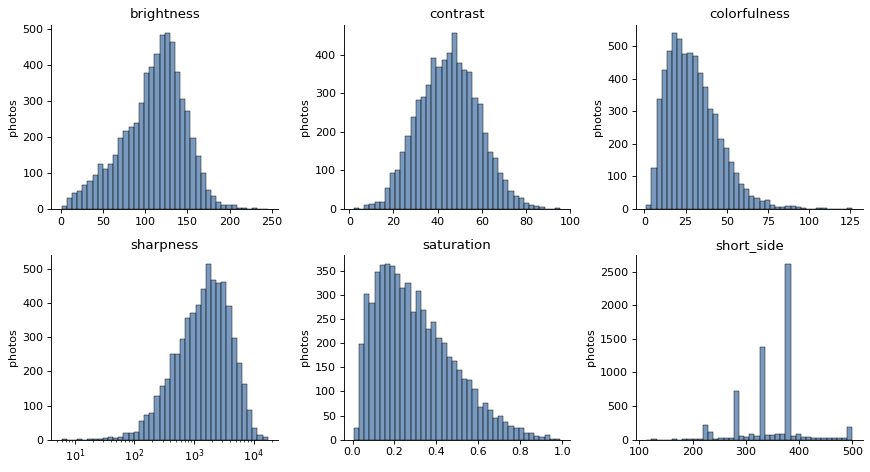

brightness    median  114.88   1% to 99%:   16.82 to  183.38
contrast      median   45.14   1% to 99%:   16.20 to   77.01
colorfulness  median   27.40   1% to 99%:    6.33 to   75.78
sharpness     median 1578.17   1% to 99%:   88.35 to 9185.86
saturation    median    0.27   1% to 99%:    0.04 to    0.80


In [118]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6), dpi=80)
for ax, col in zip(axes.flat, IMG_COLS):
    data = quality[col].clip(lower=0.1) if col == "sharpness" else quality[col]
    sns.histplot(data, bins=40, color="#4c78a8", log_scale=(col == "sharpness"), ax=ax)
    ax.set(title=col, xlabel="", ylabel="photos")
savefig("img_distributions")
plt.close()
for col in IMG_COLS[:5]:
    low, high = quality[col].quantile([0.01, 0.99])
    print(f"{col:13s} median {quality[col].median():7.2f}   1% to 99%: {low:7.2f} to {high:7.2f}")

Do the measures move together? A Spearman correlation tells us whether, for example, dark photos are also the blurry ones.

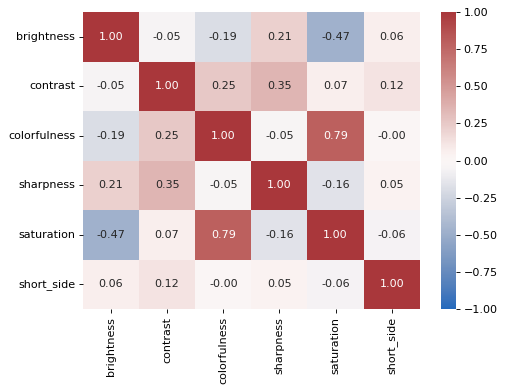

In [119]:
fig, ax = plt.subplots(figsize=(6.5, 5), dpi=80)
sns.heatmap(quality[IMG_COLS].corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
savefig("img_correlations")
plt.close()

### 5.8 Comparing groups
The question behind these charts: does image quality differ between the safety categories, between the splits, or over the years? If the splits differed a lot, a model evaluated on test would be judged on a different kind of photo than it was trained on. Boxes show the middle half of the photos and the line is the median.

In [120]:
def img_year_label(year):
    if pd.isna(year):
        return None
    return "<=2014" if year <= 2014 else str(int(year))

img_plot = quality.assign(
    who_label=quality["who_category"].map(WHO_LABEL),
    year_group=quality["year"].map(img_year_label),
)
img_plot["who_label"].value_counts()

who_label
Not listed        5755
WHO category 2     314
WHO category 1     180
Name: count, dtype: int64

In [121]:
def img_box_grid(x, order, palette, cols, shape, name):
    fig, axes = plt.subplots(*shape, figsize=(11, 3.3 * shape[0]), dpi=80)
    for ax, col in zip(axes.flat, cols):
        sns.boxplot(data=img_plot, x=x, y=col, order=order, hue=x, hue_order=order, palette=palette,
                    showfliers=False, legend=False, ax=ax)
        ax.set(title=col, xlabel="", ylabel="", yscale="log" if col == "sharpness" else "linear")
        plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
    savefig(name)
    plt.close()

In [122]:
def img_kruskal(values):
    try:
        return kruskal(*values).pvalue
    except ValueError:
        return np.nan

def img_median_table(by):
    groups = img_plot.groupby(by)
    table = groups[IMG_COLS].median().T
    table["p (Kruskal-Wallis)"] = [img_kruskal([g[c].dropna() for _, g in groups]) for c in IMG_COLS]
    return table.round(3)

#### By WHO category
With thousands of photos even a tiny shift gives a very small p-value, so the medians in the table matter more than the p-values.

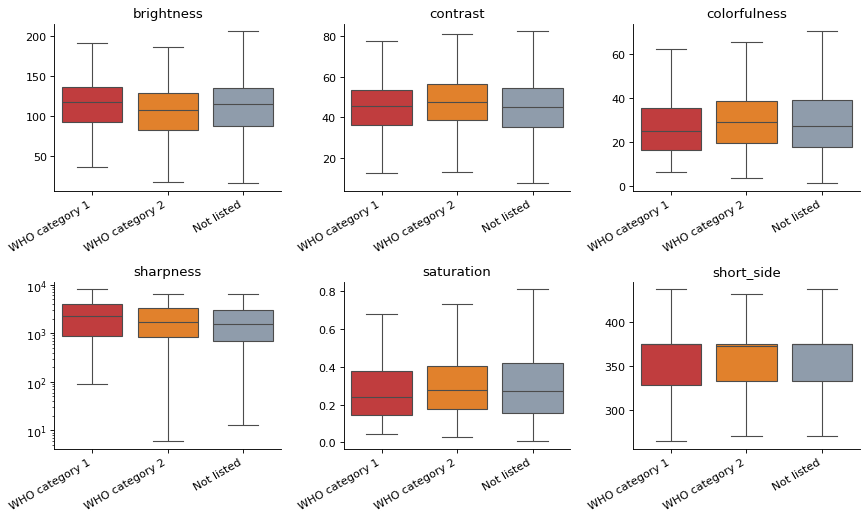

who_label,Not listed,WHO category 1,WHO category 2,p (Kruskal-Wallis)
brightness,115.264,118.208,107.602,0.003
contrast,44.986,45.733,47.344,0.007
colorfulness,27.404,24.940,28.921,0.069
sharpness,1547.432,2258.611,1714.478,0.000
saturation,0.271,0.240,0.275,0.158
short_side,375.000,375.000,373.000,0.292


In [123]:
img_who_order = [WHO_LABEL[k] for k in ["1", "2", "not_listed"]]
img_who_palette = {WHO_LABEL[k]: v for k, v in WHO_COLORS.items()}
img_box_grid("who_label", img_who_order, img_who_palette, IMG_COLS, (2, 3), "img_by_who")
img_median_table("who_label")

#### By split

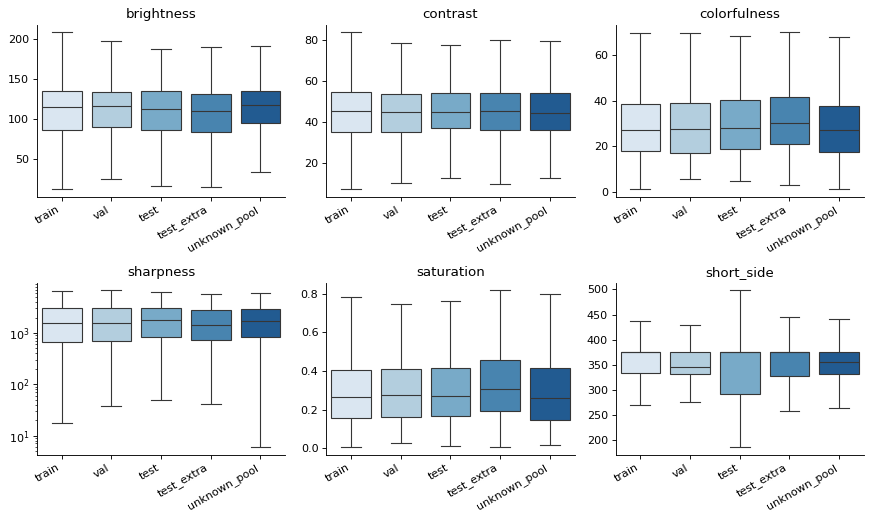

{'train': 3893, 'val': 700, 'test': 361, 'test_extra': 480, 'unknown_pool': 815}


split,test,test_extra,train,unknown_pool,val,p (Kruskal-Wallis)
brightness,113.082,110.589,114.630,117.454,116.784,0.031
contrast,44.768,45.572,45.239,44.396,45.194,0.936
colorfulness,28.114,30.264,26.923,27.140,27.562,0.000
sharpness,1778.550,1428.087,1547.875,1679.235,1598.142,0.083
saturation,0.272,0.308,0.266,0.258,0.276,0.000
short_side,375.000,375.000,375.000,356.000,346.000,0.128


In [124]:
img_split_order = [s for s in SPLIT_ORDER if s in set(quality["split"])]
img_box_grid("split", img_split_order, "Blues", IMG_COLS, (2, 3), "img_by_split")
print(quality["split"].value_counts().reindex(img_split_order).to_dict())
img_median_table("split")

#### By year the photo was taken
Years up to 2014 are put in one group because there are few photos in each of them.

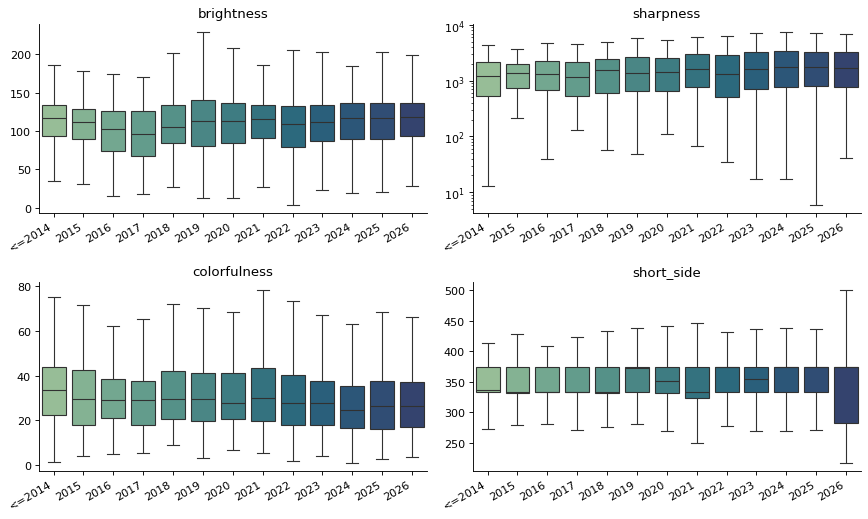

{'<=2014': 424, '2015': 132, '2016': 127, '2017': 164, '2018': 137, '2019': 229, '2020': 251, '2021': 358, '2022': 462, '2023': 751, '2024': 974, '2025': 1030, '2026': 1210}


year_group,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,<=2014,p (Kruskal-Wallis)
brightness,111.288,102.129,96.544,104.873,113.390,112.725,116.163,109.414,112.088,117.568,116.795,118.270,116.735,0.0
contrast,45.652,41.554,38.724,42.293,44.559,44.747,43.684,43.582,47.043,45.972,46.532,46.025,42.148,0.0
colorfulness,29.738,28.903,28.974,29.496,29.422,27.565,30.078,27.811,27.904,24.516,26.496,26.218,33.613,0.0
sharpness,1364.449,1328.386,1143.749,1568.466,1401.493,1447.788,1638.602,1308.671,1617.270,1770.347,1761.815,1702.084,1237.200,0.0
saturation,0.337,0.316,0.335,0.318,0.303,0.289,0.312,0.275,0.265,0.250,0.243,0.245,0.352,0.0
short_side,333.000,334.000,333.000,333.000,372.000,352.000,334.000,375.000,355.000,375.000,375.000,375.000,336.500,0.0


In [125]:
img_years = ["<=2014"] + [str(y) for y in range(2015, 2027)]
img_year_order = [y for y in img_years if y in set(img_plot["year_group"])]
img_box_grid("year_group", img_year_order, "crest", ["brightness", "sharpness", "colorfulness", "short_side"], (2, 2), "img_by_year")
print(img_plot["year_group"].value_counts().reindex(img_year_order).to_dict())
img_median_table("year_group")

### 5.9 Photos with faces
Photos where someone holds the snake are a problem for a classifier, because the person is not the label. A face detector can also fire on patterns that only look like a face, so a count is a rough flag. This chart counts every sampled photo. Photos with a detected face are not shown as thumbnails anywhere in this notebook.

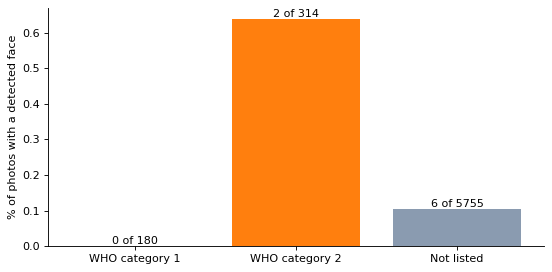

0.1% of the sampled photos have at least one detected face (yunet)


In [126]:
img_faces = quality.assign(has_face=quality["face_count"] > 0).groupby("who_category")["has_face"].agg(["mean", "sum", "size"])
img_faces = img_faces.reindex(["1", "2", "not_listed"])
fig, ax = plt.subplots(figsize=(7, 3.5), dpi=80)
ax.bar([WHO_LABEL[k] for k in img_faces.index], img_faces["mean"] * 100, color=[WHO_COLORS[k] for k in img_faces.index])
for i, (share, hits, total) in enumerate(zip(img_faces["mean"], img_faces["sum"], img_faces["size"])):
    ax.text(i, share * 100, f"{hits:.0f} of {total:.0f}", ha="center", va="bottom")
ax.set(ylabel="% of photos with a detected face")
savefig("img_faces_by_who")
plt.close()
print(f"{(quality['face_count'] > 0).mean():.1%} of the sampled photos have at least one detected face ({img_face_method})")

### 5.10 Outliers
First the numbers for the most extreme photos of the whole sample, including the photos with most faces. Only photos with a CC0 or CC BY licence can be shown, and photos with a detected face are never shown, so the thumbnails after this table are the most extreme of the photos that can be shown.

In [127]:
img_extremes = pd.concat([
    quality.nsmallest(3, "brightness").assign(why="darkest"),
    quality.nlargest(3, "brightness").assign(why="brightest"),
    quality.nsmallest(3, "sharpness").assign(why="blurriest"),
    quality.nlargest(3, "face_count").assign(why="most faces"),
])
img_extremes[["why", "photo_id", "species", "license", "brightness", "sharpness", "face_count"]].round(1).reset_index(drop=True)

,why,photo_id,species,license,brightness,sharpness,face_count
0,darkest,468065493,Dendrelaphis tristis,cc-by,0.8,40.4,0
1,darkest,126905602,Craspedocephalus peltopelor,cc-by,1.1,12.8,0
2,darkest,421473421,Ahaetulla oxyrhynca,cc-by,2.4,107.5,0
3,brightest,519540458,Lycodon jara,cc-by-nc,245.3,391.7,0
4,brightest,251545701,Hydrophis cyanocinctus,cc-by-nc,231.1,983.9,0
5,brightest,251545705,Hydrophis cyanocinctus,cc-by-nc,229.4,1130.9,0
6,blurriest,610393202,Bungarus sindanus,cc-by-nc,94.5,6.0,0
7,blurriest,126905602,Craspedocephalus peltopelor,cc-by,1.1,12.8,0
8,blurriest,399378865,Boiga beddomei,cc-by-nc,7.9,17.2,0
9,most faces,676262558,Python bivittatus,cc-by-nc,114.0,6048.2,1


#### Helpers for the picture grids
Pictures are small JPEG thumbnails (quality 70, at most 224 px wide) stitched into one grid per figure, so the notebook stays small. All photos come from the measured sample, so we know their face count. `img_pick` takes CC0 and CC BY photos without a detected face first, then CC BY-NC without a face, and only if there are still too few does it use photos with a face.

In [128]:
IMG_OK = ["cc0", "cc-by", "cc-by-nc"]
img_pool = quality[quality["license"].isin(IMG_OK)]
print(f"{len(img_pool):,} sampled photos with a licence we can show, {(img_pool['face_count'] == 0).sum():,} without a detected face")

6,038 sampled photos with a licence we can show, 6,030 without a detected face


In [129]:
def img_tier(d, n, order, shift):
    if order is None:
        d = d.sample(frac=1, random_state=SEED + shift)
        d = d.assign(r=d.groupby("species").cumcount()).sort_values("r", kind="stable")
    else:
        d = d.sort_values(order[0], ascending=order[1])
    return d.head(max(n, 0))

def img_pick(df, n, order=None, shift=0):
    got = []
    for faces in (False, True):
        for tier in (["cc0", "cc-by"], ["cc-by-nc"]):
            part = df[df["license"].isin(tier) & ((df["face_count"] > 0) == faces)]
            got.append(img_tier(part, n - sum(map(len, got)), order, shift))
    return pd.concat(got)

In [130]:
IMG_WHO_TEXT = {"1": "WHO 1", "2": "WHO 2", "not_listed": "not listed"}

def img_label(rows, prefix=""):
    return rows.assign(label=[f"{prefix}{i}" for i in range(1, len(rows) + 1)])

def img_short(name):
    genus, *rest = name.split()
    return f"{genus[0]}. {' '.join(rest)}"

def img_entries(rows, col=None, pad=4):
    tail = (lambda r: IMG_WHO_TEXT[r.who_category]) if col is None else (lambda r: f"{getattr(r, col):.0f}")
    out = [(r.path, f"{r.label}. {img_short(r.species)} | {tail(r)}") for r in rows.itertuples()]
    return out + [None] * (-len(out) % pad)

In [131]:
try:
    IMG_FONT = ImageFont.load_default(size=12)
except (TypeError, OSError):
    IMG_FONT = ImageFont.load_default()

def img_tile(entry, w=224, h=186):
    tile = Image.new("RGB", (w, h + 16), (238, 238, 238))
    if entry is not None:
        try:
            pic = (entry[0] if isinstance(entry[0], Image.Image) else Image.open(img_file(entry[0]))).convert("RGB")
            pic.thumbnail((w - 4, h - 4))
            tile.paste(pic, ((w - pic.width) // 2, (h - pic.height) // 2))
        except Exception:
            pass
        ImageDraw.Draw(tile).text((3, h + 2), entry[1], fill=(20, 20, 20), font=IMG_FONT)
    return tile

In [132]:
IMG_BYTES = []

def img_grid(entries, cols=4):
    tiles = [img_tile(e) for e in entries]
    w, h = tiles[0].size
    sheet = Image.new("RGB", (cols * w, -(-len(tiles) // cols) * h), (238, 238, 238))
    for i, tile in enumerate(tiles):
        sheet.paste(tile, (i % cols * w, i // cols * h))
    return sheet

def img_show(sheet):
    buf = io.BytesIO()
    sheet.save(buf, format="JPEG", quality=70)
    IMG_BYTES.append(buf.tell())
    display(ShowImage(data=buf.getvalue(), format="jpeg", width=sheet.width))

In [133]:
def img_credits(rows, extra=()):
    table = pd.DataFrame({
        "species": rows["species"].values,
        "WHO": rows["who_category"].map(WHO_LABEL).values,
        **{c: rows[c].values for c in extra},
        "licence": rows["license"].values,
        "credit": rows["attribution"].values,
    }, index=rows["label"].values)
    with pd.option_context("display.max_colwidth", 120):
        display(table.round(2))
    if (rows["license"] == "cc-by-nc").any():
        print("note: too few CC0 / CC BY photos here, so some CC BY-NC photos were added (marked in the licence column)")
    if (rows["face_count"] > 0).any():
        print("note: too few photos without a detected face here, so some photos with a face are shown")

The outliers, four per row: darkest (brightness), brightest (brightness) and blurriest (sharpness) of the photos that can be shown. The number after the species is the value of that measure.

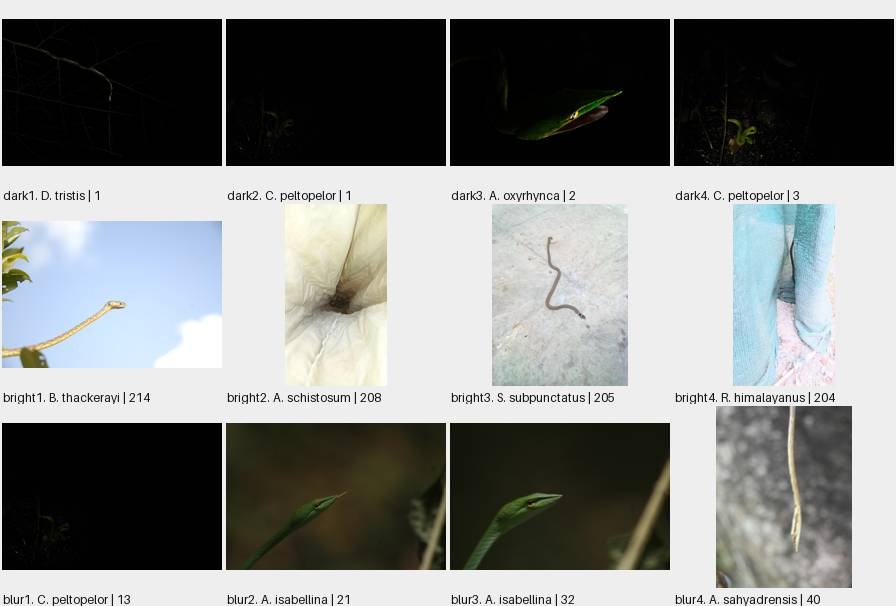

,species,WHO,licence,credit
dark1,Dendrelaphis tristis,Not listed,cc-by,"(c) Ashrith GS, some rights reserved (CC BY)"
dark2,Craspedocephalus peltopelor,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
dark3,Ahaetulla oxyrhynca,Not listed,cc-by,"(c) Teja Yantrapalli, some rights reserved (CC BY)"
dark4,Craspedocephalus peltopelor,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
bright1,Boiga thackerayi,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
bright2,Atretium schistosum,Not listed,cc-by,"(c) Ronith Urs, some rights reserved (CC BY)"
bright3,Sibynophis subpunctatus,Not listed,cc-by,"(c) Viral joshi, some rights reserved (CC BY)"
bright4,Rhabdophis himalayanus,Not listed,cc-by,"(c) Ronith Urs, some rights reserved (CC BY)"
blur1,Craspedocephalus peltopelor,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
blur2,Ahaetulla isabellina,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"


In [134]:
img_specs = [("dark", "brightness", True), ("bright", "brightness", False), ("blur", "sharpness", True)]
img_groups = [img_label(img_pick(img_pool, 4, (col, asc)), name) for name, col, asc in img_specs]
img_show(img_grid(sum([img_entries(g, col) for g, (name, col, asc) in zip(img_groups, img_specs)], [])))
img_credits(pd.concat(img_groups))

### 5.11 A look at the photos
Pictures say more than numbers. These come from the sample, CC0 and CC BY first, one photo per species until we run out of species.

**WHO category 1**

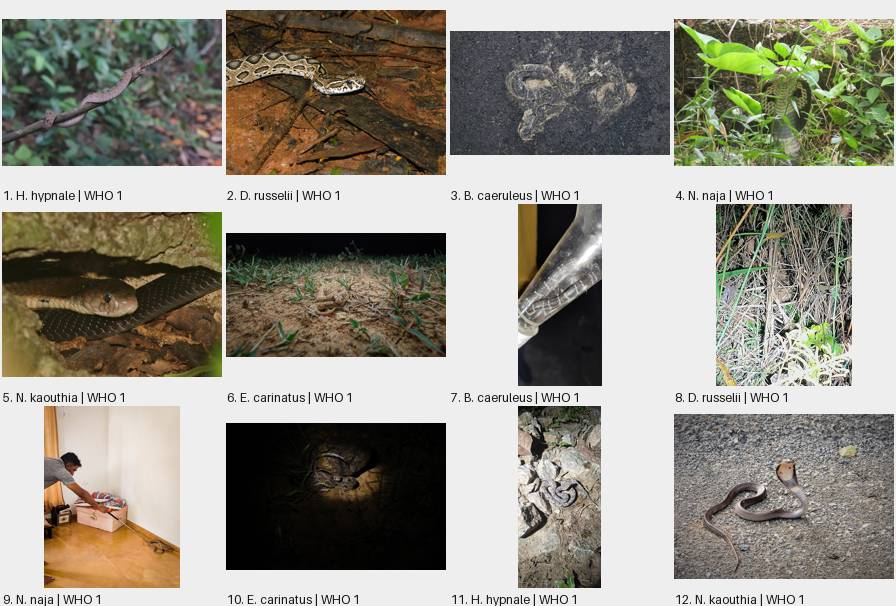

,species,WHO,licence,credit
1,Hypnale hypnale,WHO category 1,cc-by,"(c) kavindu_amarasinghe, some rights reserved (CC BY)"
2,Daboia russelii,WHO category 1,cc-by,"(c) Rama Narayanan, some rights reserved (CC BY)"
3,Bungarus caeruleus,WHO category 1,cc-by,"(c) Ronith Urs, some rights reserved (CC BY)"
4,Naja naja,WHO category 1,cc-by,"(c) Thuhiru S. Yapa, some rights reserved (CC BY)"
5,Naja kaouthia,WHO category 1,cc-by,"(c) Ian Dugdale, some rights reserved (CC BY)"
6,Echis carinatus,WHO category 1,cc-by,"(c) @dineshphotography7797, some rights reserved (CC BY)"
7,Bungarus caeruleus,WHO category 1,cc-by,"(c) Jagdish Supekar, some rights reserved (CC BY)"
8,Daboia russelii,WHO category 1,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
9,Naja naja,WHO category 1,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
10,Echis carinatus,WHO category 1,cc-by,"(c) Teja Yantrapalli, some rights reserved (CC BY)"


**WHO category 2**

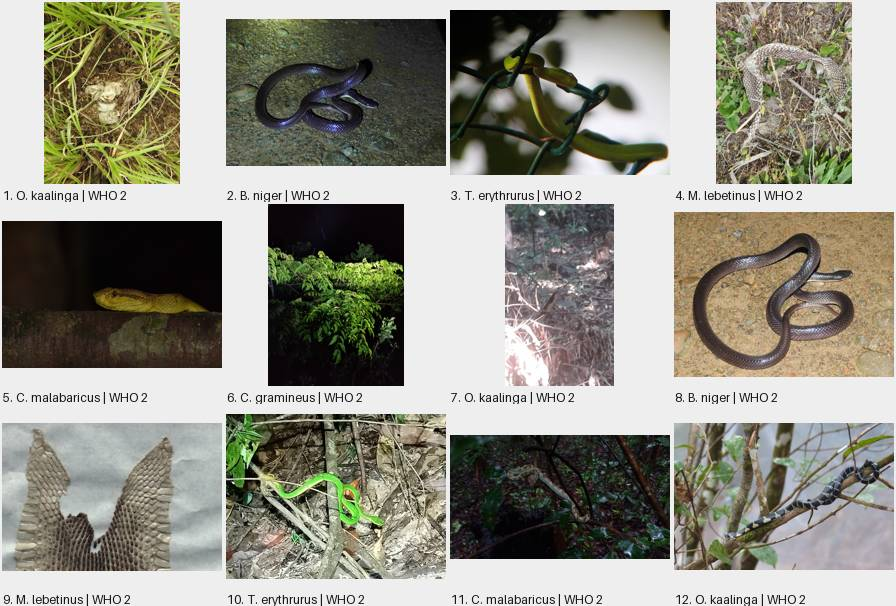

,species,WHO,licence,credit
1,Ophiophagus kaalinga,WHO category 2,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
2,Bungarus niger,WHO category 2,cc-by,"(c) Rejoice Gassah, some rights reserved (CC BY)"
3,Trimeresurus erythrurus,WHO category 2,cc-by,"(c) Jigu, some rights reserved (CC BY)"
4,Macrovipera lebetinus,WHO category 2,cc-by,"(c) Dmitry Ivanov, some rights reserved (CC BY)"
5,Craspedocephalus malabaricus,WHO category 2,cc-by,"(c) Ansil B.R., some rights reserved (CC BY)"
6,Craspedocephalus gramineus,WHO category 2,cc-by,"(c) Ashwin Viswanathan, some rights reserved (CC BY)"
7,Ophiophagus kaalinga,WHO category 2,cc-by,"(c) Siddarth Machado, some rights reserved (CC BY)"
8,Bungarus niger,WHO category 2,cc0,no rights reserved
9,Macrovipera lebetinus,WHO category 2,cc-by,"(c) Tigran Tadevosyan, some rights reserved (CC BY)"
10,Trimeresurus erythrurus,WHO category 2,cc-by,"(c) Sabarni Sarker, some rights reserved (CC BY)"


**Not listed**

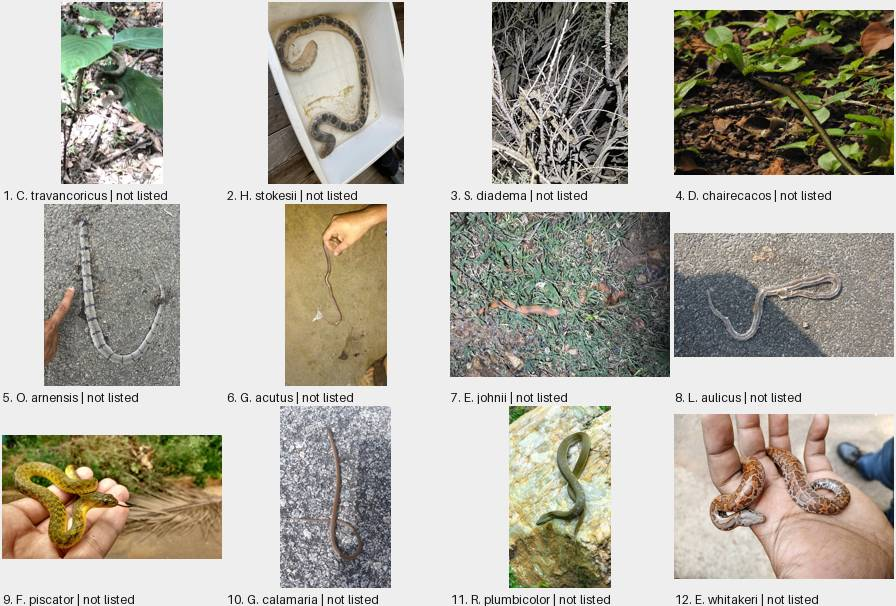

,species,WHO,licence,credit
1,Craspedocephalus travancoricus,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
2,Hydrophis stokesii,Not listed,cc-by,"(c) Bryce Watts-Parker, some rights reserved (CC BY)"
3,Spalerosophis diadema,Not listed,cc-by,"(c) Kian, some rights reserved (CC BY)"
4,Dendrelaphis chairecacos,Not listed,cc-by,"(c) Paulmathi Vinod, some rights reserved (CC BY)"
5,Oligodon arnensis,Not listed,cc-by,"(c) payalm, some rights reserved (CC BY)"
6,Grypotyphlops acutus,Not listed,cc0,no rights reserved
7,Eryx johnii,Not listed,cc-by,"(c) Teja Yantrapalli, some rights reserved (CC BY)"
8,Lycodon aulicus,Not listed,cc-by,"(c) Viral joshi, some rights reserved (CC BY)"
9,Fowlea piscator,Not listed,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
10,Gongylosoma calamaria,Not listed,cc-by,"(c) Raja bandi, some rights reserved (CC BY)"


In [135]:
def img_category_grid(cat):
    rows = img_label(img_pick(img_pool[img_pool["who_category"] == cat], 12))
    display(Markdown(f"**{WHO_LABEL[cat]}**"))
    img_show(img_grid(img_entries(rows)))
    img_credits(rows)

for cat in ["1", "2", "not_listed"]:
    img_category_grid(cat)

#### Sharpest and blurriest photos
Sharpness is measured on the photos in the sample, and the number after the species is the sharpness. Let's see what a high and a low value really look like: a high Laplacian variance can also come from a busy background, so it is not automatically a well-focused snake.

**Sharpest photos**

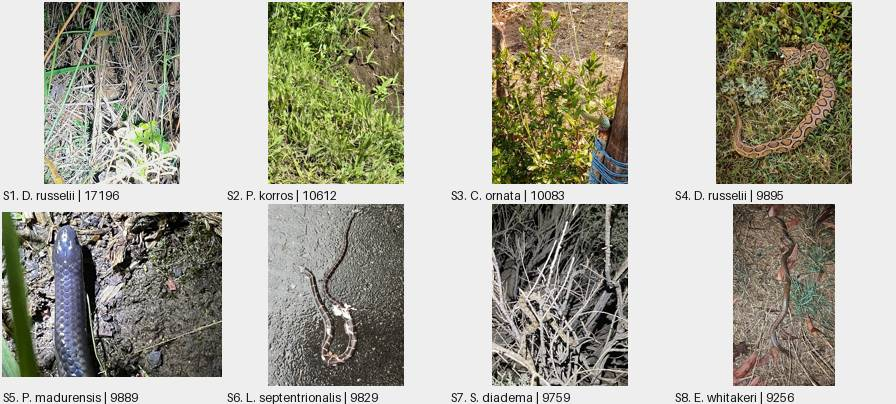

,species,WHO,licence,credit
S1,Daboia russelii,WHO category 1,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
S2,Ptyas korros,Not listed,cc-by,"(c) Lawrence Hylton, some rights reserved (CC BY)"
S3,Chrysopelea ornata,Not listed,cc-by,"(c) Jean Jacques Godon, some rights reserved (CC BY)"
S4,Daboia russelii,WHO category 1,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
S5,Platyplectrurus madurensis,Not listed,cc-by,"(c) Nandini Rajamani, some rights reserved (CC BY)"
S6,Lycodon septentrionalis,Not listed,cc-by,"(c) Jigu, some rights reserved (CC BY)"
S7,Spalerosophis diadema,Not listed,cc-by,"(c) Kian, some rights reserved (CC BY)"
S8,Eryx whitakeri,Not listed,cc-by,"(c) Rohit Naniwadekar, some rights reserved (CC BY)"


**Blurriest photos**

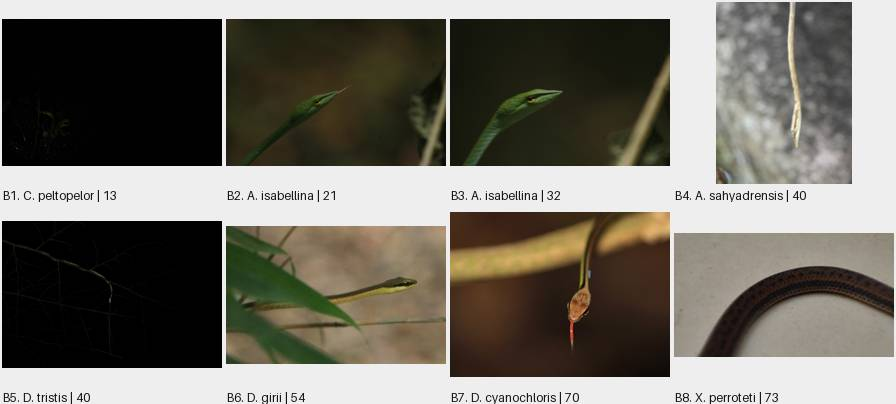

,species,WHO,licence,credit
B1,Craspedocephalus peltopelor,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
B2,Ahaetulla isabellina,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
B3,Ahaetulla isabellina,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
B4,Ahaetulla sahyadrensis,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
B5,Dendrelaphis tristis,Not listed,cc-by,"(c) Ashrith GS, some rights reserved (CC BY)"
B6,Dendrelaphis girii,Not listed,cc-by,"(c) Afsar Nayakkan, some rights reserved (CC BY)"
B7,Dendrelaphis cyanochloris,Not listed,cc-by,"(c) Ian Dugdale, some rights reserved (CC BY)"
B8,Xylophis perroteti,Not listed,cc-by,"(c) Siya ul haque, some rights reserved (CC BY)"


In [136]:
for tag, asc, text in [("S", False, "Sharpest photos"), ("B", True, "Blurriest photos")]:
    rows = img_label(img_pick(img_pool, 8, ("sharpness", asc)), tag)
    display(Markdown(f"**{text}**"))
    img_show(img_grid(img_entries(rows, "sharpness")))
    img_credits(rows)

#### Lookalike pairs
Dangerous species on the top row (D1 to D4), the not-listed species they get mixed up with on the bottom row (H1 to H4). The caption shows the WHO category. If a species has no usable photo in the sample, the pair is skipped with a note.

In [137]:
def img_pair(top_sp, bottom_sp, text, shift=0, tags="DH"):
    top = img_label(img_pick(img_pool[img_pool["species"] == top_sp], 4, None, shift), tags[0])
    bottom = img_label(img_pick(img_pool[img_pool["species"] == bottom_sp], 4, None, shift), tags[1])
    if top.empty or bottom.empty:
        print(f"skipped {top_sp} / {bottom_sp}: no usable photo for one of them")
        return
    display(Markdown(f"**{top_sp}** (WHO {who_of[top_sp]}) on top, **{bottom_sp}** (WHO {who_of[bottom_sp]}) below: {text}"))
    img_show(img_grid(img_entries(top) + img_entries(bottom)))
    img_credits(pd.concat([top, bottom]))

**Naja naja** (WHO 1) on top, **Ptyas mucosa** (WHO not_listed) below: spectacled cobra and oriental rat snake

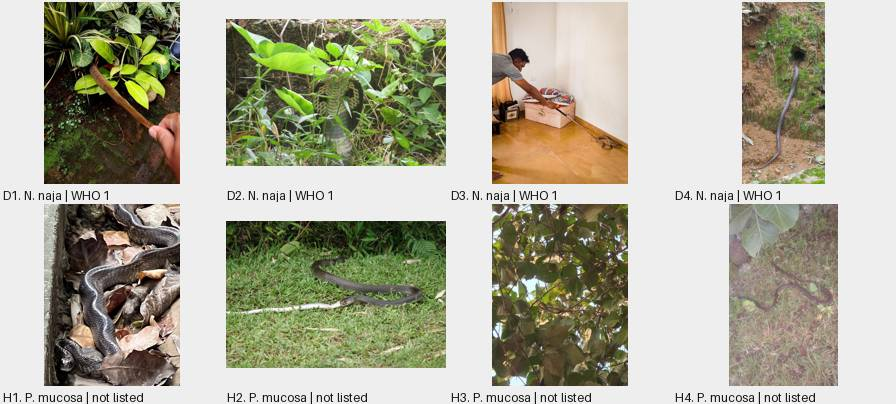

,species,WHO,licence,credit
D1,Naja naja,WHO category 1,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
D2,Naja naja,WHO category 1,cc-by,"(c) Thuhiru S. Yapa, some rights reserved (CC BY)"
D3,Naja naja,WHO category 1,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
D4,Naja naja,WHO category 1,cc-by,"(c) T R Shankar Raman, some rights reserved (CC BY)"
H1,Ptyas mucosa,Not listed,cc-by,"(c) dschigel, some rights reserved (CC BY)"
H2,Ptyas mucosa,Not listed,cc-by,"(c) Oleg Kosterin, some rights reserved (CC BY)"
H3,Ptyas mucosa,Not listed,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
H4,Ptyas mucosa,Not listed,cc-by,"(c) muddytortoise, some rights reserved (CC BY)"


**Bungarus caeruleus** (WHO 1) on top, **Lycodon aulicus** (WHO not_listed) below: common krait and Indian wolf snake

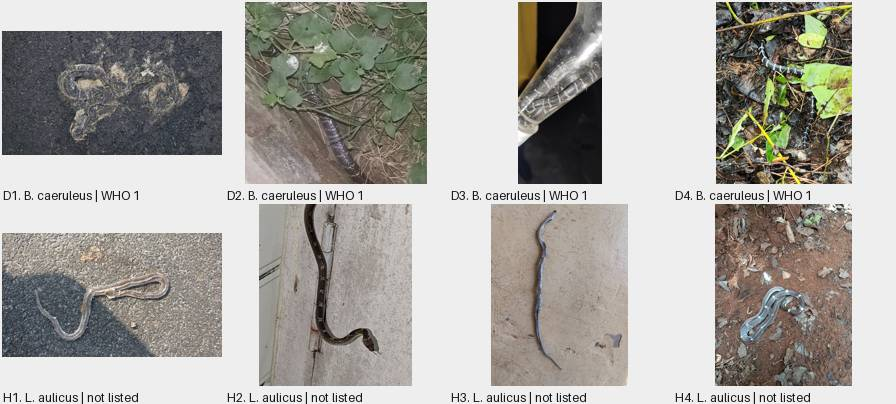

,species,WHO,licence,credit
D1,Bungarus caeruleus,WHO category 1,cc-by,"(c) Ronith Urs, some rights reserved (CC BY)"
D2,Bungarus caeruleus,WHO category 1,cc-by,"(c) Name, some rights reserved (CC BY)"
D3,Bungarus caeruleus,WHO category 1,cc-by,"(c) Jagdish Supekar, some rights reserved (CC BY)"
D4,Bungarus caeruleus,WHO category 1,cc-by,"(c) Ashwin A, some rights reserved (CC BY)"
H1,Lycodon aulicus,Not listed,cc-by,"(c) Viral joshi, some rights reserved (CC BY)"
H2,Lycodon aulicus,Not listed,cc-by,"(c) Subhasish Arandhara, some rights reserved (CC BY)"
H3,Lycodon aulicus,Not listed,cc-by,"(c) T R Shankar Raman, some rights reserved (CC BY)"
H4,Lycodon aulicus,Not listed,cc-by,"(c) parithi, some rights reserved (CC BY)"


**Bungarus caeruleus** (WHO 1) on top, **Lycodon travancoricus** (WHO not_listed) below: common krait and Travancore wolf snake

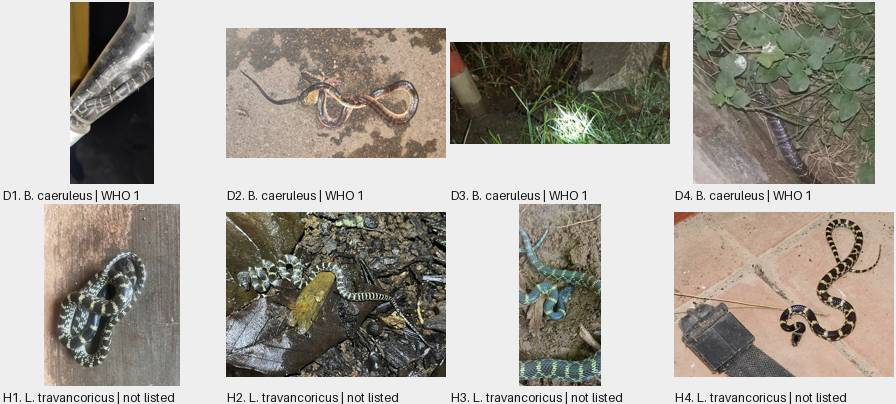

,species,WHO,licence,credit
D1,Bungarus caeruleus,WHO category 1,cc-by,"(c) Jagdish Supekar, some rights reserved (CC BY)"
D2,Bungarus caeruleus,WHO category 1,cc-by,"(c) Harshjeet Singh Bal, some rights reserved (CC BY)"
D3,Bungarus caeruleus,WHO category 1,cc-by,"(c) Samartha S G, some rights reserved (CC BY)"
D4,Bungarus caeruleus,WHO category 1,cc-by,"(c) Name, some rights reserved (CC BY)"
H1,Lycodon travancoricus,Not listed,cc-by,"(c) Prashanth N S, some rights reserved (CC BY)"
H2,Lycodon travancoricus,Not listed,cc0,no rights reserved
H3,Lycodon travancoricus,Not listed,cc-by,"(c) sumathiprakash, some rights reserved (CC BY)"
H4,Lycodon travancoricus,Not listed,cc-by,"(c) Seema Merchant, some rights reserved (CC BY)"


**Bungarus caeruleus** (WHO 1) on top, **Lycodon fasciolatus** (WHO not_listed) below: common krait and Russell's wolf snake

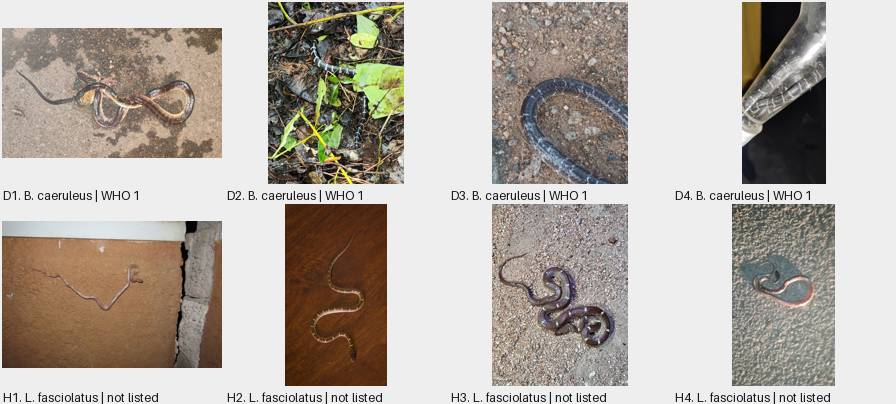

,species,WHO,licence,credit
D1,Bungarus caeruleus,WHO category 1,cc-by,"(c) Harshjeet Singh Bal, some rights reserved (CC BY)"
D2,Bungarus caeruleus,WHO category 1,cc-by,"(c) Ashwin A, some rights reserved (CC BY)"
D3,Bungarus caeruleus,WHO category 1,cc-by,"(c) Pranav Chandra Bose, some rights reserved (CC BY)"
D4,Bungarus caeruleus,WHO category 1,cc-by,"(c) Jagdish Supekar, some rights reserved (CC BY)"
H1,Lycodon fasciolatus,Not listed,cc-by,"(c) Navaneeth Sini George, some rights reserved (CC BY)"
H2,Lycodon fasciolatus,Not listed,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
H3,Lycodon fasciolatus,Not listed,cc0,no rights reserved
H4,Lycodon fasciolatus,Not listed,cc-by,"(c) Pranav Chandra Bose, some rights reserved (CC BY)"


**Daboia russelii** (WHO 1) on top, **Eryx conicus** (WHO not_listed) below: Russell's viper and rough-scaled sand boa

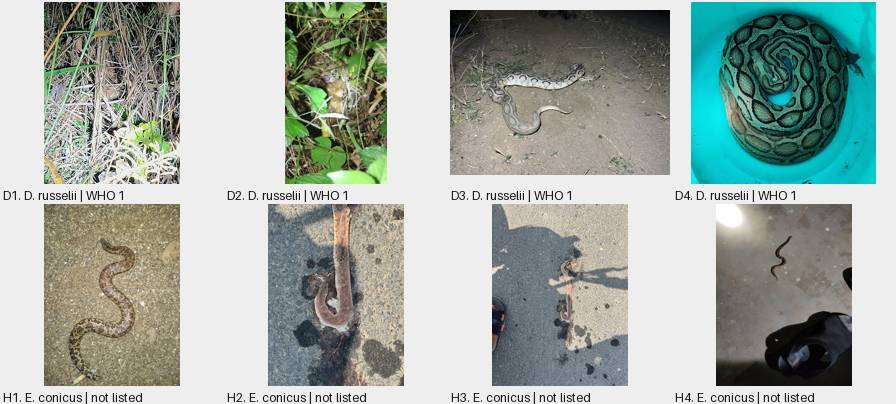

,species,WHO,licence,credit
D1,Daboia russelii,WHO category 1,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
D2,Daboia russelii,WHO category 1,cc-by,"(c) Navaneeth Sini George, some rights reserved (CC BY)"
D3,Daboia russelii,WHO category 1,cc-by,"(c) Teja Yantrapalli, some rights reserved (CC BY)"
D4,Daboia russelii,WHO category 1,cc-by,"(c) Harshjeet Singh Bal, some rights reserved (CC BY)"
H1,Eryx conicus,Not listed,cc-by,"(c) Livson Thomas, some rights reserved (CC BY)"
H2,Eryx conicus,Not listed,cc-by,"(c) Teja Yantrapalli, some rights reserved (CC BY)"
H3,Eryx conicus,Not listed,cc-by,"(c) Teja Yantrapalli, some rights reserved (CC BY)"
H4,Eryx conicus,Not listed,cc-by,"(c) parithi, some rights reserved (CC BY)"


**Daboia russelii** (WHO 1) on top, **Python molurus** (WHO not_listed) below: Russell's viper and Indian rock python

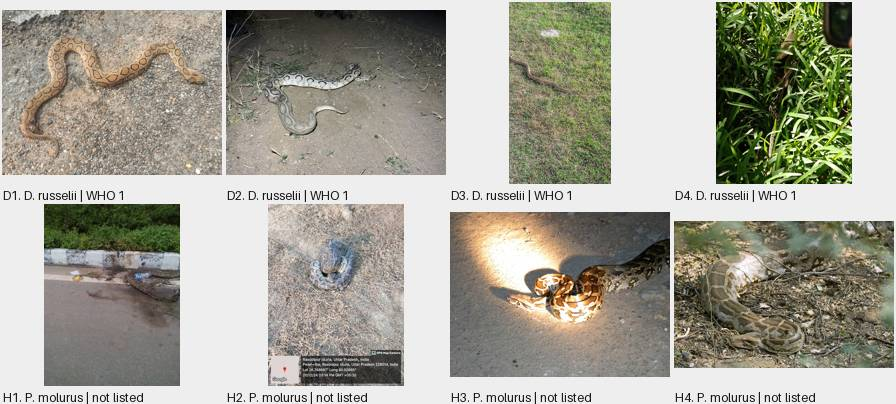

,species,WHO,licence,credit
D1,Daboia russelii,WHO category 1,cc-by,"(c) Kishore, some rights reserved (CC BY)"
D2,Daboia russelii,WHO category 1,cc-by,"(c) Teja Yantrapalli, some rights reserved (CC BY)"
D3,Daboia russelii,WHO category 1,cc-by,"(c) Mahmood, some rights reserved (CC BY)"
D4,Daboia russelii,WHO category 1,cc-by,"(c) Ashwin Viswanathan, some rights reserved (CC BY)"
H1,Python molurus,Not listed,cc-by,"(c) Viral joshi, some rights reserved (CC BY)"
H2,Python molurus,Not listed,cc-by,"(c) irshad khan, some rights reserved (CC BY)"
H3,Python molurus,Not listed,cc-by,"(c) Ansil B.R., some rights reserved (CC BY)"
H4,Python molurus,Not listed,cc-by,"(c) Paul Asman and Jill Lenoble, some rights reserved (CC BY)"


**Echis carinatus** (WHO 1) on top, **Boiga trigonata** (WHO not_listed) below: saw-scaled viper and common cat snake

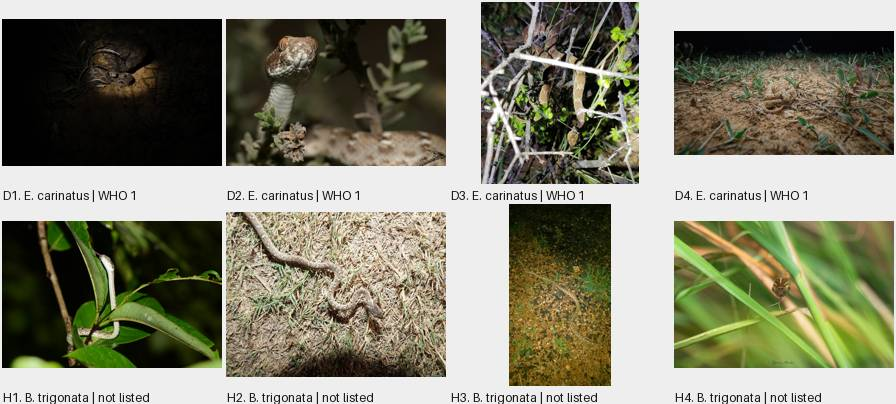

,species,WHO,licence,credit
D1,Echis carinatus,WHO category 1,cc-by,"(c) Teja Yantrapalli, some rights reserved (CC BY)"
D2,Echis carinatus,WHO category 1,cc0,no rights reserved
D3,Echis carinatus,WHO category 1,cc-by,"(c) Ashwin Viswanathan, some rights reserved (CC BY)"
D4,Echis carinatus,WHO category 1,cc-by,"(c) @dineshphotography7797, some rights reserved (CC BY)"
H1,Boiga trigonata,Not listed,cc0,no rights reserved
H2,Boiga trigonata,Not listed,cc-by-nc,"(c) Zafeer Ahmed Shaikh, some rights reserved (CC BY-NC)"
H3,Boiga trigonata,Not listed,cc-by-nc,"(c) V.Arun, some rights reserved (CC BY-NC)"
H4,Boiga trigonata,Not listed,cc-by-nc,"(c) druva_murali, some rights reserved (CC BY-NC)"


note: too few CC0 / CC BY photos here, so some CC BY-NC photos were added (marked in the licence column)


**Naja naja** (WHO 1) on top, **Fowlea piscator** (WHO not_listed) below: spectacled cobra and checkered keelback

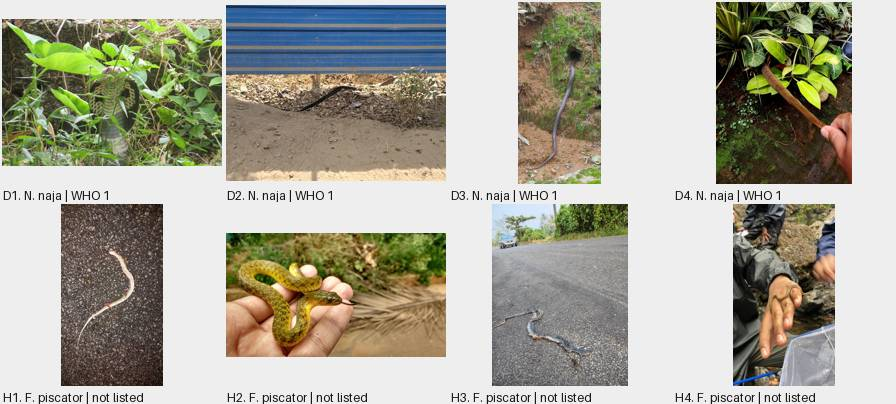

,species,WHO,licence,credit
D1,Naja naja,WHO category 1,cc-by,"(c) Thuhiru S. Yapa, some rights reserved (CC BY)"
D2,Naja naja,WHO category 1,cc-by,"(c) Abhinav Thakur, some rights reserved (CC BY)"
D3,Naja naja,WHO category 1,cc-by,"(c) T R Shankar Raman, some rights reserved (CC BY)"
D4,Naja naja,WHO category 1,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
H1,Fowlea piscator,Not listed,cc-by,"(c) Ronith Urs, some rights reserved (CC BY)"
H2,Fowlea piscator,Not listed,cc-by,"(c) Chayant Gonsalves, some rights reserved (CC BY)"
H3,Fowlea piscator,Not listed,cc-by,"(c) renjus box, some rights reserved (CC BY)"
H4,Fowlea piscator,Not listed,cc-by,"(c) Swarochi Tathagath, some rights reserved (CC BY)"


**Craspedocephalus gramineus** (WHO 2) on top, **Rhabdophis plumbicolor** (WHO not_listed) below: bamboo pit viper and green keelback

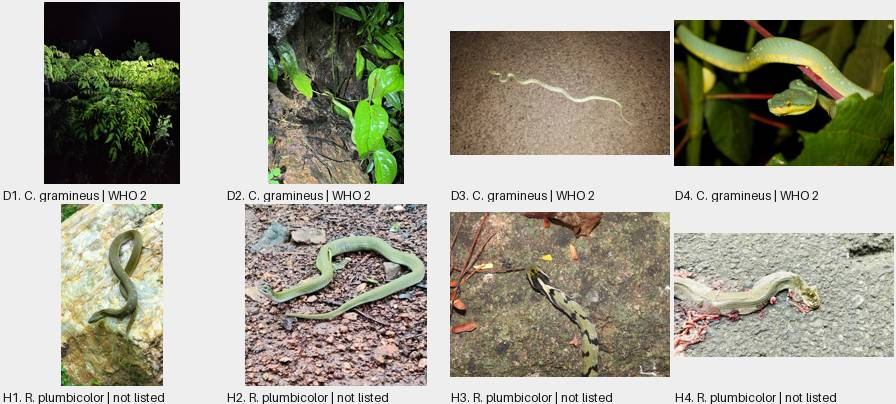

,species,WHO,licence,credit
D1,Craspedocephalus gramineus,WHO category 2,cc-by,"(c) Ashwin Viswanathan, some rights reserved (CC BY)"
D2,Craspedocephalus gramineus,WHO category 2,cc-by-nc,"(c) Dev Mehta, some rights reserved (CC BY-NC)"
D3,Craspedocephalus gramineus,WHO category 2,cc-by-nc,"(c) Prasad Gopalkrishna Gond, some rights reserved (CC BY-NC)"
D4,Craspedocephalus gramineus,WHO category 2,cc-by-nc,"(c) SA, some rights reserved (CC BY-NC)"
H1,Rhabdophis plumbicolor,Not listed,cc-by,"(c) Paulmathi Vinod, some rights reserved (CC BY)"
H2,Rhabdophis plumbicolor,Not listed,cc-by,"(c) Name, some rights reserved (CC BY)"
H3,Rhabdophis plumbicolor,Not listed,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
H4,Rhabdophis plumbicolor,Not listed,cc-by,"(c) Srinivasan Kasinathan, some rights reserved (CC BY)"


note: too few CC0 / CC BY photos here, so some CC BY-NC photos were added (marked in the licence column)


In [138]:
for k, (dang, harm, text) in enumerate(LOOKALIKES):
    img_pair(dang, harm, text, k)

Two pairs where both species are dangerous (A on top, B below). Here the question is whether the two can still be told apart by eye.

**Hypnale hypnale** (WHO 1) on top, **Craspedocephalus malabaricus** (WHO 2) below: hump-nosed and Malabar pit viper

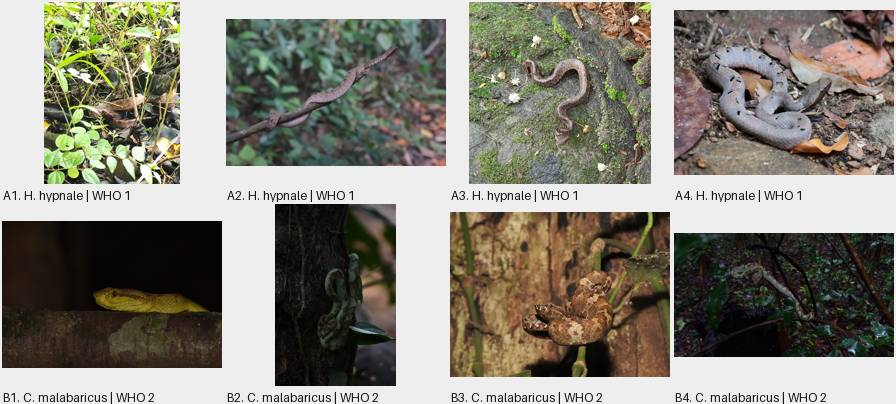

,species,WHO,licence,credit
A1,Hypnale hypnale,WHO category 1,cc-by,"(c) Ashwin A, some rights reserved (CC BY)"
A2,Hypnale hypnale,WHO category 1,cc-by,"(c) kavindu_amarasinghe, some rights reserved (CC BY)"
A3,Hypnale hypnale,WHO category 1,cc-by,"(c) Renjith Jacob Mathews, some rights reserved (CC BY)"
A4,Hypnale hypnale,WHO category 1,cc-by,"(c) Firos AK, some rights reserved (CC BY)"
B1,Craspedocephalus malabaricus,WHO category 2,cc-by,"(c) Ansil B.R., some rights reserved (CC BY)"
B2,Craspedocephalus malabaricus,WHO category 2,cc-by,"(c) Ahirbudhnyan M, some rights reserved (CC BY)"
B3,Craspedocephalus malabaricus,WHO category 2,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
B4,Craspedocephalus malabaricus,WHO category 2,cc-by,"(c) Manu M, some rights reserved (CC BY)"


**Hypnale hypnale** (WHO 1) on top, **Echis carinatus** (WHO 1) below: hump-nosed pit viper and saw-scaled viper

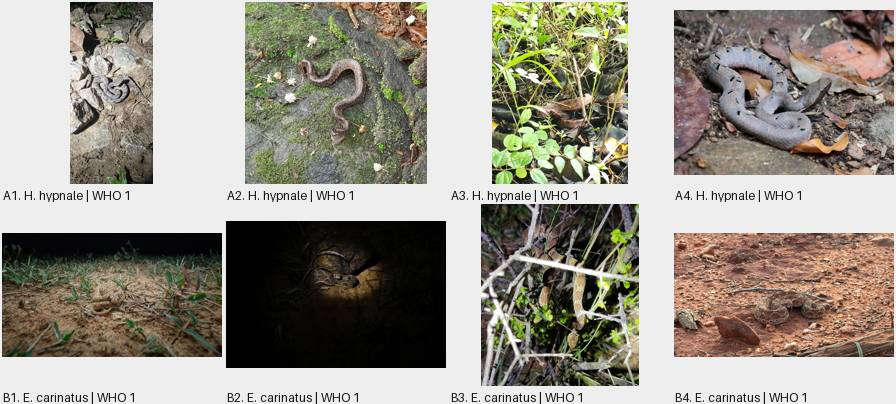

,species,WHO,licence,credit
A1,Hypnale hypnale,WHO category 1,cc-by,"(c) rajesh rocky, some rights reserved (CC BY)"
A2,Hypnale hypnale,WHO category 1,cc-by,"(c) Renjith Jacob Mathews, some rights reserved (CC BY)"
A3,Hypnale hypnale,WHO category 1,cc-by,"(c) Ashwin A, some rights reserved (CC BY)"
A4,Hypnale hypnale,WHO category 1,cc-by,"(c) Firos AK, some rights reserved (CC BY)"
B1,Echis carinatus,WHO category 1,cc-by,"(c) @dineshphotography7797, some rights reserved (CC BY)"
B2,Echis carinatus,WHO category 1,cc-by,"(c) Teja Yantrapalli, some rights reserved (CC BY)"
B3,Echis carinatus,WHO category 1,cc-by,"(c) Ashwin Viswanathan, some rights reserved (CC BY)"
B4,Echis carinatus,WHO category 1,cc-by,"(c) Teja Yantrapalli, some rights reserved (CC BY)"


In [139]:
for k, (first, second, text) in enumerate(DANGEROUS):
    img_pair(first, second, text, k, "AB")

### 5.12 What section 5 cost
A size check on the photo grids embedded in this section, so the notebook stays small enough to open everywhere.

In [140]:
img_mb = sum(IMG_BYTES) / 1e6
check("photo grids of section 5 stay under 2.5 MB together", img_mb <= 2.5, f"{len(IMG_BYTES)} grids, {img_mb:.2f} MB")
print(f"read {len(quality):,} photos in {img_secs:.0f} s ({per_1000:.0f} s per 1,000 with 4 threads)")

PASS  photo grids of section 5 stay under 2.5 MB together  (17 grids, 1.23 MB)
read 6,249 photos in 234 s (37 s per 1,000 with 4 threads)


### 5.13 Colour channels: the numbers a model will normalise with
Before training, a model usually subtracts a mean and divides by a standard deviation for each colour channel. Those two numbers have to come from the training photos only. If val or test photos feed into them, a little of the test set leaks into the training setup.

So here the numbers are worked out on the training part of the sample, and then we look at whether val, test and test_extra are coloured the same way.

Every photo is shrunk to 128 by 128 pixels first, which keeps this fast. Shrinking hardly changes a channel mean and lowers the standard deviation a little, so these are close estimates and not final constants. For the real training run they get recomputed on the full training set.

In [141]:
def rgb_measure(row):
    try:
        pic = Image.open(img_file(row.path)).convert("RGB").resize((128, 128), Image.BILINEAR)
        arr = np.asarray(pic, dtype=np.float32) / 255
        out = {"photo_id": row.photo_id}
        out.update({f"mean_{c}": float(arr[:, :, i].mean()) for i, c in enumerate("rgb")})
        out.update({f"var_{c}": float(arr[:, :, i].var()) for i, c in enumerate("rgb")})
        return out
    except Exception as err:
        return {"photo_id": row.photo_id, "error": str(err)[:80]}

In [142]:
rgb_rows = list(quality.itertuples())
rgb_start = time.time()
with ThreadPoolExecutor(max_workers=4) as pool:
    rgb_out = list(tqdm(pool.map(rgb_measure, rgb_rows), total=len(rgb_rows), mininterval=10))
rgb_failed = sum("error" in o for o in rgb_out)
rgb_df = pd.DataFrame([o for o in rgb_out if "error" not in o]).merge(
    quality[["photo_id", "split", "who_category", "species"]], on="photo_id")
print(f"{len(rgb_df):,} photos done in {time.time() - rgb_start:.0f} s, {rgb_failed} could not be read")

100%|██████████| 6249/6249 [00:13<00:00, 459.77it/s]

6,249 photos done in 14 s, 0 could not be read


For a set of photos the mean of a channel is the average of the photo means. The variance of all pixels is the average of the variance inside each photo plus the variance of the photo means, and the standard deviation is its square root. All photos have 128 by 128 pixels now, so every photo counts the same.

In [143]:
RGB_MEAN = ["mean_r", "mean_g", "mean_b"]
RGB_VAR = ["var_r", "var_g", "var_b"]

def rgb_fit(frame):
    mean = frame[RGB_MEAN].mean().to_numpy()
    var = frame[RGB_VAR].mean().to_numpy() + frame[RGB_MEAN].var(ddof=0).to_numpy()
    return mean, np.sqrt(var)

The training row is the one to use. For comparison, the table also shows the numbers most pretrained models were trained with (the ImageNet values), which is what you get if you copy the usual defaults.

In [144]:
rgb_train = rgb_df[rgb_df["split"] == "train"]
rgb_mean, rgb_std = rgb_fit(rgb_train)
RGB_IMAGENET = (np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225]))
rgb_ref = pd.DataFrame({"train mean": rgb_mean, "ImageNet mean": RGB_IMAGENET[0],
                        "train std": rgb_std, "ImageNet std": RGB_IMAGENET[1]}, index=["red", "green", "blue"])
rgb_ref.round(3)

,train mean,ImageNet mean,train std,ImageNet std
red,0.450,0.485,0.237,0.229
green,0.432,0.456,0.224,0.224
blue,0.366,0.406,0.224,0.225


Now the same numbers for every split. The second table says how far each split sits from the training numbers, measured in training standard deviations, so a value of 0.1 means one tenth of the normal spread of that channel.

In [145]:
rgb_parts = {}
for name in SPLIT_ORDER:
    part = rgb_df[rgb_df["split"] == name]
    if len(part):
        mean, std = rgb_fit(part)
        rgb_parts[name] = [len(part), *mean, *std]
rgb_split = pd.DataFrame(rgb_parts, index=["photos", "mean R", "mean G", "mean B", "std R", "std G", "std B"]).T
rgb_split["photos"] = rgb_split["photos"].astype(int)
rgb_split.round(3)

,photos,mean R,mean G,mean B,std R,std G,std B
train,3893,0.450,0.432,0.366,0.237,0.224,0.224
val,700,0.458,0.434,0.363,0.234,0.219,0.218
test,361,0.446,0.420,0.343,0.242,0.228,0.221
test_extra,480,0.444,0.423,0.346,0.232,0.219,0.222
unknown_pool,815,0.471,0.445,0.369,0.224,0.215,0.220


In [146]:
rgb_shift = pd.DataFrame((rgb_split[["mean R", "mean G", "mean B"]].to_numpy() - rgb_mean) / rgb_std,
                         index=rgb_split.index, columns=["red", "green", "blue"])
rgb_shift.round(3)

,red,green,blue
train,0.000,0.000,0.000
val,0.031,0.005,-0.011
test,-0.018,-0.054,-0.104
test_extra,-0.027,-0.040,-0.087
unknown_pool,0.086,0.057,0.015


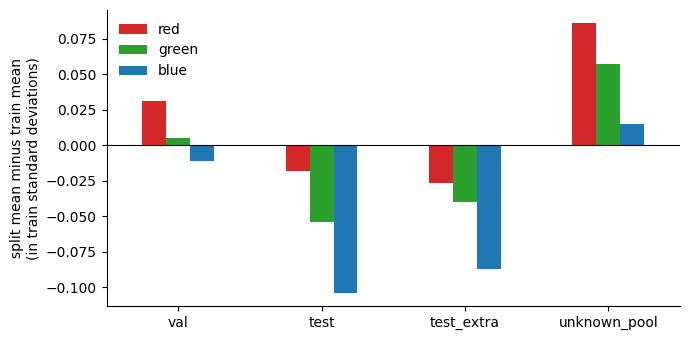

In [147]:
rgb_shift.drop(index="train").plot(kind="bar", color=["#d62728", "#2ca02c", "#1f77b4"], figsize=(7, 3.5))
plt.axhline(0, color="black", lw=0.8)
plt.ylabel("split mean minus train mean\n(in train standard deviations)")
plt.xticks(rotation=0)
plt.legend(frameon=False)
savefig("05c_rgb_shift")
plt.close()

A difference can come from chance, since each split here is only a few hundred to a few thousand photos. The Kruskal-Wallis test asks whether the photo means differ between splits more than chance would allow, the same test used in 5.8.

In [148]:
rgb_p = {c: img_kruskal([g[c] for _, g in rgb_df.groupby("split")]) for c in RGB_MEAN}
rgb_far = rgb_shift.drop(index="train").abs().stack()
print("Kruskal-Wallis p across splits:", {c[5:]: float(f"{p:.2g}") for c, p in rgb_p.items()})
print(f"largest gap to train: {rgb_far.max():.3f} train std ({rgb_far.idxmax()[0]}, {rgb_far.idxmax()[1]})")
print("train mean minus ImageNet mean:", np.round(rgb_mean - RGB_IMAGENET[0], 3).tolist())

Kruskal-Wallis p across splits: {'r': 0.015, 'g': 0.04, 'b': 0.009}
largest gap to train: 0.104 train std (test, blue)
train mean minus ImageNet mean: [-0.035, -0.024, -0.04]


In [149]:
check("a colour value exists for every photo in the sample", len(rgb_df) == len(quality), f"{rgb_failed} unreadable")
check("train channel means sit between 0 and 1 and the stds are positive", ((rgb_mean > 0) & (rgb_mean < 1) & (rgb_std > 0)).all())
check("the standard deviation of all pixels is at least the spread inside a photo", (rgb_std ** 2 >= rgb_train[RGB_VAR].mean().to_numpy()).all())

PASS  a colour value exists for every photo in the sample  (0 unreadable)
PASS  train channel means sit between 0 and 1 and the stds are positive
PASS  the standard deviation of all pixels is at least the spread inside a photo


On this sample the training photos are a little darker than the ImageNet defaults: the channel means are lower by about 0.02 to 0.04. Every split is close to train, within about 0.1 of a training standard deviation. The largest gap is test in blue, and unknown_pool leans the other way in red. The p values are small, but with this many photos even a small shift gives a small p value, so we read the size of the gap. For the model: the gap is small, so pretrained encoders can keep the ImageNet numbers, and the training numbers are worth testing. Keep brightness and contrast augmentation.

### 5.14 Embeddings: how the photos sit next to each other
Every number so far describes one photo on its own. An embedding turns a photo into a list of numbers so that photos that look alike end up close together. That lets us ask new questions: do val and test photos sit in the same places as training photos, are there copies the picture hash missed, and which photos look unlike their own species?

The model is DINOv2 small (Apache-2.0 licence, downloaded from Hugging Face). It was trained without our labels, so it shows what the photos look like and is not tuned to our classes. Each photo is squeezed to 224 by 224 pixels whole, without cropping, so nothing at the edges is cut off.

A forward pass of the model costs only a few photos per second on a CPU, so not every photo of the sample goes in. The notebook uses the graphics card when the Kaggle session has one (the run on Kaggle took well under a minute) and falls back to the processor when it does not. The embedding uses up to 8 training photos per species and every val, test and test_extra photo of the sample, because the splits are what we want to compare. Photos of species outside the 184 classes (the unknown pool) are left out.

This part needs a download from Hugging Face. If the model cannot be loaded, for example without internet, the cells say so, the embedding cells after it do nothing, and the rest of the notebook runs as usual. The embeddings are saved to `embeddings.npz` so a second run does not have to compute them again.

In [150]:
import subprocess
import sys

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [151]:
EMB_MODEL = "facebook/dinov2-small"
EMB_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
EMB_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
EMB_TRAIN_CAP = 8
emb_all = quality[quality["split"] != "unknown_pool"]
emb_train = emb_all[emb_all["split"] == "train"].groupby("species", group_keys=False).head(EMB_TRAIN_CAP)
emb_pick = pd.concat([emb_train, emb_all[emb_all["split"] != "train"]]).merge(
    meta[["photo_id", "observer_id", "in_india"]], on="photo_id", how="left").reset_index(drop=True)
print(f"{len(emb_pick):,} photos from {emb_pick['species'].nunique()} species go into the embedding")
emb_pick["split"].value_counts()

3,013 photos from 184 species go into the embedding


split
train         1472
val            700
test_extra     480
test           361
Name: count, dtype: int64

In [152]:
def emb_load():
    try:
        if os.environ.get("EMB_OFF") == "1":
            raise ImportError("switched off with EMB_OFF=1")
        import torch
        from transformers import AutoModel
        torch.set_num_threads(os.cpu_count() or 1)
        return torch, AutoModel.from_pretrained(EMB_MODEL).eval()
    except Exception as err:
        print("could not load the model, so the embedding cells are skipped:", str(err)[:150])
        return None, None

In [153]:
emb_torch, emb_model = emb_load()
if emb_model is not None:
    print("torch", emb_torch.__version__, "| weights:", round(sum(p.numel() for p in emb_model.parameters()) / 1e6, 1), "million")

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

torch 2.11.0+cu128 | weights: 22.1 million


In [154]:
emb_dev = "cpu"
if emb_model is not None and emb_torch.cuda.is_available():
    try:
        emb_model.to("cuda")
        with emb_torch.inference_mode():
            emb_model(pixel_values=emb_torch.zeros(2, 3, 224, 224, device="cuda")).pooler_output.cpu()
        emb_dev = "cuda"
    except Exception as err:
        emb_model.to("cpu")
        print("the graphics card could not run the model, so it runs on the processor:", str(err)[:120])
print("embedding device:", emb_dev)

embedding device: cuda


In [155]:
def emb_prep(path):
    pic = Image.open(img_file(path)).convert("RGB").resize((224, 224), Image.BILINEAR)
    return ((np.asarray(pic, dtype=np.float32) / 255 - EMB_MEAN) / EMB_STD).transpose(2, 0, 1)

Then the loop: read 64 photos at a time on four threads, push them through the model, and collect the 384 numbers per photo.

In [156]:
def emb_run(paths, batch=64):
    feats = []
    with ThreadPoolExecutor(max_workers=4) as pool:
        for i in tqdm(range(0, len(paths), batch), mininterval=15):
            x = np.stack(list(pool.map(emb_prep, paths[i:i + batch])))
            with emb_torch.inference_mode():
                x = emb_torch.from_numpy(x).to(emb_dev)
                feats.append(emb_model(pixel_values=x).pooler_output.cpu().numpy())
    return np.concatenate(feats)

In [157]:
def emb_get(ids, paths):
    cache = WORK / "embeddings.npz"
    if cache.exists():
        saved = np.load(cache)
        if saved["ids"].tolist() == ids:
            return saved["x"]
    x = emb_run(paths)
    np.savez(cache, x=x, ids=np.array(ids))
    return x

In [158]:
emb_X = None
emb_start = time.time()
if emb_model is not None:
    try:
        emb_X = emb_get(emb_pick["photo_id"].tolist(), emb_pick["path"].tolist())
    except Exception as err:
        print("the embedding run stopped:", str(err)[:150])
EMB_OK = emb_X is not None
if EMB_OK:
    print(f"{emb_X.shape[0]:,} photos x {emb_X.shape[1]} numbers each, {time.time() - emb_start:.0f} s")

100%|██████████| 48/48 [00:19<00:00,  2.50it/s]

3,013 photos x 384 numbers each, 19 s


In [159]:
check("the embeddings could be computed", EMB_OK)
if EMB_OK:
    check("one finite row of numbers per photo", emb_X.shape[0] == len(emb_pick) and bool(np.isfinite(emb_X).all()))

PASS  the embeddings could be computed
PASS  one finite row of numbers per photo


#### PCA and t-SNE
A photo is 384 numbers, which cannot be drawn. PCA keeps the directions along which the photos differ most. t-SNE then squeezes those into two axes so that neighbours stay neighbours. Distances between far-apart blobs mean little, but a blob is a group of photos that look alike.

In [160]:
if EMB_OK:
    emb_Xn = emb_X / np.linalg.norm(emb_X, axis=1, keepdims=True)
    emb_pca = PCA(50, random_state=SEED).fit(emb_Xn)
    emb_Z = emb_pca.transform(emb_Xn)
    emb_var = emb_pca.explained_variance_ratio_
    print(f"2 components keep {emb_var[:2].sum():.1%} of the spread, 10 keep {emb_var[:10].sum():.1%}, 50 keep {emb_var.sum():.1%}")

2 components keep 13.4% of the spread, 10 keep 36.1%, 50 keep 68.4%


In [161]:
emb_xy = None
if EMB_OK:
    tsne_start = time.time()
    try:
        emb_xy = TSNE(2, init="pca", perplexity=30, random_state=SEED, n_jobs=4).fit_transform(emb_Z)
        print(f"t-SNE of {len(emb_xy):,} photos took {time.time() - tsne_start:.0f} s")
    except Exception as err:
        print("t-SNE did not run, the map is skipped:", str(err)[:120])

t-SNE of 3,013 photos took 13 s


In [162]:
EMB_SPLIT = {"train": "#c8d0da", "val": "#4c78a8", "test": "#e45756", "test_extra": "#f2a900", "unknown_pool": "#7f7f7f"}
EMB_WHO = {WHO_LABEL[k]: v for k, v in WHO_COLORS.items()}

One small function draws a scatter of the t-SNE points, coloured by whatever labels it is given.

In [163]:
def emb_panel(ax, title, labels, colours, order):
    labels = np.asarray(labels)
    for name in order:
        hit = labels == name
        if not hit.any():
            continue
        ax.scatter(emb_xy[hit, 0], emb_xy[hit, 1], s=4, c=colours[name], label=name, alpha=0.7, linewidths=0)
    ax.set(title=title, xticks=[], yticks=[])
    ax.legend(markerscale=3, frameon=False, fontsize=8)

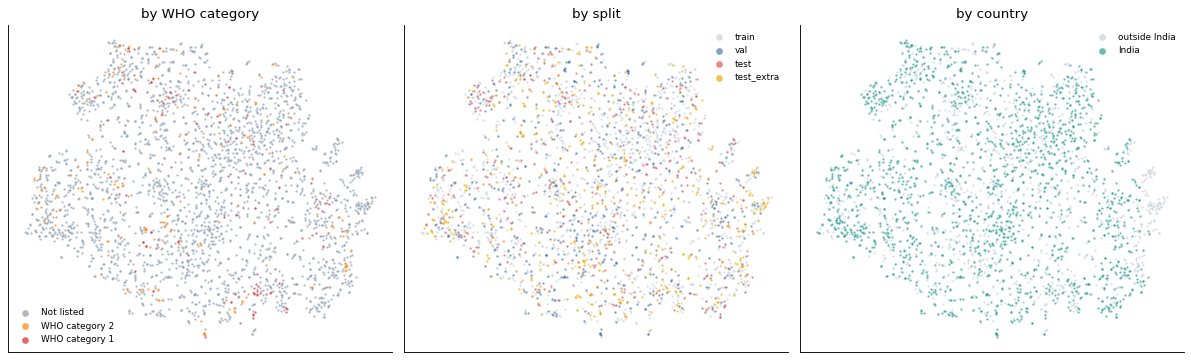

In [164]:
if emb_xy is not None:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), dpi=80)
    emb_panel(axes[0], "by WHO category", emb_pick["who_category"].map(WHO_LABEL), EMB_WHO, ["Not listed", "WHO category 2", "WHO category 1"])
    emb_panel(axes[1], "by split", emb_pick["split"], EMB_SPLIT, list(EMB_SPLIT))
    where = np.where(emb_pick["in_india"].astype(bool), "India", "outside India")
    emb_panel(axes[2], "by country", where, {"India": "#2a9d8f", "outside India": "#c8d0da"}, ["outside India", "India"])
    savefig("05d_tsne")
    plt.close()

The map is one mixed cloud. The WHO category 1 and 2 photos (red and orange) are spread through it and do not form a region of their own, and the splits overlap everywhere, which is what a fair split should look like. Photos from outside India are fewer and mostly sit among the Indian ones, with a small group at the right edge. The small tight groups are probably several photos of one species or one sighting. Only points that sit close together mean anything on a t-SNE map.

#### Do val and test look like training?
If the splits are drawn from the same kind of photo, a model should not be able to tell which split a photo came from. To test that, I train a small classifier to separate training photos from val, test and test_extra photos in turn. Its score is an AUC: 0.5 means it cannot tell them apart, 1.0 means it always can.

Two details make this fair. First, each photo's species average is subtracted, so the classifier cannot just learn that the splits contain different species and has to use what is left, such as background, camera and style. Second, the folds are grouped by photographer, so it is judged on photographers it has not seen. Val is the control: it was drawn the same way as train.

In [165]:
def emb_domain_auc(other):
    rows = emb_pick["split"].isin(["train", other]).to_numpy()
    y = (emb_pick.loc[rows, "split"] == other).astype(int).to_numpy()
    model = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=300, class_weight="balanced"))
    try:
        score = cross_val_predict(model, emb_centred[rows], y, cv=GroupKFold(5), groups=emb_group[rows], method="decision_function")
        return roc_auc_score(y, score)
    except Exception as err:
        print(f"no AUC for {other}:", str(err)[:100])
        return np.nan

In [166]:
if EMB_OK:
    emb_centred = emb_Xn - pd.DataFrame(emb_Xn).groupby(emb_pick["species"].to_numpy()).transform("mean").to_numpy()
    emb_group = pd.factorize(emb_pick["observer_id"])[0]
    emb_auc = pd.Series({s: emb_domain_auc(s) for s in ["val", "test", "test_extra"] if (emb_pick["split"] == s).sum() >= 30})
    display(emb_auc.rename("AUC against train").round(3))

val           0.525
test          0.502
test_extra    0.559
Name: AUC against train, dtype: float64

All three scores sit close to 0.5: val, the control, scores 0.53, test 0.50 and test_extra 0.56. So once the species effect is removed, this classifier cannot tell test photos from training photos, and barely tells test_extra apart. This does not prove there is no shift, only that a simple classifier on these features cannot find much of one.

#### Copies the picture hash missed
For every photo, find the most similar photo taken by a different photographer. A cosine similarity of 1 would be the same picture. The picture hash only catches copies that are nearly pixel-identical, the embedding also catches the same scene shot from a slightly different place.

In [167]:
def emb_neighbours(Xn, groups, step=512):
    idx = np.zeros(len(Xn), dtype=int)
    sim = np.zeros(len(Xn), dtype=np.float32)
    for i in range(0, len(Xn), step):
        block = Xn[i:i + step] @ Xn.T
        block[groups[i:i + step, None] == groups[None, :]] = -1
        idx[i:i + step], sim[i:i + step] = block.argmax(axis=1), block.max(axis=1)
    return idx, sim

In [168]:
if EMB_OK:
    emb_nn, emb_sim = emb_neighbours(emb_Xn, emb_group)
    emb_kin = emb_pick["species"].to_numpy()[emb_nn] == emb_pick["species"].to_numpy()
    print(f"the closest photo from another photographer is the same species for {emb_kin.mean():.1%} of the photos")
    print(f"similarity of that closest photo: median {np.median(emb_sim):.3f}, 99th percentile {np.quantile(emb_sim, 0.99):.3f}")
    for cut in (0.9, 0.95):
        print(f"{(emb_sim >= cut).sum():,} photos have a photo from another photographer at similarity {cut} or more")

the closest photo from another photographer is the same species for 19.2% of the photos
similarity of that closest photo: median 0.684, 99th percentile 0.865
9 photos have a photo from another photographer at similarity 0.9 or more
0 photos have a photo from another photographer at similarity 0.95 or more


In [169]:
if EMB_OK:
    emb_chance = 1 / emb_pick["species"].nunique()
    check("the closest photo of another photographer is the same species at least five times as often as chance",
          emb_kin.mean() > 5 * emb_chance, f"{emb_kin.mean():.1%} against about {emb_chance:.1%} by chance")

PASS  the closest photo of another photographer is the same species at least five times as often as chance  (19.2% against about 0.5% by chance)


In [170]:
if EMB_OK:
    emb_pair = pd.DataFrame({"a": np.arange(len(emb_nn)), "b": emb_nn, "similarity": emb_sim})
    emb_pair["key"] = [tuple(sorted(p)) for p in zip(emb_pair["a"], emb_pair["b"])]
    emb_pair = emb_pair.drop_duplicates("key").sort_values("similarity", ascending=False).reset_index(drop=True)
    for side, col in (("a", "a"), ("b", "b")):
        for name in ("photo_id", "species", "split"):
            emb_pair[f"{name}_{side}"] = emb_pick[name].to_numpy()[emb_pair[col]]
    emb_close = emb_pair[emb_pair["similarity"] >= 0.95]
    print(f"{len(emb_close)} pairs at 0.95 or more, {(emb_close['split_a'] != emb_close['split_b']).sum()} of them across two splits")
    display(emb_pair[["photo_id_a", "photo_id_b", "species_a", "species_b", "split_a", "split_b", "similarity"]].head(10).round(3))

0 pairs at 0.95 or more, 0 of them across two splits


,photo_id_a,photo_id_b,species_a,species_b,split_a,split_b,similarity
0,81415397,83013548,Bungarus niger,Bungarus niger,train,test_extra,0.921
1,676628633,695755741,Pareas monticola,Pareas monticola,train,test_extra,0.912
2,384687542,390680649,Oligodon albocinctus,Oligodon albocinctus,train,test,0.902
3,83013571,81415397,Bungarus niger,Bungarus niger,test_extra,train,0.901
4,435074137,175170990,Laticauda colubrina,Laticauda colubrina,train,test_extra,0.901
5,556963408,748389429,Bungarus fasciatus,Bungarus fasciatus,test_extra,test_extra,0.896
6,681270113,680849497,Uropeltis ceylanica,Uropeltis ceylanica,train,val,0.892
7,417205837,523872111,Plectrurus perroteti,Plectrurus perroteti,test,val,0.887
8,145798089,556963408,Bungarus fasciatus,Bungarus fasciatus,test_extra,test_extra,0.884
9,207818544,398503361,Hydrophis ornatus,Hydrophis ornatus,train,test_extra,0.881


For about one photo in five the closest photo from another photographer is of the same species. That is about 35 times the chance rate of one in 184, so the embedding clearly knows what a species looks like. Most photos have no near twin: the median closest similarity is below 0.7. A handful do: 9 photos have a match from another photographer at 0.9 or more, and none reaches 0.95, so the licence filter and near-copy step removed the closest pairs. Those 9 are the first photos to look at.

#### Photos far from their own species
For each species with at least five photos in the embedding, the average embedding is its centre. The photos farthest from their own centre are the odd ones: a different life stage, a skin on the ground, a photo of the wrong animal. This is a rough first screen and the next section sharpens it.

In [171]:
if EMB_OK:
    emb_size = emb_pick.groupby("species")["photo_id"].transform("size").to_numpy()
    emb_centre = pd.DataFrame(emb_Xn).groupby(emb_pick["species"].to_numpy()).transform("mean").to_numpy()
    emb_off = 1 - (emb_Xn * emb_centre).sum(axis=1) / np.linalg.norm(emb_centre, axis=1)
    emb_far = emb_pick.assign(distance=emb_off)[emb_size >= 5].nlargest(10, "distance")
    display(emb_far[["photo_id", "species", "who_category", "split", "distance"]].round(3).reset_index(drop=True))

,photo_id,species,who_category,split,distance
0,354982054,Hydrophis schistosus,not_listed,test,0.876
1,569551537,Bungarus caeruleus,1,val,0.875
2,41404717,Protobothrops mucrosquamatus,not_listed,train,0.868
3,243796115,Lycodon nympha,not_listed,train,0.849
4,317272023,Coelognathus helena,not_listed,train,0.846
5,331401983,Oligodon arnensis,not_listed,test,0.845
6,712993270,Sibynophis collaris,not_listed,test_extra,0.844
7,234438780,Ptyas mucosa,not_listed,test,0.844
8,557468053,Gonyosoma frenatum,not_listed,train,0.843
9,613623763,Spalerosophis atriceps,not_listed,test_extra,0.838


Most of the farthest photos are of not-listed species, which is simply most species. The one WHO-listed species among them is the common krait, *Bungarus caeruleus* (category 1). I have not opened these photos here. The next section looks at photos instead.

### 5.15 Photos that may carry the wrong label
Label noise is one of the risks listed in the milestone 1 report. The method here is confident learning: train a simple classifier on the embeddings, but always predict each photo with a model that has not seen that photographer, then flag the photos whose own label gets a low probability while another species gets a high one. The flagged photos are candidates to look at, not proven mistakes. A hard pose or a young snake can be flagged too.

In [172]:
def cl_import():
    try:
        from cleanlab.filter import find_label_issues
        return find_label_issues
    except ImportError:
        return None

Cleanlab is not always installed on Kaggle. If the import fails, install it once and try again.

In [173]:
def cl_install():
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cleanlab"], capture_output=True, text=True, timeout=300)
        import importlib
        importlib.invalidate_caches()
        return cl_import()
    except Exception as err:
        print("cleanlab is not available, so the label-issue list is skipped:", str(err)[:120])
        return None

In [174]:
cl_find = (cl_import() or cl_install()) if EMB_OK else None
CL_OK = cl_find is not None
check("the label-issue finder could be loaded", CL_OK or not EMB_OK)
if CL_OK:
    import cleanlab
    print("cleanlab", cleanlab.__version__)

PASS  the label-issue finder could be loaded
cleanlab 2.9.0


Species with fewer than ten photos in the embedding are left out of this step, because a classifier cannot learn them well and every photo would look suspicious. Each of the five folds keeps whole photographers together.

In [175]:
if CL_OK:
    cl_keep = emb_size >= (2 if SMOKE else 10)
    cl_rows = emb_pick[cl_keep].reset_index(drop=True)
    cl_codes, cl_names = pd.factorize(cl_rows["species"])
    print(f"{len(cl_rows):,} photos of {len(cl_names)} species go into the classifier")

2,996 photos of 182 species go into the classifier


The classifier is a plain logistic regression on the embeddings. Five folds, with every photographer kept in one fold, so each photo is predicted by a model that has never seen that photographer.

In [176]:
if CL_OK:
    cl_folds = StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
    cl_model = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=200))
    cl_start = time.time()
    try:
        cl_probs = cross_val_predict(cl_model, emb_Xn[cl_keep], cl_codes, cv=cl_folds, groups=emb_group[cl_keep], method="predict_proba")
        print(f"out-of-fold predictions took {time.time() - cl_start:.0f} s")
        print(f"accuracy of the simple classifier on unseen photographers: {(cl_probs.argmax(axis=1) == cl_codes).mean():.1%}")
    except Exception as err:
        print("the out-of-fold predictions failed, the label-issue list is skipped:", str(err)[:120])
        CL_OK = False

out-of-fold predictions took 38 s
accuracy of the simple classifier on unseen photographers: 25.9%


In [177]:
if CL_OK:
    cl_idx = cl_find(cl_codes, cl_probs, return_indices_ranked_by="self_confidence")
    cl_table = cl_rows.iloc[cl_idx].assign(rank=range(1, len(cl_idx) + 1))
    cl_table["guess"] = cl_names[cl_probs[cl_idx].argmax(axis=1)]
    cl_table["p_label"] = cl_probs[cl_idx, cl_codes[cl_idx]]
    cl_table["p_guess"] = cl_probs[cl_idx].max(axis=1)
    cl_table["guess_who"] = cl_table["guess"].map(who_of)
    print(f"{len(cl_table):,} of {len(cl_rows):,} photos flagged ({len(cl_table) / len(cl_rows):.1%})")
    print(f"{int((cl_table['p_label'] < 0.01).sum()):,} of them give their own label a probability under 1%")
    display(cl_table[["rank", "photo_id", "species", "guess", "p_label", "p_guess", "who_category", "split"]].head(15).round(3).reset_index(drop=True))

1,930 of 2,996 photos flagged (64.4%)
682 of them give their own label a probability under 1%


,rank,photo_id,species,guess,p_label,p_guess,who_category,split
0,1,741447789,Elaphe taeniura,Trimeresurus andersonii,0.0,0.120,not_listed,test_extra
1,2,460643233,Ahaetulla borealis,Rhabdophis himalayanus,0.0,0.166,not_listed,train
2,3,719708842,Craspedocephalus macrolepis,Trimeresurus erythrurus,0.0,0.385,not_listed,val
3,4,152445364,Dieurostus dussumieri,Gerarda prevostiana,0.0,0.347,not_listed,test_extra
4,5,460577939,Dendrelaphis grandoculis,Ahaetulla borealis,0.0,0.375,not_listed,train
5,6,365662148,Oligodon cinereus,Python molurus,0.0,0.211,not_listed,val
6,7,557468053,Gonyosoma frenatum,Ahaetulla laudankia,0.0,0.226,not_listed,train
7,8,597574861,Ahaetulla farnsworthi,Lycodon travancoricus,0.0,0.090,not_listed,val
8,9,334533976,Ahaetulla perroteti,Craspedocephalus gramineus,0.0,0.274,not_listed,train
9,10,519581729,Oligodon taeniolatus,Platyceps ventromaculatus,0.0,0.085,not_listed,train


In [178]:
if CL_OK:
    cl_table.to_csv(WORK / "label_issue_candidates.csv", index=False)
    cl_flag = cl_rows["photo_id"].isin(cl_table["photo_id"])
    print("share flagged by WHO category (%):", cl_rows.assign(flag=cl_flag).groupby("who_category")["flag"].mean().mul(100).round(1).to_dict())
    print(f"flagged photos where the guess is in another WHO category: {(cl_table['guess_who'] != cl_table['who_category']).mean():.1%}")
    cl_pairs = {frozenset(p[:2]) for p in LOOKALIKES + DANGEROUS}
    cl_hits = [frozenset((a, b)) in cl_pairs for a, b in zip(cl_table["species"], cl_table["guess"])]
    print(f"flagged photos whose label and guess are a known look-alike pair: {sum(cl_hits)}")

share flagged by WHO category (%): {'1': 59.4, '2': 67.4, 'not_listed': 64.4}
flagged photos where the guess is in another WHO category: 17.7%
flagged photos whose label and guess are a known look-alike pair: 9


Almost two thirds of the photos flagged is far too many to be a list of mistakes. The simple classifier has 182 species and about 16 photos of each, and on photographers it has not seen it gets only about a quarter of the photos right, so it disagrees with the label most of the time. What is useful is the order. The photos at the top give their own label a probability close to zero and are the ones to check first. Every WHO group is flagged at about the same rate, so no group is singled out, which is what a weak classifier produces. Two parts are worth a hand check: the flagged photos whose guess is in another WHO category, and the flagged photos whose label and guess are a known look-alike pair, because a dangerous snake taken for a harmless one, or the other way round, is the costliest label mistake. The whole list is saved as `label_issue_candidates.csv`, ready for the hand check planned in Milestone 3.

The most suspicious photos that can be shown (CC0 or CC BY first, no detected face). The caption reads *label > what the classifier thinks it is*.

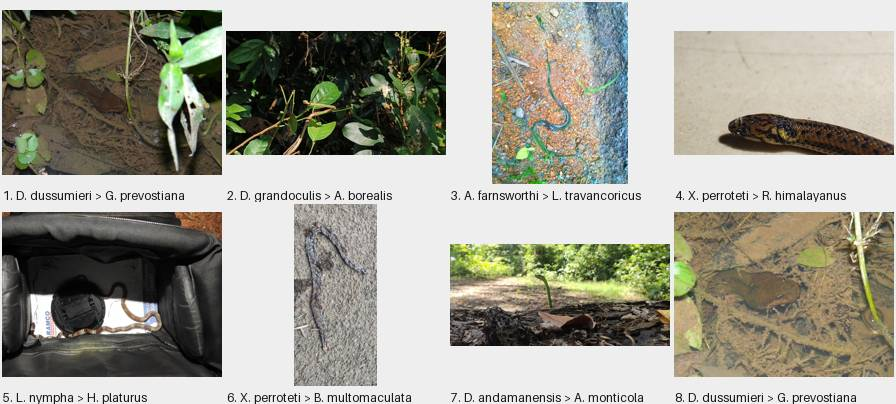

,species,WHO,guess,p_label,licence,credit
1,Dieurostus dussumieri,Not listed,Gerarda prevostiana,0.0,cc-by,"(c) Ansil B.R., some rights reserved (CC BY)"
2,Dendrelaphis grandoculis,Not listed,Ahaetulla borealis,0.0,cc0,no rights reserved
3,Ahaetulla farnsworthi,Not listed,Lycodon travancoricus,0.0,cc0,no rights reserved
4,Xylophis perroteti,Not listed,Rhabdophis himalayanus,0.0,cc-by,"(c) Siya ul haque, some rights reserved (CC BY)"
5,Lycodon nympha,Not listed,Hydrophis platurus,0.0,cc-by,"(c) Hopeland, some rights reserved (CC BY)"
6,Xylophis perroteti,Not listed,Boiga multomaculata,0.0,cc-by,"(c) T R Shankar Raman, some rights reserved (CC BY)"
7,Dendrelaphis andamanensis,Not listed,Amphiesma monticola,0.0,cc-by,"(c) Prathamesh Khedwan, some rights reserved (CC BY)"
8,Dieurostus dussumieri,Not listed,Gerarda prevostiana,0.0,cc-by,"(c) Ansil B.R., some rights reserved (CC BY)"


In [179]:
if CL_OK:
    cl_view = img_label(img_pick(cl_table, 8, ("rank", True)))
    cl_entries = [(r.path, f"{r.label}. {img_short(r.species)} > {img_short(r.guess)}") for r in cl_view.itertuples()]
    img_show(img_grid(cl_entries))
    img_credits(cl_view, extra=("guess", "p_label"))

Most of these eight show a snake that is tiny or hidden among leaves, and one is inside a bag. So the classifier is mostly unsure because the snake is hard to see, which is a photo-quality problem more than a wrong label. This fits the masks in 7b, where the detector found no snake in some photos. A clear photo such as number 4 is the kind worth a hand check. Nothing should be deleted or relabelled from this list before someone has looked at the photo.

### 5.16 How big is the snake at the model's input size?
Every photo gets shrunk to one fixed size before a model sees it, most likely 224 or 384 pixels on the long side. A snake that fills a third of the frame can end up only a few pixels wide, and a model cannot learn from a smudge. The snake detector from the masks dataset gives a box around each snake, so the size can be measured instead of guessed.

Masks exist for training photos only, so this section says nothing about val and test.

A box is stored as text like `[[x1, y1, x2, y2]]`. This small function reads it and returns the longer side of the biggest box.

In [180]:
import json

def snk_longest(text):
    try:
        return max(max(b[2] - b[0], b[3] - b[1]) for b in json.loads(text))
    except Exception:
        return np.nan

Keep the photos where the detector found at least one snake, and add each photo's width and height from the metadata.

In [181]:
SNK_OK = False
try:
    snk = mask_stats[mask_stats["n_snake_boxes"] >= 1]
    snk = snk.merge(meta[["photo_id", "width", "height"]], on="photo_id", how="left")
    SNK_OK = len(snk) > 0
except Exception as err:
    print("snake sizes skipped:", str(err)[:120])
print(f"{len(snk):,} training photos with a snake box" if SNK_OK else "no snake boxes")

82,354 training photos with a snake box


The size that matters is the box length as a share of the photo's long side. That share stays the same whatever size the photo is shrunk to.

In [182]:
if SNK_OK:
    snk["box_long"] = snk["snake_boxes"].map(snk_longest)
    snk["photo_long"] = snk[["width", "height"]].max(axis=1)
    snk["share"] = snk["box_long"] / snk["photo_long"]
    snk = snk.dropna(subset=["share"])
    print(f"median share: {snk['share'].median():.0%} of the long side")

median share: 64% of the long side


Now the sum. If the photo is shrunk so its long side is 224 px, a box that spans 30% of it is about 67 px long. The table does this for three input sizes and counts the snakes that end up shorter than 32, 64 and 100 px.

In [183]:
SNK_INPUT = (224, 256, 384)
SNK_CUTS = (32, 64, 100)

In [184]:
if SNK_OK:
    snk_rows = {}
    for size in SNK_INPUT:
        row = {}
        for cut in SNK_CUTS:
            row[f"shorter than {cut} px (%)"] = 100 * (snk["share"] * size < cut).mean()
        row["median length (px)"] = snk["share"].median() * size
        snk_rows[f"{size} px input"] = row
    display(pd.DataFrame(snk_rows).round(1))

,224 px input,256 px input,384 px input
shorter than 32 px (%),0.9,0.6,0.2
shorter than 64 px (%),6.8,4.7,1.4
shorter than 100 px (%),21.7,15.5,5.2
median length (px),142.3,162.6,243.9


At a 224 px input the median snake is about 140 px long, which is plenty. The trouble is in the tail: about 7 snakes in 100 are shorter than 64 px, and about 22 in 100 are shorter than 100 px. At 384 px those drop to about 1 in 100 and 5 in 100. So a bigger input helps the small snakes most, and cropping to the detected box first would remove the problem altogether.

Is it different for the dangerous snakes? Here the share of snakes shorter than 64 px at a 224 px input, by WHO category.

In [185]:
if SNK_OK:
    snk["small_224"] = snk["share"] * 224 < 64
    snk_who = snk.groupby("who_category").agg(photos=("share", "size"), median_share=("share", "median"), small=("small_224", "mean"))
    snk_who["small"] = (100 * snk_who["small"]).round(1)
    snk_who.index = snk_who.index.map(WHO_LABEL)
    display(snk_who.round(2))

,photos,median_share,small
who_category,,,
WHO category 1,6281,0.60,9.2
WHO category 2,4360,0.64,5.8
Not listed,71713,0.64,6.6


And the species where small snakes are most common (only species with at least 50 masks).

In [186]:
if SNK_OK:
    snk_sp = snk.groupby("species").agg(photos=("share", "size"), small=("small_224", "mean"))
    snk_sp = snk_sp[snk_sp["photos"] >= 50]
    snk_sp["small"] = (100 * snk_sp["small"]).round(1)
    snk_sp["WHO"] = snk_sp.index.map(who_of).map(WHO_LABEL)
    display(snk_sp.sort_values("small", ascending=False).head(8))

,photos,small,WHO
species,,,
Trimeresurus andersonii,58,19.0,Not listed
Hydrophis stokesii,87,14.9,Not listed
Craspedocephalus travancoricus,66,13.6,Not listed
Echis carinatus,1187,13.0,WHO category 1
Ophiophagus kaalinga,62,12.9,WHO category 2
Indotyphlops braminus,8670,12.8,Not listed
Hydrophis platurus,826,12.0,Not listed
Dieurostus dussumieri,61,11.5,Not listed


Small snakes are a little more common among WHO category 1 photos (9.2%) than category 2 (5.8%) or not-listed (6.6%). The species list is led by *Trimeresurus andersonii* (19.0% of its 58 masks). The largest class near the top is *Echis carinatus* (13.0% of its 1,187 masks), which is category 1, so for that species a 384 px input or a crop to the box is the first thing to test.

The same thing as a chart: how many snakes are shorter than a given length at each input size. The dashed line is 64 px.

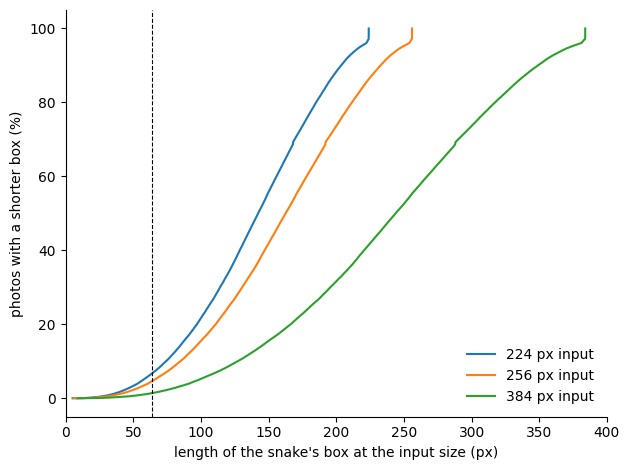

In [187]:
if SNK_OK:
    for size in SNK_INPUT:
        v = np.sort(snk["share"].to_numpy() * size)
        plt.plot(v, np.arange(1, len(v) + 1) / len(v) * 100, label=f"{size} px input")
    plt.axvline(64, color="k", ls="--", lw=0.8)
    plt.xlabel("length of the snake's box at the input size (px)")
    plt.ylabel("photos with a shorter box (%)")
    plt.xlim(0, 400)
    plt.legend(frameon=False)
    savefig("05e_snake_size")
    plt.close()

In [188]:
check("every snake box has a positive length", (not SNK_OK) or bool((snk["box_long"] > 0).all()))
check("no snake box is longer than its photo", (not SNK_OK) or bool((snk["share"] <= 1.02).all()))

PASS  every snake box has a positive length
PASS  no snake box is longer than its photo


### 5.17 Photo issue flags
Section 5 measured every sampled photo. Here the measures become simple yes-or-no flags, the way automatic dataset cleaners do it. The limits are my own choice, so they are easy to argue with. The aim is to see how many photos a cleaning rule would touch, and whether some classes would be hit much harder than others.

One column per flag. Too dark and too bright use the average brightness (0 to 255), blurry uses the sharpness number from 5.2, flat uses the contrast, grey uses the saturation, and tiny uses the short side in pixels.

In [189]:
flg = pd.DataFrame(index=quality.index)
flg["dark"] = quality["brightness"] < 50
flg["overexposed"] = quality["brightness"] > 200
flg["blurry"] = quality["sharpness"] < 100
flg["low contrast"] = quality["contrast"] < 20
flg["grey"] = quality["saturation"] < 0.04
flg["tiny"] = quality["short_side"] < 224

An odd shape is a photo that is more than twice as long as it is wide.

In [190]:
long_side = quality[["width", "height"]].max(axis=1)
short_side = quality[["width", "height"]].min(axis=1)
flg["odd shape"] = long_side / short_side > 2
flg["any issue"] = flg.any(axis=1)
print(f"{flg['any issue'].mean():.1%} of the {len(flg):,} sampled photos have at least one flag")

17.2% of the 6,249 sampled photos have at least one flag


How common is each flag?

In [191]:
(100 * flg.mean()).round(1).rename("share of photos (%)").to_frame()

,share of photos (%)
dark,8.0
overexposed,0.4
blurry,1.2
low contrast,2.8
grey,1.1
tiny,0.6
odd shape,5.9
any issue,17.2


And by split. If test photos have more problems than train photos, that is a shift worth knowing about.

In [192]:
flg_split = 100 * flg.groupby(quality["split"].to_numpy()).mean()
flg_split = flg_split.reindex(SPLIT_ORDER).dropna().round(1)
flg_split.T

,train,val,test,test_extra,unknown_pool
dark,8.2,8.9,10.0,7.7,5.4
overexposed,0.4,0.6,0.3,0.2,0.6
blurry,1.4,0.7,1.1,1.2,0.7
low contrast,3.0,3.0,1.4,2.9,2.3
grey,1.2,0.6,0.8,1.2,1.1
tiny,0.5,0.7,1.7,0.2,0.6
odd shape,5.0,7.4,14.1,2.9,7.1
any issue,16.6,19.7,26.3,14.8,15.5


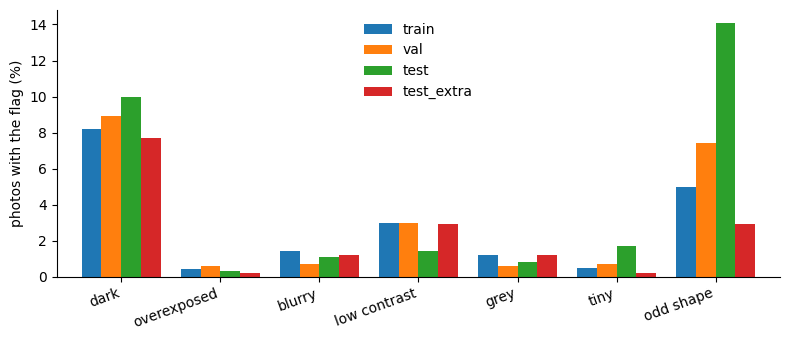

In [193]:
flg_split.drop(columns="any issue").drop(index="unknown_pool", errors="ignore").T.plot(kind="bar", figsize=(8, 3.5), width=0.8)
plt.ylabel("photos with the flag (%)")
plt.xticks(rotation=20, ha="right")
plt.legend(frameon=False)
savefig("05f_issue_flags")
plt.close()

Dark photos are the commonest problem (about 8 in 100), then odd shapes (6 in 100). Blurry, overexposed and tiny photos are rare, about 1 in 100 or fewer. test has the most dark photos (10%) and the most odd shapes (14% against 5% in train), which is in line with the portrait photos found in 3.6. About 17% of train photos have a flag, against 20% of val, 26% of test and 15% of test_extra.

Is some group hit harder? First by WHO category, then by species (species with at least 10 sampled photos).

In [194]:
FLG_MIN = 3 if SMOKE else 10
who_names = quality["who_category"].map(WHO_LABEL).to_numpy()
flg_who = 100 * flg["any issue"].groupby(who_names).mean()
print("share with any flag by WHO category (%):", flg_who.round(1).to_dict())

share with any flag by WHO category (%): {'Not listed': 17.4, 'WHO category 1': 11.1, 'WHO category 2': 18.2}


In [195]:
flg_sp = flg["any issue"].groupby(quality["species"].to_numpy()).agg(["mean", "size"])
flg_sp = flg_sp[flg_sp["size"] >= FLG_MIN]
print(f"{int((flg_sp['mean'] > 0.2).sum())} of {len(flg_sp)} species have more than 20% flagged photos")
print(f"the highest share for one species is {flg_sp['mean'].max():.0%} ({flg_sp['mean'].idxmax()})")

68 of 223 species have more than 20% flagged photos
the highest share for one species is 94% (Dendrelaphis biloreatus)


A cleaning rule would not drop every flag. A grey or low-contrast snake can be a real snake, and an odd shape is only a reason to pad instead of crop. The flags that make a photo unusable are dark, overexposed, blurry and tiny. What would dropping those four cost?

In [196]:
FLG_DROP = ["dark", "overexposed", "blurry", "tiny"]
flg_gone = flg[FLG_DROP].any(axis=1)
print(f"dropping {FLG_DROP} would remove {100 * flg_gone.mean():.1f}% of the sampled photos")

dropping ['dark', 'overexposed', 'blurry', 'tiny'] would remove 9.8% of the sampled photos


In [197]:
gone_who = 100 * flg_gone.groupby(who_names).mean()
print("share removed by WHO category (%):", gone_who.round(1).to_dict())

share removed by WHO category (%): {'Not listed': 9.9, 'WHO category 1': 4.4, 'WHO category 2': 12.7}


In [198]:
flg_loss = flg_gone.groupby(quality["species"].to_numpy()).agg(["mean", "size"])
flg_loss = flg_loss[flg_loss["size"] >= FLG_MIN]
print(f"the biggest loss for one species is {flg_loss['mean'].max():.0%} ({flg_loss['mean'].idxmax()})")
print(f"{int((flg_loss['mean'] > 0.1).sum())} species would lose more than 10% of their photos")

the biggest loss for one species is 50% (Craspedocephalus peltopelor)
65 species would lose more than 10% of their photos


What if only the two clear failures, blurry and tiny, were dropped?

In [199]:
flg_hard = flg[["blurry", "tiny"]].any(axis=1)
print(f"dropping only blurry and tiny would remove {100 * flg_hard.mean():.1f}% of the sampled photos")

dropping only blurry and tiny would remove 1.8% of the sampled photos


Dropping all four flags removes almost 10% of the photos, which is a lot for a cleaning rule, and the loss is uneven: 12.7% for WHO category 2 against 4.4% for category 1, and half of the photos of one species. Dark photos are most of it, and many snakes are only seen at night, so a dark photo can be the normal photo of that species. I would not drop dark photos. Dropping only blurry and tiny ones is a much smaller change, 1.8% of the sample. The species counts here include the species outside the 184 classes, because the sample holds those too.

In [200]:
check("a flag value exists for every sampled photo", len(flg) == len(quality) and bool(flg.notna().all().all()))

PASS  a flag value exists for every sampled photo


### 5.18 A map of the species
Section 5.14 compared photos. Here the photos of each species are averaged into one point, so that species can be compared with species. Two questions. Does the embedding know about taxonomy, so that a genus or family head would have something to learn from? And which dangerous species have a harmless look-alike that is not on our list of nine pairs?

Only species with at least five photos in the embedding are used.

In [201]:
MAP_OK = False
if EMB_OK:
    map_n = emb_pick.groupby("species").size()
    map_sp = map_n[map_n >= (2 if SMOKE else 5)].index.to_numpy()
    print(f"{len(map_sp)} species have at least five photos in the embedding")

184 species have at least five photos in the embedding


The centre of a species is the average of its photos' embeddings. Each centre is rescaled to length 1, so that multiplying two of them gives their cosine similarity.

In [202]:
if EMB_OK:
    centres = pd.DataFrame(emb_Xn).groupby(emb_pick["species"].to_numpy()).mean()
    map_c = centres.loc[map_sp].to_numpy()
    map_c = map_c / np.linalg.norm(map_c, axis=1, keepdims=True)
    print("species centres:", map_c.shape)

species centres: (184, 384)


One table with every species against every other. The diagonal (a species against itself) is set to -1 so it is never picked as a neighbour.

In [203]:
if EMB_OK:
    map_sim = map_c @ map_c.T
    np.fill_diagonal(map_sim, -1)
    map_tax = meta.drop_duplicates("species").set_index("species")[["genus", "family"]]
    MAP_OK = True
    print("similarity table:", map_sim.shape)

similarity table: (184, 184)


Does the embedding know taxonomy? Look at the closest photo from another photographer (found in 5.14) and ask whether it is in the same genus. Chance is what you would get if the neighbour were a random photo.

In [204]:
if MAP_OK:
    genus = emb_pick["species"].map(map_tax["genus"]).to_numpy()
    chance = (pd.Series(genus).value_counts(normalize=True) ** 2).sum()
    print(f"same genus for {(genus[emb_nn] == genus).mean():.1%} of the photos (chance about {chance:.1%})")

same genus for 35.7% of the photos (chance about 3.0%)


In [205]:
if MAP_OK:
    family = emb_pick["species"].map(map_tax["family"]).to_numpy()
    chance = (pd.Series(family).value_counts(normalize=True) ** 2).sum()
    print(f"same family for {(family[emb_nn] == family).mean():.1%} of the photos (chance about {chance:.1%})")

same family for 63.9% of the photos (chance about 34.2%)


The same question for whole species: is the nearest species in the same genus? This only makes sense for species whose genus has a second species in the table.

In [206]:
if MAP_OK:
    gen = map_tax.loc[map_sp, "genus"]
    has_sibling = gen.map(gen.value_counts()).to_numpy() > 1
    nearest = map_sim.argmax(axis=1)
    same_genus = gen.to_numpy()[nearest] == gen.to_numpy()
    print(f"{same_genus[has_sibling].mean():.1%} of the {int(has_sibling.sum())} species with a sibling have it as their nearest species")

47.7% of the 151 species with a sibling have it as their nearest species


The embedding does know taxonomy. The closest photo from another photographer is in the same genus for 35.7% of photos where chance would give 3.0%, about twelve times better, and in the same family for 63.9% against 34.2%, about twice. At species level, 48% of the species that have a sibling have it as their nearest species. So a genus head and a family head would have something to learn from.

Now the nine lookalike pairs and the two pairs of dangerous snakes. The rank says how many other species come closer: rank 1 means the partner is the nearest species of all.

In [207]:
if MAP_OK:
    pos = {name: i for i, name in enumerate(map_sp)}

    def rank_of(a, b):
        return int((map_sim[pos[a]] > map_sim[pos[a], pos[b]]).sum()) + 1

In [208]:
if MAP_OK:
    pair_rows = []
    for a, b, name in LOOKALIKES + DANGEROUS:
        if a in pos and b in pos:
            pair_rows.append({"pair": name, "similarity": map_sim[pos[a], pos[b]],
                              "rank from the dangerous side": rank_of(a, b), "rank from the other side": rank_of(b, a)})
    display(pd.DataFrame(pair_rows).set_index("pair").round(3))
    print(f"ranks run from 1 to {len(map_sp) - 1}")

,similarity,rank from the dangerous side,rank from the other side
pair,,,
spectacled cobra and oriental rat snake,0.826,1,3
common krait and Indian wolf snake,0.767,7,28
common krait and Travancore wolf snake,0.783,5,7
common krait and Russell's wolf snake,0.725,15,34
Russell's viper and rough-scaled sand boa,0.746,4,5
Russell's viper and Indian rock python,0.730,8,4
saw-scaled viper and common cat snake,0.753,3,26
spectacled cobra and checkered keelback,0.685,38,58
bamboo pit viper and green keelback,0.783,12,2


ranks run from 1 to 183


Seen from the dangerous side, four of the nine named partners are among the five nearest species out of 183, for example the spectacled cobra with the oriental rat snake and the common krait with the Travancore wolf snake. The weaker pairs are the spectacled cobra with the checkered keelback (rank 38) and the common krait with Russell's wolf snake (rank 15, and 34 from the other side). The two pairs of dangerous snakes are further apart, so the picture agrees with the pair list for some pairs and is less sure about others.

For every WHO-listed species, which not-listed species looks most like it? First pick out the two groups of species.

In [209]:
if MAP_OK:
    who = np.array([who_of[s] for s in map_sp])
    danger = np.where(who != "not_listed")[0]
    safe = np.where(who == "not_listed")[0]
    sub = map_sim[np.ix_(danger, safe)]
    print(f"{len(danger)} dangerous species against {len(safe)} harmless ones")

16 dangerous species against 168 harmless ones


In [210]:
if MAP_OK:
    best = sub.argmax(axis=1)
    map_cand = pd.DataFrame({"dangerous species": map_sp[danger], "WHO": who[danger],
                             "closest harmless species": map_sp[safe[best]], "similarity": sub[np.arange(len(danger)), best]})
    print(f"{len(map_cand)} dangerous species, each with its closest harmless species")

16 dangerous species, each with its closest harmless species


Is that closest not-listed species one of the pairs we already named?

In [211]:
if MAP_OK:
    known = {frozenset(p[:2]) for p in LOOKALIKES}
    pairs = zip(map_cand["dangerous species"], map_cand["closest harmless species"])
    map_cand["on our list"] = [frozenset(p) in known for p in pairs]
    display(map_cand.sort_values("similarity", ascending=False).round(3).reset_index(drop=True))

,dangerous species,WHO,closest harmless species,similarity,on our list
0,Craspedocephalus malabaricus,2,Craspedocephalus anamallensis,0.918,False
1,Trimeresurus erythrurus,2,Trimeresurus septentrionalis,0.917,False
2,Bungarus niger,2,Xenopeltis unicolor,0.879,False
3,Naja kaouthia,1,Ptyas korros,0.870,False
4,Naja oxiana,2,Ptyas mucosa,0.862,False
5,Echis carinatus,1,Spalerosophis diadema,0.855,False
6,Bungarus fasciatus,2,Lycodon fasciatus,0.848,False
7,Craspedocephalus gramineus,2,Boiga cyanea,0.841,False
8,Naja naja,1,Ptyas mucosa,0.826,True
9,Bungarus caeruleus,1,Bungarus bungaroides,0.806,False


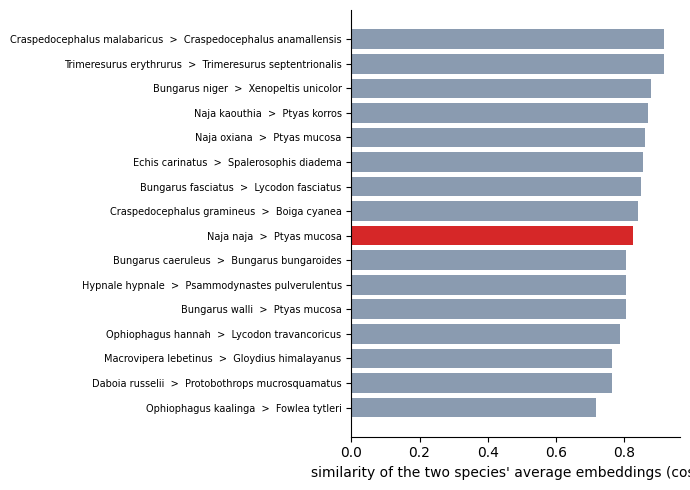

In [212]:
if MAP_OK:
    show = map_cand.sort_values("similarity")
    names = show["dangerous species"] + "  >  " + show["closest harmless species"]
    plt.figure(figsize=(7, 5))
    plt.barh(names, show["similarity"], color=np.where(show["on our list"], "#d62728", "#8a9bb0"))
    plt.xlabel("similarity of the two species' average embeddings (cosine)")
    plt.yticks(fontsize=7)
    savefig("05g_species_map")
    plt.close()

Only one of the 16 dangerous species, the spectacled cobra, has its closest not-listed species on our list. For several of the others the closest one is a relative: another krait for *Bungarus caeruleus*, another pit viper for *Craspedocephalus malabaricus* and *Trimeresurus erythrurus*. Some of those relatives are venomous themselves and are only missing from the WHO list, so "not listed" should not be read as "safe". The nine pairs are a start, not the full list of look-alikes.

In [213]:
check("the species map has a similarity for every pair", (not EMB_OK) or (MAP_OK and bool(np.isfinite(map_sim).all())))

PASS  the species map has a similarity for every pair


### 5.19 Does the training set cover the test photos?
For each val, test and test_extra photo, find the most similar training photo of the same species. A high similarity means the training set holds something that looks like it. A low one means the photo shows something the model has not seen for that species, such as another pose, place or life stage. Val is drawn the same way as train, so it is the control.

The embedding holds at most 8 training photos per species, so all values are lower than they would be with the full training set. Only the comparison between splits means anything.

First the similarity of every photo to every training photo.

In [214]:
COV_OK = False
if EMB_OK:
    cov_species = emb_pick["species"].to_numpy()
    cov_split = emb_pick["split"].to_numpy()
    cov_train = np.where(cov_split == "train")[0]
    cov_sims = emb_Xn @ emb_Xn[cov_train].T
    print("similarity table:", cov_sims.shape)

similarity table: (3013, 1472)


Then, for each photo, keep only the training photos of its own species and take the best one. Photos with no training photo of their species get -1 and are dropped.

In [215]:
if EMB_OK:
    same_species = cov_species[:, None] == cov_species[cov_train][None, :]
    cov_best = np.where(same_species, cov_sims, -1).max(axis=1)
    closest_species = cov_species[cov_train][cov_sims.argmax(axis=1)]
    print(f"{(cov_best == -1).sum()} photos have no training photo of their own species")

0 photos have no training photo of their own species


In [216]:
if EMB_OK:
    cov = pd.DataFrame({"species": cov_species, "split": cov_split, "same_species": cov_best,
                        "closest_is_same": closest_species == cov_species})
    cov = cov[cov["split"].isin(["val", "test", "test_extra"]) & (cov["same_species"] > -1)]
    COV_OK = len(cov) > 0
    print(f"{len(cov):,} photos compared")

1,541 photos compared


The result per split: the typical similarity, the 10th percentile (the badly covered photos), and how often the closest training photo of any species is of the same species.

In [217]:
if COV_OK:
    cov["closest_is_same"] = 100 * cov["closest_is_same"]
    cov_tab = cov.groupby("split").agg(photos=("same_species", "size"), median=("same_species", "median"), closest_is_same=("closest_is_same", "mean"))
    cov_tab["10th percentile"] = cov.groupby("split")["same_species"].quantile(0.1)
    display(cov_tab.reindex(["val", "test", "test_extra"]).dropna().round(3))

,photos,median,closest_is_same,10th percentile
split,,,,
val,700,0.547,16.000,0.352
test,361,0.552,17.452,0.323
test_extra,480,0.570,19.167,0.339


Which species are the least covered? Only species with at least three test photos in the embedding.

In [218]:
if COV_OK:
    cov_cls = cov[cov["split"] == "test"].groupby("species")["same_species"].agg(["median", "size"])
    cov_cls = cov_cls[cov_cls["size"] >= 3].sort_values("median")
    cov_cls["WHO"] = cov_cls.index.map(who_of).map(WHO_LABEL)
    print(f"{len(cov_cls)} species with at least three test photos; the ten least covered:")
    display(cov_cls.head(10).round(3))

60 species with at least three test photos; the ten least covered:


,median,size,WHO
species,,,
Boiga nuchalis,0.270,7,Not listed
Naja naja,0.310,8,WHO category 1
Dendrelaphis tristis,0.326,4,Not listed
Spalerosophis atriceps,0.344,3,Not listed
Ophiophagus kaalinga,0.367,4,WHO category 2
Rhabdophis plumbicolor,0.371,8,Not listed
Boiga forsteni,0.418,4,Not listed
Ahaetulla farnsworthi,0.430,3,Not listed
Fowlea tytleri,0.433,5,Not listed


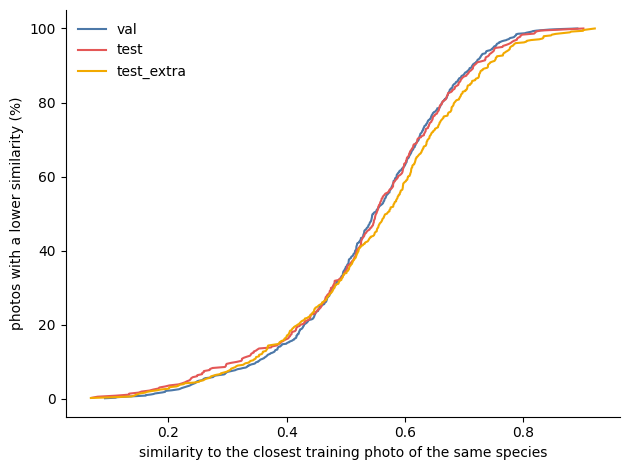

In [219]:
if COV_OK:
    for name, colour in (("val", "#4c78a8"), ("test", "#e45756"), ("test_extra", "#f2a900")):
        v = np.sort(cov.loc[cov["split"] == name, "same_species"])
        plt.plot(v, np.arange(1, len(v) + 1) / len(v) * 100, color=colour, label=name)
    plt.xlabel("similarity to the closest training photo of the same species")
    plt.ylabel("photos with a lower similarity (%)")
    plt.legend(frameon=False)
    savefig("05h_coverage")
    plt.close()

Test and test_extra are covered as well as val, the control: the median similarity is 0.55 to 0.57 for all three, and the 10th percentile 0.32 to 0.35. By this measure the training photos do not leave the test photos uncovered. The least covered species have only three to eight sampled test photos, so one odd photo moves their median, and the list shows where a test score will be noisy more than where the model will fail. Two WHO-listed species are in it: *Naja naja* and *Ophiophagus kaalinga*.

In [220]:
check("coverage similarities stay between -1 and 1", (not EMB_OK) or (COV_OK and bool(cov["same_species"].between(-1.0001, 1.0001).all())))

PASS  coverage similarities stay between -1 and 1


### 5.20 File audit
The last checks are about the files themselves, on the same sample of photos. Does the format match the file name? Does any photo carry an EXIF rotation flag, which would show it sideways unless the loader applies it? Are there colour modes other than RGB, embedded colour profiles or animated files? These small things break a data loader halfway through a training run.

Open each file and read only what the header says about it.

In [221]:
def aud_read(row):
    try:
        with Image.open(img_file(row.path)) as pic:
            return {"photo_id": row.photo_id, "format": pic.format, "mode": pic.mode,
                    "exif_rotation": int(pic.getexif().get(274, 1)),
                    "colour_profile": "icc_profile" in pic.info,
                    "frames": getattr(pic, "n_frames", 1),
                    "name_ends_with": Path(row.path).suffix.lower()}
    except Exception as err:
        return {"photo_id": row.photo_id, "error": str(err)[:60]}

In [222]:
aud_start = time.time()
with ThreadPoolExecutor(max_workers=4) as pool:
    aud_out = list(pool.map(aud_read, quality.itertuples()))
aud = pd.DataFrame([o for o in aud_out if "error" not in o])
aud_failed = len(aud_out) - len(aud)
print(f"{len(aud):,} files read in {time.time() - aud_start:.0f} s, {aud_failed} could not be opened")

6,249 files read in 2 s, 0 could not be opened


Formats and colour modes.

In [223]:
aud[["format", "mode"]].value_counts().rename("photos").reset_index()

,format,mode,photos
0,JPEG,RGB,6235
1,PNG,RGBA,8
2,PNG,RGB,6


Now the things that could cause trouble.

In [224]:
says_jpeg = aud["name_ends_with"].isin([".jpg", ".jpeg"])
print(f"file name says JPEG but the content is another format: {int((says_jpeg & (aud['format'] != 'JPEG')).sum())}")
print(f"photos with an EXIF rotation flag other than 1: {int((aud['exif_rotation'] != 1).sum())}")

file name says JPEG but the content is another format: 14
photos with an EXIF rotation flag other than 1: 0


In [225]:
print(f"photos with an embedded colour profile: {int(aud['colour_profile'].sum())}")
print(f"files with more than one frame: {int((aud['frames'] > 1).sum())}")

photos with an embedded colour profile: 3968
files with more than one frame: 0


All the sampled files open. 6,235 of 6,249 are RGB JPEGs. The other 14 need care: they are PNG files with a `.jpg` name, 8 of them with an alpha channel. The loader should convert every photo to RGB, which drops the alpha channel. No photo has an EXIF rotation flag, so nothing will show up sideways, and no file has more than one frame. About two thirds carry a colour profile. Decoding ignores it, which is fine unless some use a wider colour space than sRGB, and that was not checked.

In [226]:
check("every sampled file can be opened", aud_failed == 0, f"{aud_failed} failed")

PASS  every sampled file can be opened  (0 failed)


## 6. Context: where, when, who and under which licence
The pictures are only part of the story. The table also says where and when each photo was taken, who took it and what licence it has. All of this changes how far the data can be trusted to cover the real world.

### 6.1 Geography
Only photos with coordinates can go on a map. Let's plot the ones inside India, coloured by WHO category, and draw the dangerous categories last so they stay visible.

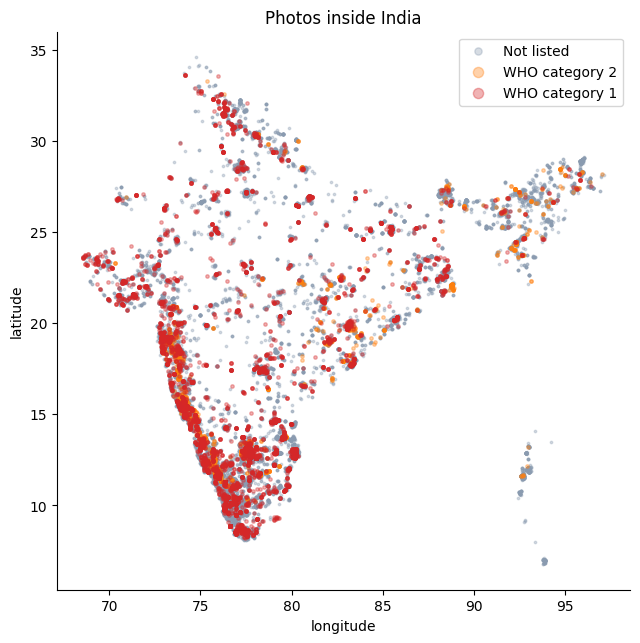

In [227]:
tab_geo = meta.dropna(subset=["latitude", "longitude"])
tab_ind = tab_geo[tab_geo["in_india"]]
fig, ax = plt.subplots(figsize=(6.5, 7))
for cat, size in [("not_listed", 3), ("2", 6), ("1", 6)]:
    d = tab_ind[tab_ind["who_category"] == cat]
    ax.scatter(d["longitude"], d["latitude"], s=size, alpha=0.35, color=WHO_COLORS[cat], label=WHO_LABEL[cat], rasterized=True)
ax.set(xlabel="longitude", ylabel="latitude", title="Photos inside India"); ax.set_aspect("equal")
ax.legend(markerscale=3, loc="upper right")
savefig("06_india_map"); plt.close()

The photos are densest along the Western Ghats, in the north-east and around the big cities, and thin in the centre and the north-west. So the data shows where snakes are photographed, not where they live, and the empty areas are not proof that a species is absent there.

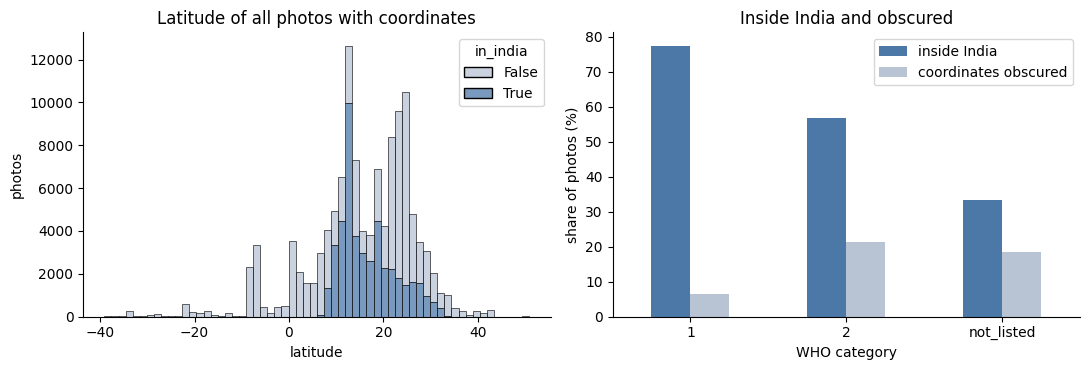

In [228]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(data=tab_geo, x="latitude", hue="in_india", multiple="stack", bins=60, palette={True: "#4c78a8", False: "#b8c4d4"}, ax=ax[0])
ax[0].set(xlabel="latitude", ylabel="photos", title="Latitude of all photos with coordinates")
tab_geo_rate = (100 * meta.groupby("who_category")[["in_india", "obscured"]].mean()).reindex(["1", "2", "not_listed"])
tab_geo_rate.plot.bar(ax=ax[1], rot=0, color=["#4c78a8", "#b8c4d4"])
ax[1].set(xlabel="WHO category", ylabel="share of photos (%)", title="Inside India and obscured"); ax[1].legend(["inside India", "coordinates obscured"])
savefig("06_latitude"); plt.close()

Only part of the photos are inside India, and outside India the latitude range is much wider than inside it. So the data mixes Indian photos with the same species photographed elsewhere. On the right, category 1 has the largest share of photos inside India, and the share of obscured coordinates differs between the categories.

In [229]:
print(f"{meta['in_india'].mean():.1%} of the photos are inside India and {meta['obscured'].mean():.1%} have obscured coordinates")
print("inside India by split (%):", (100 * meta.groupby("split")["in_india"].mean()).round(1).to_dict())
print("latitude outside India, 5th / median / 95th percentile:", tab_geo.loc[~tab_geo["in_india"], "latitude"].quantile([0.05, 0.5, 0.95]).round(1).tolist())
print("latitude inside India, 5th / median / 95th percentile:", tab_ind["latitude"].quantile([0.05, 0.5, 0.95]).round(1).tolist())

37.8% of the photos are inside India and 17.7% have obscured coordinates
inside India by split (%): {'test': 100.0, 'test_extra': 14.7, 'train': 37.4, 'unknown_pool': 82.2, 'val': 37.1}
latitude outside India, 5th / median / 95th percentile: [-8.0, 19.0, 30.4]
latitude inside India, 5th / median / 95th percentile: [9.8, 15.0, 28.0]


### 6.2 Time
Two dates are stored: the day the snake was seen (`observed_on`, date only) and the time the photo was uploaded (`created_at`). Let's compare them.

In [230]:
tab_up = meta["created_at"].dt.tz_convert(None).dt.normalize()
tab_lag = (tab_up - meta["observed_on"]).dt.days
print(f"observed {meta['year'].min()} to {meta['year'].max()}, uploaded {meta['created_at'].dt.year.min()} to {meta['created_at'].dt.year.max()}")
print(f"median gap between seeing and uploading: {tab_lag.median():.0f} days; {(tab_lag <= 1).mean():.1%} within a day, {(tab_lag > 365).mean():.1%} after more than a year")
print(f"negative gaps (the upload time is in UTC, the observed date is local): {(tab_lag < 0).sum():,}")

observed 1968 to 2026, uploaded 2010 to 2026
median gap between seeing and uploading: 2 days; 47.0% within a day, 14.4% after more than a year
negative gaps (the upload time is in UTC, the observed date is local): 1,327


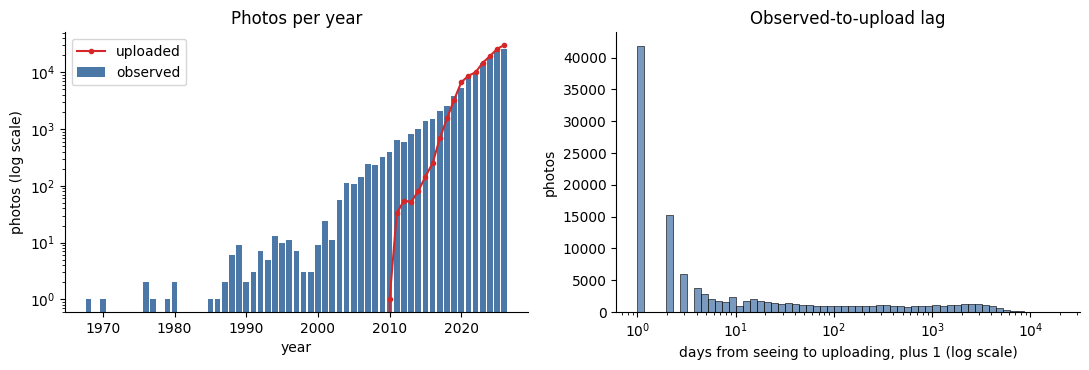

In [231]:
tab_yr = pd.DataFrame({"observed": meta["year"].value_counts(), "uploaded": meta["created_at"].dt.year.value_counts()}).fillna(0).sort_index()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(tab_yr.index, tab_yr["observed"], color="#4c78a8", label="observed")
ax[0].plot(tab_yr.index, tab_yr["uploaded"], color="#d62728", marker="o", ms=3, label="uploaded"); ax[0].legend()
ax[0].set(yscale="log", xlabel="year", ylabel="photos (log scale)", title="Photos per year")
sns.histplot(tab_lag.clip(lower=0) + 1, log_scale=True, bins=60, color="#4c78a8", ax=ax[1])
ax[1].set(xlabel="days from seeing to uploading, plus 1 (log scale)", ylabel="photos", title="Observed-to-upload lag")
savefig("06_time"); plt.close()

Uploads grow strongly over the years, and the observation years reach further back because some photos were taken long before they were uploaded. Most photos are uploaded within days, with a long tail of old pictures that were digitised later.

Next, the seasons. For each WHO category we take the share of its photos taken in each month, so the lines are comparable even though the categories have very different sizes.

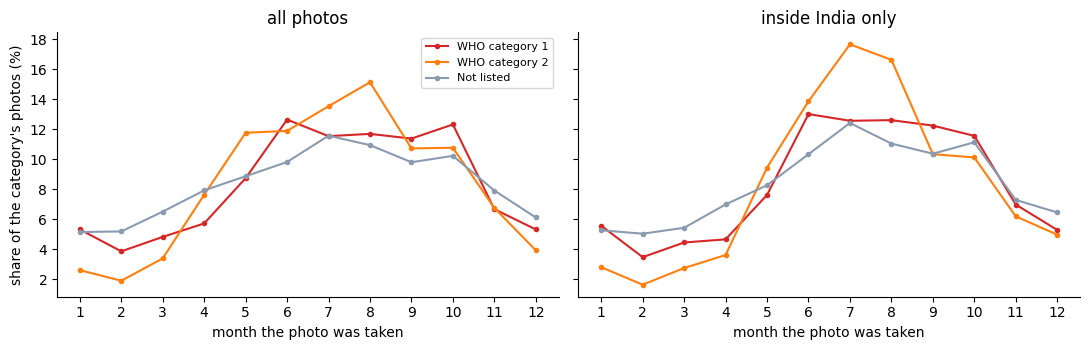

In [232]:
tab_in_ind = meta[meta["in_india"]]
tab_mo = [pd.crosstab(d["month"], d["who_category"], normalize="columns") * 100 for d in (meta, tab_in_ind)]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, tb, title in zip(ax, tab_mo, ["all photos", "inside India only"]):
    for cat in ["1", "2", "not_listed"]:
        a.plot(tb.index, tb[cat], marker="o", ms=3, color=WHO_COLORS[cat], label=WHO_LABEL[cat])
    a.set(xticks=range(1, 13), xlabel="month the photo was taken", title=title)
ax[0].set_ylabel("share of the category's photos (%)"); ax[0].legend(fontsize=8)
savefig("06_seasons"); plt.close()

All three categories peak in the middle of the year, which is the monsoon in India, and are lowest in the winter months. Category 2 has the sharpest peak. The curves for all photos are flatter than for India alone, since photos from other parts of the world have other seasons.

### 6.3 Photographers
`observer_id` is the account that took the photo. We only look at counts per photographer here, never at who they are. A few very active people can dominate the data, so let's measure how concentrated it is.

In [233]:
tab_obs = meta.groupby("observer_id").size().sort_values()
tab_top1 = tab_obs.tail(int(0.01 * len(tab_obs))).sum() / tab_obs.sum()
print(f"{len(tab_obs):,} photographers, median {tab_obs.median():.0f} photos each, {(tab_obs == 1).mean():.1%} of them with a single photo")
print(f"Gini of photos per photographer: {tab_gini(tab_obs):.2f}; the top 1% took {tab_top1:.1%} of the photos; the busiest took {tab_obs.max():,} photos")
check("15,842 photographers", len(tab_obs) == 15842, f"{len(tab_obs):,}")
check("the top 1% of photographers took 28.1% of the photos", round(100 * tab_top1, 1) == 28.1, f"{tab_top1:.1%}")
check("the busiest photographer took 2,189 photos", tab_obs.max() == 2189, f"{tab_obs.max():,}")

15,842 photographers, median 2 photos each, 38.1% of them with a single photo
Gini of photos per photographer: 0.73; the top 1% took 28.1% of the photos; the busiest took 2,189 photos
PASS  15,842 photographers  (15,842)
PASS  the top 1% of photographers took 28.1% of the photos  (28.1%)
PASS  the busiest photographer took 2,189 photos  (2,189)


PASS  Gini from the Lorenz curve matches the direct formula  (0.725)


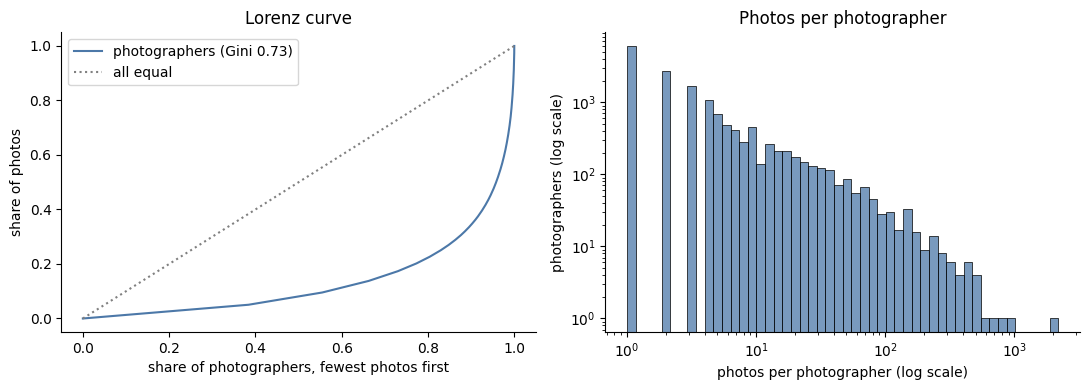

In [234]:
tab_lz = np.insert(tab_obs.cumsum().values / tab_obs.sum(), 0, 0)
tab_xs = np.linspace(0, 1, len(tab_lz))
tab_g2 = 1 - 2 * np.trapezoid(tab_lz, tab_xs)
check("Gini from the Lorenz curve matches the direct formula", abs(tab_g2 - tab_gini(tab_obs)) < 0.01, f"{tab_g2:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(tab_xs, tab_lz, color="#4c78a8", label=f"photographers (Gini {tab_g2:.2f})"); ax[0].plot([0, 1], [0, 1], ls=":", color="grey", label="all equal"); ax[0].legend()
ax[0].set(xlabel="share of photographers, fewest photos first", ylabel="share of photos", title="Lorenz curve")
sns.histplot(tab_obs, log_scale=True, bins=50, color="#4c78a8", ax=ax[1])
ax[1].set(yscale="log", xlabel="photos per photographer (log scale)", ylabel="photographers (log scale)", title="Photos per photographer")
savefig("06_photographers"); plt.close()

The curve bends far below the diagonal: most photographers contribute a handful of photos while a small group contributes a large part. A model can pick up the habits of one photographer (the same garden, the same camera) instead of the snake, which is why train, val and test are split by observer.

How concentrated is it inside each class? For every class we take its training photos and add up the share taken by its three most active photographers.

In [235]:
tab_tr = meta[meta["split"] == "train"]
tab_per = tab_tr.groupby(["species", "observer_id"]).size().sort_values(ascending=False)
tab_top3 = tab_per.groupby("species").head(3).groupby("species").sum()
tab_phc = pd.DataFrame({"photos": tab_tr.groupby("species").size(), "photographers": tab_per.groupby("species").size(), "top3_share_pct": 100 * tab_top3 / tab_tr.groupby("species").size()})
tab_phc = tab_phc.join(classes.set_index("species")["who_category"]).dropna(subset=["who_category"])
print(f"median share of a class's training photos taken by its top 3 photographers: {tab_phc['top3_share_pct'].median():.1f}%")
tab_phc.sort_values("top3_share_pct", ascending=False).head(8).round(1)

median share of a class's training photos taken by its top 3 photographers: 29.2%


,photos,photographers,top3_share_pct,who_category
species,,,,
Wallaceophis gujaratensis,24,2,100.0,not_listed
Ferania sieboldii,25,3,100.0,not_listed
Ahaetulla perroteti,25,4,96.0,not_listed
Platyceps josephi,18,4,94.4,not_listed
Ahaetulla laudankia,25,5,92.0,not_listed
Psammophis leithii,24,5,87.5,not_listed
Bungarus andamanensis,22,6,86.4,not_listed
Psammophis longifrons,20,6,85.0,not_listed


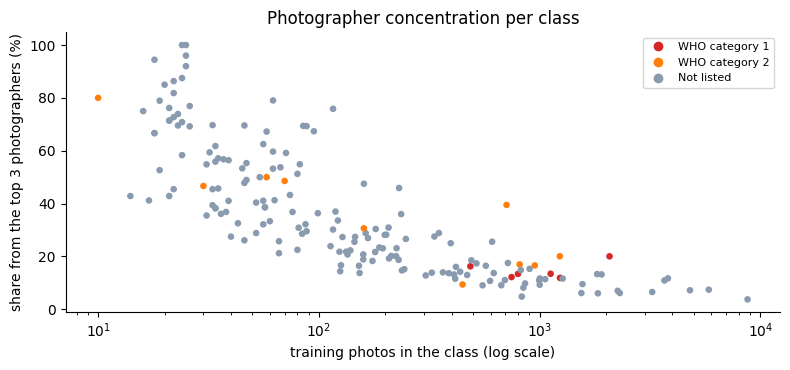

In [236]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(tab_phc["photos"], tab_phc["top3_share_pct"], c=[WHO_COLORS[w] for w in tab_phc["who_category"]], s=14)
ax.set(xscale="log", xlabel="training photos in the class (log scale)", ylabel="share from the top 3 photographers (%)", title="Photographer concentration per class")
tab_who_legend(ax, loc="upper right", fontsize=8)
savefig("06_top3_share"); plt.close()

Small classes lean on a few photographers, and the top-3 share falls as classes get bigger. For the smallest classes a handful of people took a large part of the training photos, so those classes carry the most risk of learning a photographer instead of a snake.

### 6.4 Licences
The licence decides which photos we can show in this notebook. The rule used throughout: CC0 and CC BY photos are shown first, CC BY-NC only as a labelled fallback, and share-alike photos are used for statistics only. All-rights-reserved and no-derivatives photos are not in this dataset.

In [237]:
tab_rule_map = {"cc0": "show first", "cc-by": "show first", "cc-by-nc": "show with label"}
tab_show = meta["license"].map(tab_rule_map).fillna("statistics only")
tab_lic = meta["license"].value_counts().to_frame("photos")
tab_lic["share %"] = (100 * tab_lic["photos"] / len(meta)).round(1)
tab_lic["use in the notebook"] = pd.Series(tab_rule_map).reindex(tab_lic.index).fillna("statistics only")
print("share of photos by use (%):", (100 * tab_show.value_counts(normalize=True)).round(1).to_dict())
tab_lic

share of photos by use (%): {'show with label': 83.3, 'show first': 13.5, 'statistics only': 3.1}


,photos,share %,use in the notebook
license,,,
cc-by-nc,101321,83.3,show with label
cc-by,14961,12.3,show first
cc-by-nc-sa,2628,2.2,statistics only
cc0,1471,1.2,show first
cc-by-sa,1185,1.0,statistics only


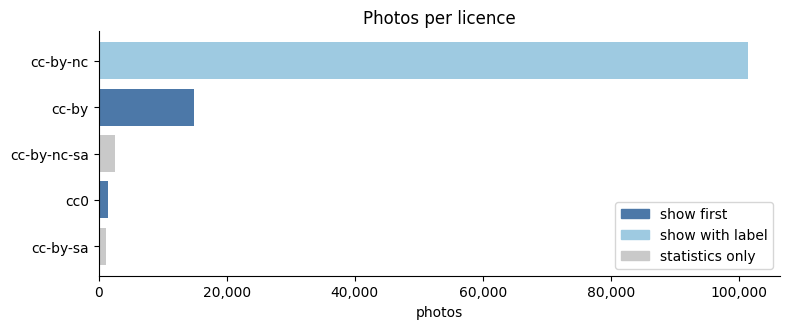

In [238]:
tab_col = {"show first": "#4c78a8", "show with label": "#9ecae1", "statistics only": "#c9c9c9"}
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(tab_lic.index, tab_lic["photos"], color=[tab_col[u] for u in tab_lic["use in the notebook"]])
ax.set(xlabel="photos", title="Photos per licence"); ax.xaxis.set_major_formatter(FMT); ax.invert_yaxis()
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in tab_col.values()], labels=list(tab_col), loc="lower right")
savefig("06_licences"); plt.close()

One licence dominates, and the licences that allow showing a photo without extra conditions are a small part of the data. Let's see how this differs by split and by WHO category. A mix that is close across splits and categories means the licence rule does not bias what we show.

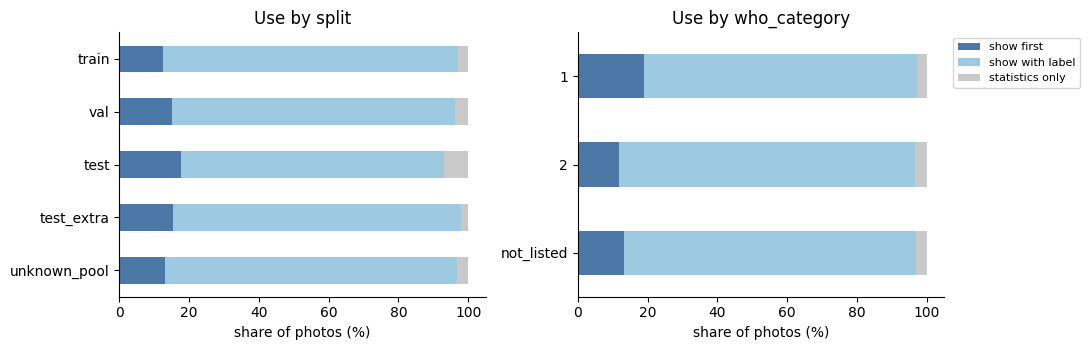

In [239]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for a, key, order in zip(ax, ["split", "who_category"], [SPLIT_ORDER, ["1", "2", "not_listed"]]):
    tb = (100 * pd.crosstab(meta[key], tab_show, normalize="index")).reindex(order)[list(tab_col)]
    tb.plot.barh(stacked=True, color=list(tab_col.values()), ax=a, legend=False); a.invert_yaxis()
    a.set(xlabel="share of photos (%)", ylabel="", title=f"Use by {key}")
ax[1].legend(list(tab_col), bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
savefig("06_licence_groups"); plt.close()

How many classes can actually be shown? If a class has no CC0 or CC BY photo at all, its pictures can only come from the labelled fallback.

In [240]:
tab_sp_show = pd.crosstab(meta["species"], tab_show).reindex(index=classes["species"], columns=list(tab_col), fill_value=0)
tab_few = pd.Series({f"under {n} CC0 or CC BY photos": int((tab_sp_show["show first"] < n).sum()) for n in (1, 5, 10, 20)})
print(f"{len(classes)} classes in total")
print(tab_few.to_string())
print("classes with no photo at all that can be shown, first or labelled:", int(((tab_sp_show["show first"] + tab_sp_show["show with label"]) == 0).sum()))
tab_lw = tab_sp_show.join(classes.set_index("species")["who_category"]).query("who_category != 'not_listed'")
tab_lw.sort_values("show first").head(6)

184 classes in total
under 1 CC0 or CC BY photos     13
under 5 CC0 or CC BY photos     36
under 10 CC0 or CC BY photos    55
under 20 CC0 or CC BY photos    80
classes with no photo at all that can be shown, first or labelled: 0


,show first,show with label,statistics only,who_category
species,,,,
Bungarus walli,0,25,0,2
Naja oxiana,0,44,0,2
Bungarus niger,18,66,1,2
Ophiophagus kaalinga,44,60,3,2
Naja kaouthia,45,697,8,1
Trimeresurus erythrurus,60,163,10,2


## 7. Safety lookalikes
Some not-listed snakes are easy to mistake for dangerous ones, and the mistake that matters most is calling a dangerous snake harmless. The pairs come from the list defined at the start, and the WHO category of each species is read from `classes.csv`. Let's count the photos each side of every pair has in every split.

In [241]:
tab_cnt = pd.crosstab(meta["species"], meta["split"]).reindex(columns=SPLIT_ORDER[:4], fill_value=0)

def tab_pair_rows(pairs, roles):
    rows = []
    for first, second, desc in pairs:
        for role, sp in zip(roles, (first, second)):
            rows.append({"pair": desc, "role": role, "species": sp, "WHO": who_of[sp], **tab_cnt.loc[sp].to_dict(), "total": int(tab_cnt.loc[sp].sum())})
    return pd.DataFrame(rows)

tab_pairs = tab_pair_rows(LOOKALIKES, ("dangerous side", "look-alike side"))
tab_pairs.set_index(["pair", "role"])

species  \
pair                                      role                                          
spectacled cobra and oriental rat snake   dangerous side                    Naja naja   
                                          look-alike side                Ptyas mucosa   
common krait and Indian wolf snake        dangerous side           Bungarus caeruleus   
                                          look-alike side             Lycodon aulicus   
common krait and Travancore wolf snake    dangerous side           Bungarus caeruleus   
                                          look-alike side       Lycodon travancoricus   
common krait and Russell's wolf snake     dangerous side           Bungarus caeruleus   
                                          look-alike side         Lycodon fasciolatus   
Russell's viper and rough-scaled sand boa dangerous side              Daboia russelii   
                                          look-alike side                Eryx conicus   
Russell's viper and Indian rock python    dangerous side              Daboia russelii   
                                          look-alike side              Python molurus   
saw-scaled viper and common cat snake     dangerous side              Echis carinatus   
                                          look-alike side             Boiga trigonata   
spectacled cobra and checkered keelback   dangerous side                    Naja naja   
                                          look-alike side             Fowlea piscator   
bamboo pit viper and green keelback       dangerous side   Craspedocephalus gramineus   
                                          look-alike side      Rhabdophis plumbicolor   

                                                                  WHO  train  \
pair                                      role                                 
spectacled cobra and oriental rat snake   dangerous side            1   2076   
                                          look-alike side  not_listed   4805   
common krait and Indian wolf snake        dangerous side            1    799   
                                          look-alike side  not_listed   1003   
common krait and Travancore wolf snake    dangerous side            1    799   
                                          look-alike side  not_listed    470   
common krait and Russell's wolf snake     dangerous side            1    799   
                                          look-alike side  not_listed    410   
Russell's viper and rough-scaled sand boa dangerous side            1   1123   
                                          look-alike side  not_listed    552   
Russell's viper and Indian rock python    dangerous side            1   1123   
                                          look-alike side  not_listed    860   
saw-scaled viper and common cat snake     dangerous side            1   1238   
                                          look-alike side  not_listed    365   
spectacled cobra and checkered keelback   dangerous side            1   2076   
                                          look-alike side  not_listed   3681   
bamboo pit viper and green keelback       dangerous side            2    813   
                                          look-alike side  not_listed    305   

                                                           val  test  \
pair                                      role                         
spectacled cobra and oriental rat snake   dangerous side   338   324   
                                          look-alike side  956   445   
common krait and Indian wolf snake        dangerous side   177   107   
                                          look-alike side  245   148   
common krait and Travancore wolf snake    dangerous side   177   107   
                                          look-alike side  104    65   
common krait and Russell's wolf snake     dangerous side   177   107   
                                          look-a

Some species appear in more than one pair, for example the same dangerous snake with several harmless ones, so the table repeats their counts. A pair can only be tested if both sides have test photos, so let's read the test counts on their own.

In [242]:
tab_wide = pd.DataFrame([{"dangerous": d, "harmless": s, "dangerous_who": who_of[d], "harmless_who": who_of[s],
                          **{f"dangerous_{c}": int(tab_cnt.loc[d, c]) for c in tab_cnt.columns}, **{f"harmless_{c}": int(tab_cnt.loc[s, c]) for c in tab_cnt.columns}} for d, s, _ in LOOKALIKES])
tab_wide.to_csv(WORK / "lookalike_pairs.csv", index=False)
print(f"wrote {WORK / 'lookalike_pairs.csv'} with {len(tab_wide)} pairs and {tab_wide.shape[1]} columns")
tab_wide[["dangerous", "harmless", "dangerous_test", "harmless_test"]]

wrote /kaggle/working/lookalike_pairs.csv with 9 pairs and 12 columns


,dangerous,harmless,dangerous_test,harmless_test
0,Naja naja,Ptyas mucosa,324,445
1,Bungarus caeruleus,Lycodon aulicus,107,148
2,Bungarus caeruleus,Lycodon travancoricus,107,65
3,Bungarus caeruleus,Lycodon fasciolatus,107,58
4,Daboia russelii,Eryx conicus,170,76
5,Daboia russelii,Python molurus,170,99
6,Echis carinatus,Boiga trigonata,64,62
7,Naja naja,Fowlea piscator,324,507
8,Craspedocephalus gramineus,Rhabdophis plumbicolor,298,94


In [243]:
check("all 9 look-alike pairs are in classes.csv", len(LOOKALIKES) == 9, f"{len(LOOKALIKES)} found")
check("the dangerous side of every pair is in WHO category 1 or 2", all(who_of[d] in ("1", "2") for d, _, _ in LOOKALIKES))
check("the look-alike side of every pair is not listed", all(who_of[s] == "not_listed" for _, s, _ in LOOKALIKES))
tab_notest = tab_pairs[tab_pairs["test"] == 0]
tab_both = [d for d, s, _ in LOOKALIKES if tab_cnt.loc[d, "test"] > 0 and tab_cnt.loc[s, "test"] > 0]
print(f"{len(tab_both)} of {len(LOOKALIKES)} pairs have test photos on both sides; the fewest test photos on one species is {int(tab_pairs['test'].min())}")
print("species with no test photos:", ", ".join(tab_notest["species"].unique()) or "none")
print("species with fewer than 10 test photos:", ", ".join(tab_pairs.loc[tab_pairs["test"] < 10, "species"].unique()) or "none")

PASS  all 9 look-alike pairs are in classes.csv  (9 found)
PASS  the dangerous side of every pair is in WHO category 1 or 2
PASS  the look-alike side of every pair is not listed
9 of 9 pairs have test photos on both sides; the fewest test photos on one species is 58
species with no test photos: none
species with fewer than 10 test photos: none


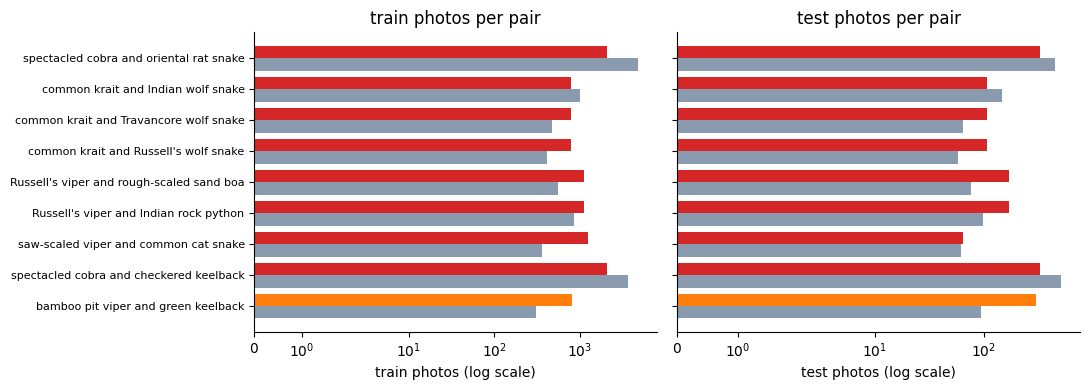

In [244]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
tab_pos = np.arange(len(LOOKALIKES))
for a, col in zip(ax, ["train", "test"]):
    for role, off in [("dangerous side", -0.2), ("look-alike side", 0.2)]:
        d = tab_pairs[tab_pairs["role"] == role]
        a.barh(tab_pos + off, d[col].values, height=0.4, color=[WHO_COLORS[w] for w in d["WHO"]])
    a.set(xscale="symlog", xlabel=f"{col} photos (log scale)", title=f"{col} photos per pair")
ax[0].set_yticks(tab_pos, [desc for _, _, desc in LOOKALIKES], fontsize=8); ax[0].invert_yaxis()
savefig("07_lookalike_counts"); plt.close()

In each pair the upper bar is the dangerous snake (red or orange) and the lower bar the look-alike (grey), on a log scale. A species with no photos in a split has no bar. The two sides are rarely balanced, in train or in test, and the smaller side of a pair sets how well that pair can be scored: with few test photos on one side, a test score for the pair is noisy.

### 7.1 Do the two sides of a pair look equally sharp and bright?
If the dangerous snake is photographed in a different way from its look-alike (blurrier, darker), a model might learn the photo style instead of the pattern on the skin. Here we use the quality table from section 5, which covers a sample of photos per class.

In [245]:
tab_qp = []
for dang, safe, desc in (LOOKALIKES if "quality" in globals() else []):
    a, b = quality[quality["species"] == dang], quality[quality["species"] == safe]
    if min(len(a), len(b)) >= 5:
        p = stats.mannwhitneyu(a["sharpness"], b["sharpness"]).pvalue
        tab_qp.append({"pair": desc, "n_dangerous": len(a), "n_lookalike": len(b), "sharp_dangerous": a["sharpness"].median(), "sharp_lookalike": b["sharpness"].median(),
                       "bright_dangerous": a["brightness"].median(), "bright_lookalike": b["brightness"].median(), "p_sharpness": p})
tab_qp = pd.DataFrame(tab_qp)
print(f"{len(tab_qp)} of {len(LOOKALIKES)} pairs have at least 5 sampled photos on both sides")
tab_qp.round(3).set_index("pair") if len(tab_qp) else None

9 of 9 pairs have at least 5 sampled photos on both sides


,n_dangerous,n_lookalike,sharp_dangerous,sharp_lookalike,bright_dangerous,bright_lookalike,p_sharpness
pair,,,,,,,
spectacled cobra and oriental rat snake,30,30,1353.155,2097.224,120.728,125.659,0.191
common krait and Indian wolf snake,30,30,2002.346,1194.619,116.389,118.940,0.059
common krait and Travancore wolf snake,30,30,2002.346,2216.255,116.389,114.805,0.695
common krait and Russell's wolf snake,30,30,2002.346,1369.761,116.389,121.408,0.035
Russell's viper and rough-scaled sand boa,30,30,3036.738,2127.943,119.002,130.528,0.112
Russell's viper and Indian rock python,30,30,3036.738,1780.557,119.002,105.792,0.068
saw-scaled viper and common cat snake,30,30,3012.141,1747.055,107.853,122.841,0.030
spectacled cobra and checkered keelback,30,30,1353.155,1466.998,120.728,128.039,0.784
bamboo pit viper and green keelback,30,30,1565.856,1948.887,64.872,121.948,0.284


In [246]:
for r in tab_qp.itertuples():
    word = "sharper" if r.sharp_dangerous > r.sharp_lookalike else "blurrier"
    print(f"{r.pair}: the dangerous snake's photos are {word} (median {r.sharp_dangerous:.0f} against {r.sharp_lookalike:.0f}, p = {r.p_sharpness:.3f}) and {'brighter' if r.bright_dangerous > r.bright_lookalike else 'darker'} ({r.bright_dangerous:.0f} against {r.bright_lookalike:.0f})")
if tab_qp.empty:
    print("no pair has enough sampled photos in this run")

spectacled cobra and oriental rat snake: the dangerous snake's photos are blurrier (median 1353 against 2097, p = 0.191) and darker (121 against 126)
common krait and Indian wolf snake: the dangerous snake's photos are sharper (median 2002 against 1195, p = 0.059) and darker (116 against 119)
common krait and Travancore wolf snake: the dangerous snake's photos are blurrier (median 2002 against 2216, p = 0.695) and brighter (116 against 115)
common krait and Russell's wolf snake: the dangerous snake's photos are sharper (median 2002 against 1370, p = 0.035) and darker (116 against 121)
Russell's viper and rough-scaled sand boa: the dangerous snake's photos are sharper (median 3037 against 2128, p = 0.112) and darker (119 against 131)
Russell's viper and Indian rock python: the dangerous snake's photos are sharper (median 3037 against 1781, p = 0.068) and brighter (119 against 106)
saw-scaled viper and common cat snake: the dangerous snake's photos are sharper (median 3012 against 1747, 

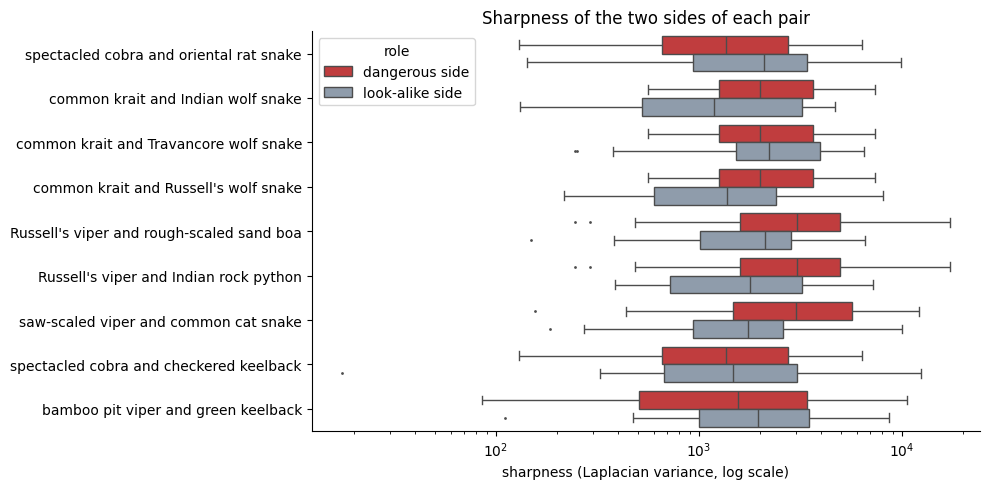

In [247]:
if len(tab_qp):
    tab_ql = quality[quality["species"].isin(tab_pairs["species"])].merge(tab_pairs[["species", "pair", "role"]], on="species")
    tab_ql = tab_ql[tab_ql["pair"].isin(tab_qp["pair"])]
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.boxplot(data=tab_ql, y="pair", x="sharpness", hue="role", hue_order=["dangerous side", "look-alike side"], order=list(tab_qp["pair"]), log_scale=True, fliersize=1, palette=["#d62728", "#8a9bb0"], ax=ax)
    ax.set(xlabel="sharpness (Laplacian variance, log scale)", ylabel="", title="Sharpness of the two sides of each pair")
    savefig("07_lookalike_sharpness"); plt.close()

The boxes show whether the two sides of a pair sit at a similar sharpness. If a dangerous snake is clearly blurrier or sharper than its look-alike, a model could separate them by image quality alone, so the printed comparison above is worth a look before drawing conclusions from the confusion matrix.

### 7.2 Pairs where both snakes are dangerous
Two pairs are different: both snakes are dangerous, so a mix-up inside the pair is not harmless-versus-dangerous but still a wrong answer. They get their own short table.

In [248]:
tab_dd = tab_pair_rows(DANGEROUS, ("first snake", "second snake"))
check("both snakes of the dangerous pairs are in WHO category 1 or 2", all(who_of[a] in ("1", "2") and who_of[b] in ("1", "2") for a, b, _ in DANGEROUS))
print(f"{len(DANGEROUS)} pairs with two dangerous snakes")
tab_dd.set_index(["pair", "role"]) if len(tab_dd) else None

PASS  both snakes of the dangerous pairs are in WHO category 1 or 2
2 pairs with two dangerous snakes


species  \
pair                                      role                                         
hump-nosed and Malabar pit viper          first snake                Hypnale hypnale   
                                          second snake  Craspedocephalus malabaricus   
hump-nosed pit viper and saw-scaled viper first snake                Hypnale hypnale   
                                          second snake               Echis carinatus   

                                                       WHO  train  val  test  \
pair                                      role                                 
hump-nosed and Malabar pit viper          first snake    1    747  155   124   
                                          second snake   2   1236  279   217   
hump-nosed pit viper and saw-scaled viper first snake    1    747  155   124   
                                          second snake   1   1238  273    64   

                                                        test_extra  total  
pair                                      role                             
hump-nosed and Malabar pit viper          first snake           47   1073  
                                          second snake          57   1789  
hump-nosed pit viper and saw-scaled viper first snake           47   1073  
                                          second snake         196   1771

### 7a. Cleaning funnel
The cleaning notebook started from all downloaded photos, dropped some for clear reasons (`excluded.csv`), split the rest, and then removed near-duplicates from val and test. Let's rebuild that funnel from the files.

In [249]:
tab_raw = len(splits_all) + len(excluded)
tab_red = excluded["drop_reason"].value_counts()
print(f"raw rows: {len(splits_all):,} in splits.csv + {len(excluded):,} in excluded.csv = {tab_raw:,}")
if tab_split_rep:
    check("raw rows equal raw_photos in split_report.json", tab_raw == tab_split_rep.get("raw_photos"), f"{tab_split_rep.get('raw_photos')}")
check("excluded.csv has 994 rows", len(excluded) == 994, f"{len(excluded)}")
for reason, n in {"exact_duplicate": 928, "duplicate_conflicting_species": 30, "too_small": 36}.items():
    check(f"excluded for {reason}: {n}", tab_red.get(reason, 0) == n, f"{tab_red.get(reason, 0)} found")

raw rows: 181,503 in splits.csv + 994 in excluded.csv = 182,497
PASS  raw rows equal raw_photos in split_report.json  (182497)
PASS  excluded.csv has 994 rows  (994)
PASS  excluded for exact_duplicate: 928  (928 found)
PASS  excluded for duplicate_conflicting_species: 30  (30 found)
PASS  excluded for too_small: 36  (36 found)


In [250]:
tab_why = excluded.assign(short_side=excluded[["width", "height"]].min(axis=1)).groupby("drop_reason").agg(rows=("photo_id", "size"), shortest_side=("short_side", "min"), median_KB=("bytes", lambda s: s.median() / 1024), cc_licensed=("license", lambda s: s.str.startswith("cc").mean()))
tab_rl, tab_ts = tab_split_rep.get("rules", {}), excluded[excluded["drop_reason"] == "too_small"]
print("size rules in split_report.json:", {k: tab_rl.get(k) for k in ("min_bytes", "min_side_px")})
print(f"of {len(tab_ts)} too_small rows, {(tab_ts['bytes'] < tab_rl.get('min_bytes', 0)).sum()} are under the byte limit and {(tab_ts[['width', 'height']].min(axis=1) < tab_rl.get('min_side_px', 0)).sum()} under the side limit")
tab_why.round(2)

size rules in split_report.json: {'min_bytes': 5000, 'min_side_px': 100}
of 36 too_small rows, 19 are under the byte limit and 17 under the side limit


,rows,shortest_side,median_KB,cc_licensed
drop_reason,,,,
duplicate_conflicting_species,30,225,111.44,0.87
exact_duplicate,928,163,128.32,0.72
too_small,36,59,4.84,0.86


From the names: an exact duplicate repeats another photo, a conflicting duplicate shows the same photo under two different species, and a too-small photo breaks the minimum file size or image side. The printout above shows how many break each limit. Next, the rows that are in `splits.csv` but no longer in the final metadata: photos with restricted licences, and near copies.

In [251]:
tab_nd = splits_all[allowed_rows & ~splits_all["photo_id"].isin(meta["photo_id"])]
tab_nd_n = tab_nd["split"].value_counts()
check("59,752 photos with restricted licences are in splits.csv but not in metadata.csv", (~allowed_rows).sum() == 59752 and not splits_all.loc[~allowed_rows, "photo_id"].isin(meta["photo_id"]).any(), f"{(~allowed_rows).sum():,}")
check("185 near copies are in splits.csv but not in metadata.csv", len(tab_nd) == 185, f"{len(tab_nd)}")
check("they are 105 in val, 55 in test_extra and 25 in test", tab_nd_n.to_dict() == {"val": 105, "test_extra": 55, "test": 25}, str(tab_nd_n.to_dict()))
tab_mm = splits_all.merge(meta[["photo_id", "split"]], on="photo_id", suffixes=("", "_meta"))
tab_moved = tab_mm[tab_mm["split"] != tab_mm["split_meta"]]
check("the only photos that change split are the 367 of small species moved to the unknown pool", len(tab_moved) == 367 and (tab_moved["split_meta"] == "unknown_pool").all(), f"{len(tab_moved)} moved")
tab_ba = pd.DataFrame({"before": splits_all["split"].value_counts(), "after": meta["split"].value_counts()}).reindex(SPLIT_ORDER)
tab_ba["removed"] = tab_ba["before"] - tab_ba["after"]
tab_ba["removed %"] = (100 * tab_ba["removed"] / tab_ba["before"]).round(2)
tab_ba

PASS  59,752 photos with restricted licences are in splits.csv but not in metadata.csv  (59,752)
PASS  185 near copies are in splits.csv but not in metadata.csv  (185)
PASS  they are 105 in val, 55 in test_extra and 25 in test  ({'val': 105, 'test_extra': 55, 'test': 25})
PASS  the only photos that change split are the 367 of small species moved to the unknown pool  (367 moved)


,before,after,removed,removed %
split,,,,
train,129241,85067,44174,34.18
val,25803,17151,8652,33.53
test,7338,5144,2194,29.90
test_extra,18465,13389,5076,27.49
unknown_pool,656,815,-159,-24.24


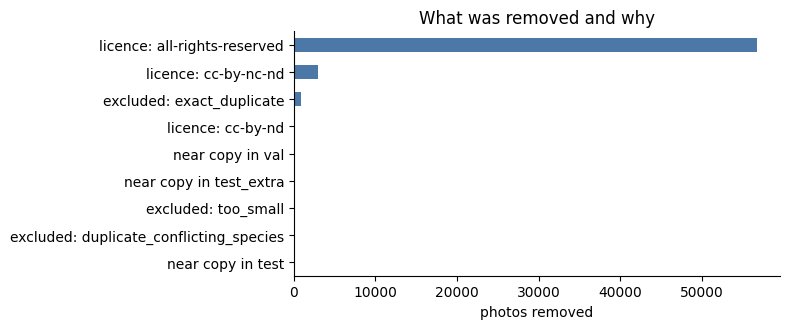

,step,photos,removed in this step
0,raw photos,182497,0
1,after excluded.csv,181503,994
2,after the licence filter,121751,59752
3,after near copies,121566,185


In [252]:
tab_steps = pd.DataFrame({"step": ["raw photos", "after excluded.csv", "after the licence filter", "after near copies"], "photos": [tab_raw, len(splits_all), int(allowed_rows.sum()), len(meta)]})
tab_steps["removed in this step"] = (-tab_steps["photos"].diff()).fillna(0).astype(int)
tab_why_n = pd.concat([tab_red.rename(lambda r: f"excluded: {r}"), splits_all.loc[~allowed_rows, "license"].value_counts().rename(lambda l: f"licence: {l}"), tab_nd_n.rename(lambda s: f"near copy in {s}")])
ax = tab_why_n.sort_values().plot.barh(color="#4c78a8", figsize=(8, 3.4))
ax.set(xlabel="photos removed", title="What was removed and why")
savefig("07a_funnel"); plt.close()
tab_steps

Restricted licences are by far the biggest group of removed photos. Near copies were removed only from val and test, so the splits stay clean without touching the training data. Which species lose the most?

In [253]:
tab_loss = pd.DataFrame({"excluded": excluded.groupby("species").size(), "near_duplicate": tab_nd.groupby("species").size()}).fillna(0).astype(int)
tab_loss["lost"] = tab_loss["excluded"] + tab_loss["near_duplicate"]
tab_loss["kept"] = meta.groupby("species").size().reindex(tab_loss.index).fillna(0).astype(int)
tab_loss["share lost %"] = (100 * tab_loss["lost"] / (tab_loss["lost"] + tab_loss["kept"])).round(1)
check("Indotyphlops braminus has the most photos in excluded.csv (105)", tab_loss["excluded"].idxmax() == "Indotyphlops braminus" and tab_loss["excluded"].max() == 105, f"{tab_loss['excluded'].idxmax()} {tab_loss['excluded'].max()}")
tab_big = tab_loss[tab_loss["lost"] + tab_loss["kept"] >= 50]
print(f"largest share lost: {tab_loss['share lost %'].max()}% ({tab_loss['share lost %'].idxmax()}); among species with 50+ raw photos: {tab_big['share lost %'].max()}%")
tab_loss.sort_values("lost", ascending=False).head(10)

PASS  Indotyphlops braminus has the most photos in excluded.csv (105)  (Indotyphlops braminus 105)
largest share lost: 24.1% (Platyceps josephi); among species with 50+ raw photos: 5.3%


,excluded,near_duplicate,lost,kept,share lost %
species,,,,,
Indotyphlops braminus,105,7,112,12038,0.9
Fowlea piscator,66,5,71,5116,1.4
Ptyas mucosa,52,6,58,6859,0.8
Python bivittatus,22,26,48,2338,2.0
Ahaetulla prasina,33,14,47,8220,0.6
Psammodynastes pulverulentus,33,6,39,4663,0.8
Amphiesma stolatum,24,10,34,2708,1.2
Protobothrops mucrosquamatus,27,6,33,5340,0.6
Elaphe taeniura,24,7,31,2554,1.2


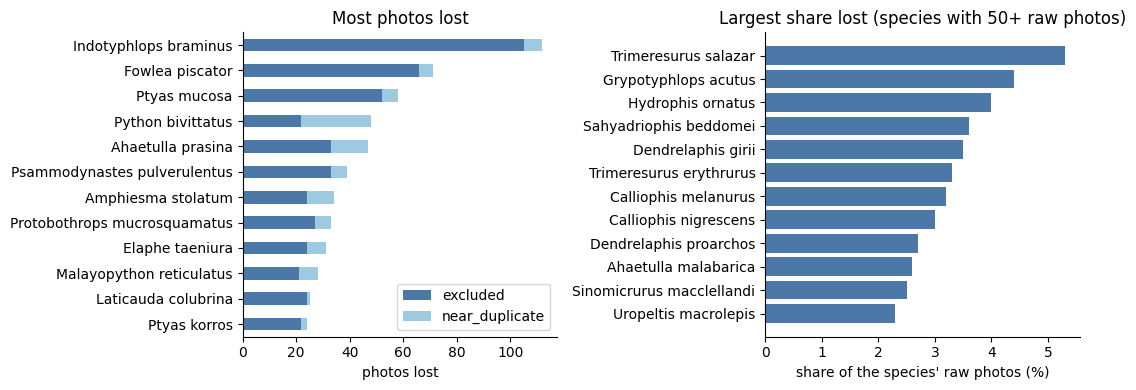

In [254]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
tab_loss.sort_values("lost").tail(12)[["excluded", "near_duplicate"]].plot.barh(stacked=True, ax=ax[0], color=["#4c78a8", "#9ecae1"])
ax[0].set(xlabel="photos lost", ylabel="", title="Most photos lost")
tab_rel = tab_loss[tab_loss["lost"] + tab_loss["kept"] >= 50].sort_values("share lost %").tail(12)
ax[1].barh(tab_rel.index, tab_rel["share lost %"], color="#4c78a8")
ax[1].set(xlabel="share of the species' raw photos (%)", title="Largest share lost (species with 50+ raw photos)")
savefig("07a_species_loss"); plt.close()

The species that lose the most photos are mostly the common ones, simply because they have the most photos and the most repeated uploads. The right panel shows the species that lose the largest share, which is a different group. It only includes species with 50 or more raw photos, because a rare species can lose a big share from just a few removed photos, as the printed line above shows.

Finally, a few of the removed photos. We fetch them from their `url` column, since the files themselves are not part of the datasets. Only CC photos are shown (CC0 and CC BY first, CC BY-NC as a labelled fallback), as small thumbnails, with the photographer credit and the reason they were removed.

In [255]:
import requests
from io import BytesIO
from IPython.display import display, Image as IPImage

tab_pref = {"cc0": 0, "cc-by": 0, "cc-by-nc": 1}
def tab_pick(reason, k):
    pool = excluded[(excluded["drop_reason"] == reason) & excluded["license"].isin(tab_pref) & (excluded["bytes"] < 500_000)]
    return pool.assign(rank=pool["license"].map(tab_pref)).sample(frac=1, random_state=SEED).sort_values("rank", kind="stable").head(k)

tab_quota = {"exact_duplicate": 3, "too_small": 3, "duplicate_conflicting_species": 2}
tab_ex = pd.concat([tab_pick(reason, 1 if SMOKE else k) for reason, k in tab_quota.items()])
print(f"{len(tab_ex)} excluded photos chosen")

8 excluded photos chosen


In [256]:
tab_thumbs = []
for r in tab_ex.itertuples():
    try:
        resp = requests.get(r.url, timeout=10, headers={"User-Agent": "serpentguard-eda"})
        resp.raise_for_status()
        im = Image.open(BytesIO(resp.content)).convert("RGB"); im.thumbnail((256, 256))
        buf = BytesIO(); im.save(buf, "JPEG", quality=70)
        tab_thumbs.append((buf.getvalue(), r)); print(f"ok    {r.photo_id}  {r.drop_reason}")
    except Exception as err:
        print(f"skip  {r.photo_id}  {r.drop_reason}: {type(err).__name__}")

ok    661427458  exact_duplicate
ok    717049255  exact_duplicate
ok    669519363  exact_duplicate
ok    15405857  too_small
ok    15405844  too_small
ok    15405848  too_small
ok    524293371  duplicate_conflicting_species
ok    524293382  duplicate_conflicting_species


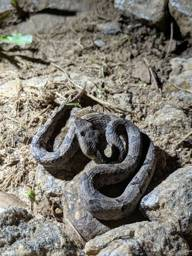

exact_duplicate | Hypnale hypnale | stored file 375 x 500 px, 199,542 bytes | credit: (c) Ahirbudhnyan M, some rights reserved (CC BY)


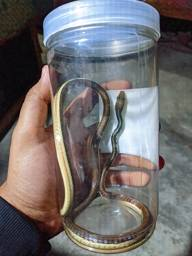

exact_duplicate | Dendrelaphis tristis | stored file 375 x 500 px, 162,134 bytes | credit: (c) HM Emon, some rights reserved (CC BY)


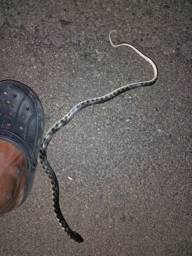

exact_duplicate | Fowlea piscator | stored file 375 x 500 px, 180,828 bytes | credit: (c) renjus box, some rights reserved (CC BY)


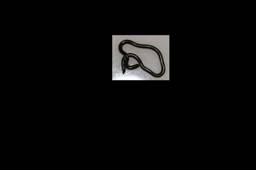

too_small | Indotyphlops braminus | stored file 500 x 333 px, 4,147 bytes | credit: no rights reserved


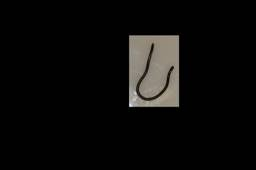

too_small | Indotyphlops braminus | stored file 500 x 333 px, 3,771 bytes | credit: no rights reserved


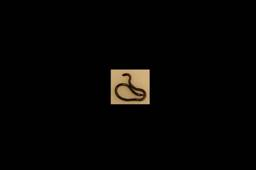

too_small | Indotyphlops braminus | stored file 500 x 333 px, 2,885 bytes | credit: no rights reserved


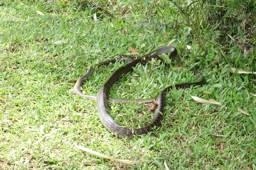

duplicate_conflicting_species | Fowlea piscator | stored file 500 x 333 px, 251,400 bytes | credit: (c) Oleg Kosterin, some rights reserved (CC BY)


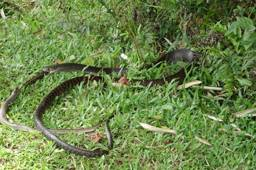

duplicate_conflicting_species | Fowlea piscator | stored file 500 x 333 px, 245,012 bytes | credit: (c) Oleg Kosterin, some rights reserved (CC BY)


In [257]:
for jpeg, r in tab_thumbs:
    display(IPImage(data=jpeg, format="jpeg"))
    print(f"{r.drop_reason} | {r.species} | stored file {r.width} x {r.height} px, {r.bytes:,} bytes | credit: {r.attribution}")
if not tab_thumbs:
    print("no photo could be fetched in this run")

A thumbnail shows what is at the address today, which can differ from the stored file that was excluded, for example when a download was cut short. The credit line is the `attribution` column as it is.

### 7b. Snake masks: the tables
The masks dataset holds a segmentation mask for training photos only, made with a snake detector and a segmentation model. `mask_stats.csv` has one row per photo with the detector score, mask size and a `flagged` column (true means check the mask before using it). Nothing here is typed in: the counts come from the file attached to this notebook, which may grow when a new version is published.

In [258]:
tab_mk = mask_stats.copy()
tab_mk_n = tab_mk.groupby("species").size().rename("masks")
tab_cov = classes.set_index("species")[["train", "who_category"]].join(tab_mk_n).fillna({"masks": 0})
tab_cov["coverage"] = tab_cov["masks"] / tab_cov["train"]
print(f"{len(tab_mk):,} masks for {tab_mk['species'].nunique()} classes; per class: smallest {tab_mk_n.min()}, median {tab_mk_n.median():.0f}, largest {tab_mk_n.max()}")
print(f"the masks cover {len(tab_mk) / tab_cov['train'].sum():.1%} of the training photos")
check("every mask belongs to a train photo", tab_mk["path"].str.startswith("train/").all())
check("every mask photo_id is a photo in metadata.csv", tab_mk["photo_id"].isin(meta["photo_id"]).all())
check("mask_stats has the expected columns", {"n_snake_boxes", "n_removed_boxes", "det_score", "mask_area_fraction", "fill_ratio", "flagged"} <= set(tab_mk.columns))

85,067 masks for 184 classes; per class: smallest 10, median 120, largest 8760
the masks cover 100.0% of the training photos
PASS  every mask belongs to a train photo
PASS  every mask photo_id is a photo in metadata.csv
PASS  mask_stats has the expected columns


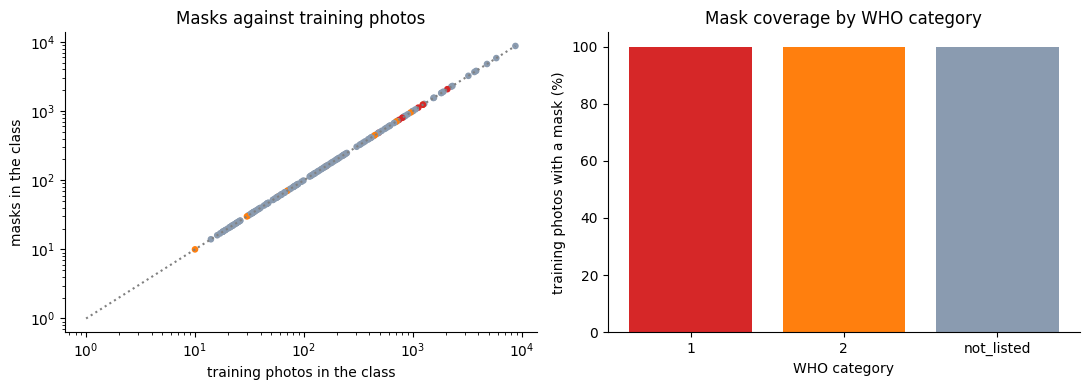

,masks,train,coverage %
who_category,,,
1,6469,6469,100.0
2,4486,4486,100.0
not_listed,74112,74112,100.0


In [259]:
tab_cov_who = tab_cov.groupby("who_category")[["masks", "train"]].sum().reindex(["1", "2", "not_listed"])
tab_cov_who["coverage %"] = (100 * tab_cov_who["masks"] / tab_cov_who["train"]).round(1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(tab_cov["train"], tab_cov["masks"], c=[WHO_COLORS[w] for w in tab_cov["who_category"]], s=14)
ax[0].plot([1, tab_cov["train"].max()], [1, tab_cov["train"].max()], ls=":", color="grey")
ax[0].set(xscale="log", yscale="log", xlabel="training photos in the class", ylabel="masks in the class", title="Masks against training photos")
ax[1].bar(tab_cov_who.index, tab_cov_who["coverage %"], color=[WHO_COLORS[c] for c in tab_cov_who.index])
ax[1].set(xlabel="WHO category", ylabel="training photos with a mask (%)", title="Mask coverage by WHO category")
savefig("07b_coverage"); plt.close()
tab_cov_who

The dotted line is where every training photo would have a mask, and a class below it has fewer masks than training photos. The printed coverage shows how much of the training set the masks reach. If coverage depends on class size, the WHO categories differ partly for that reason.

Now the flagged rate. A flagged mask needs a manual check before use, so let's see how often it happens in each WHO category.

overall flagged rate: 25.4% (21,629 of 85,067)


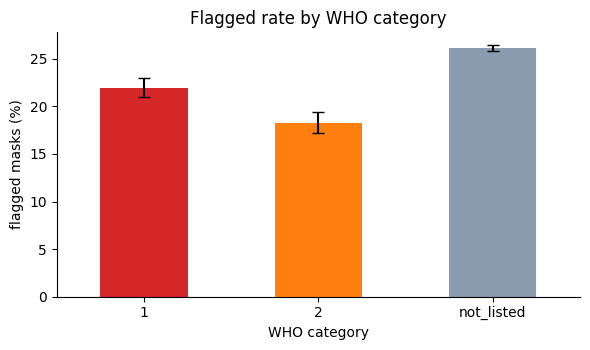

,flagged,masks,rate_pct
who_category,,,
1,1422,6469,22.0
2,821,4486,18.3
not_listed,19386,74112,26.2


In [260]:
tab_fl = tab_mk.groupby("who_category")["flagged"].agg(flagged="sum", masks="size", rate="mean").reindex(["1", "2", "not_listed"])
tab_fl["error"] = 1.96 * np.sqrt(tab_fl["rate"] * (1 - tab_fl["rate"]) / tab_fl["masks"])
print(f"overall flagged rate: {tab_mk['flagged'].mean():.1%} ({int(tab_mk['flagged'].sum()):,} of {len(tab_mk):,})")
ax = (100 * tab_fl["rate"]).plot.bar(yerr=100 * tab_fl["error"], color=[WHO_COLORS[c] for c in tab_fl.index], rot=0, figsize=(6, 3.6), capsize=4)
ax.set(xlabel="WHO category", ylabel="flagged masks (%)", title="Flagged rate by WHO category")
savefig("07b_flagged_who"); plt.close()
tab_fl[["flagged", "masks"]].assign(rate_pct=(100 * tab_fl["rate"]).round(1))

The bars show the flagged rate with a 95% interval. A flagged mask is not wrong for sure, it only means the automatic checks were not satisfied, so a high flagged rate in one category means more manual review there. Is the flag linked to the detector score?

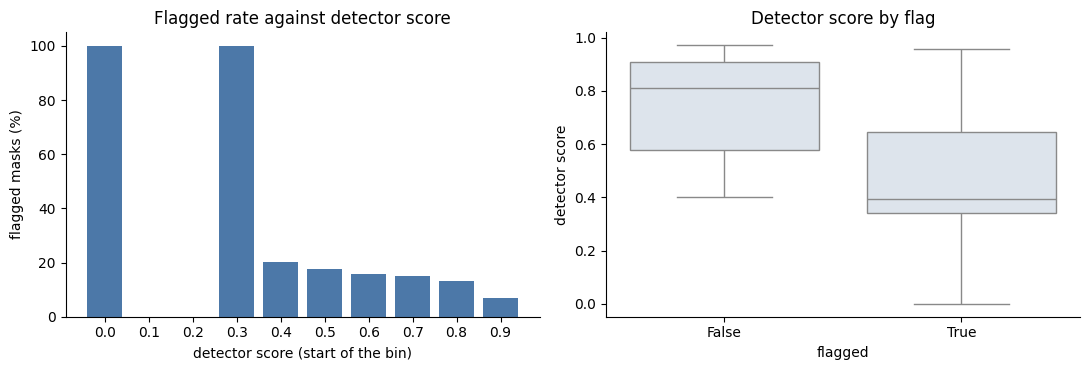

In [261]:
tab_cuts = pd.cut(tab_mk["det_score"], np.arange(0, 1.01, 0.1), include_lowest=True)
tab_fd = tab_mk.groupby(tab_cuts, observed=False).agg(masks=("flagged", "size"), flagged_pct=("flagged", lambda s: 100 * s.mean())).fillna(0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(range(len(tab_fd)), tab_fd["flagged_pct"], color="#4c78a8")
ax[0].set_xticks(range(len(tab_fd)), [f"{max(iv.left, 0):.1f}" for iv in tab_fd.index])
ax[0].set(xlabel="detector score (start of the bin)", ylabel="flagged masks (%)", title="Flagged rate against detector score")
sns.boxplot(data=tab_mk, x="flagged", y="det_score", color="#dbe4ee", ax=ax[1])
ax[1].set(xlabel="flagged", ylabel="detector score", title="Detector score by flag")
savefig("07b_flagged_score"); plt.close()

Low detector scores are flagged much more often, which is what we would expect if the flag partly follows the detector's confidence. The photos with a score of zero are the ones where no snake was found at all. The next lines print the lowest values that still pass, to see whether the flag looks like a set of thresholds.

In [262]:
tab_ok = tab_mk[~tab_mk["flagged"]]
print("lowest values among the unflagged masks:", {c: round(float(tab_ok[c].min()), 3) for c in ["det_score", "mask_area_fraction", "fill_ratio"]})
print("highest values among the unflagged masks:", {c: round(float(tab_ok[c].max()), 3) for c in ["det_score", "mask_area_fraction", "fill_ratio"]})
print(f"fill ratio above 1 (the mask is larger than its box): {(tab_mk['fill_ratio'] > 1).sum():,} masks")

lowest values among the unflagged masks: {'det_score': 0.4, 'mask_area_fraction': 0.01, 'fill_ratio': 0.1}
highest values among the unflagged masks: {'det_score': 0.971, 'mask_area_fraction': 0.598, 'fill_ratio': 0.95}
fill ratio above 1 (the mask is larger than its box): 177 masks


If the unflagged masks stop at round limits on score, area and fill ratio, the flag is a set of thresholds on these numbers. A fill ratio above 1 means the mask is larger than its own box, which should not happen, so those few rows are worth a look. Now the area fraction (how much of the photo the snake covers) and the fill ratio (how much of its box the mask fills).

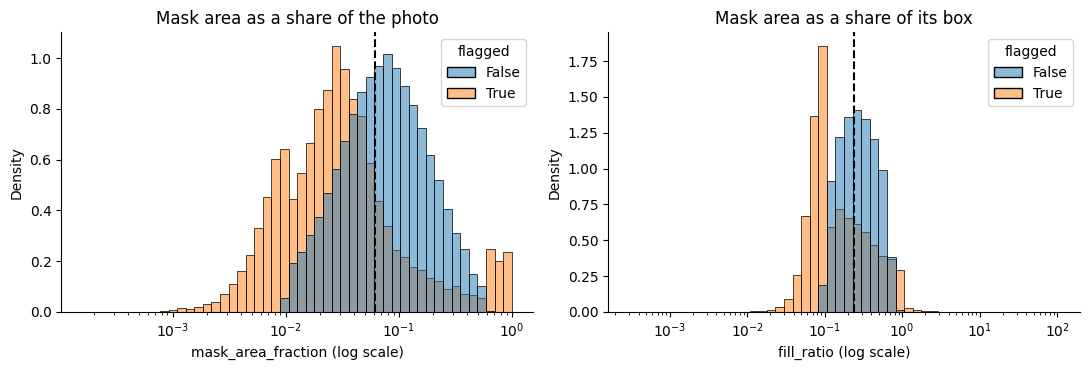

In [263]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, col, title in zip(ax, ["mask_area_fraction", "fill_ratio"], ["Mask area as a share of the photo", "Mask area as a share of its box"]):
    sns.histplot(data=tab_mk.dropna(subset=[col]), x=col, hue="flagged", log_scale=True, bins=50, stat="density", common_norm=False, ax=a)
    a.axvline(tab_mk[col].median(), color="k", ls="--"); a.set(title=title, xlabel=f"{col} (log scale)")
savefig("07b_area_fill"); plt.close()

Most masks cover only a small part of the photo and fill only a fraction of their box, which is normal for a long thin animal that curves. Flagged masks sit further to the left, where the masks are small, and spread out on both sides. The dashed line marks the median of all masks, flagged or not.

Three more kinds of photo are worth counting: two snakes in one photo, hands or gloves that were removed from the mask, and photos where no snake was found.

In [264]:
tab_mk["two_snakes"] = tab_mk["n_snake_boxes"] >= 2
tab_mk["hand_removed"] = tab_mk["n_removed_boxes"] > 0
tab_mk["no_snake"] = tab_mk["n_snake_boxes"] == 0
tab_kinds = ["flagged", "two_snakes", "hand_removed", "no_snake"]
tab_kind_n = pd.DataFrame({"photos": tab_mk[tab_kinds].sum(), "share %": 100 * tab_mk[tab_kinds].mean(), "of which flagged %": [100 * tab_mk.loc[tab_mk[k], "flagged"].mean() for k in tab_kinds]})
tab_kind_n.round(1)

,photos,share %,of which flagged %
flagged,21629,25.4,100.0
two_snakes,3711,4.4,78.0
hand_removed,3891,4.6,45.5
no_snake,2713,3.2,100.0


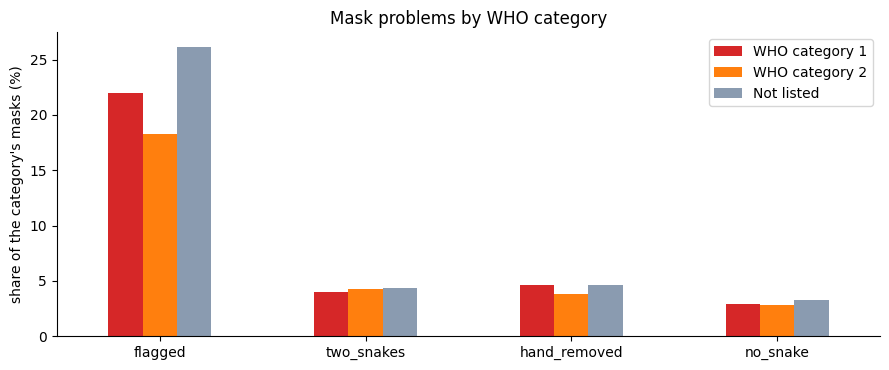

In [265]:
tab_mk_rates = (100 * tab_mk.groupby("who_category")[tab_kinds].mean()).reindex(["1", "2", "not_listed"])
ax = tab_mk_rates.T.plot.bar(color=[WHO_COLORS[c] for c in tab_mk_rates.index], rot=0, figsize=(9, 3.8))
ax.set(ylabel="share of the category's masks (%)", title="Mask problems by WHO category"); ax.legend([WHO_LABEL[c] for c in tab_mk_rates.index])
savefig("07b_kinds"); plt.close()

The table above shows how often each kind of photo is flagged. A photo with no snake has nothing to cut out and one mask cannot describe two animals, so these groups are expected to be flagged more often than the rest. The bars compare the three WHO categories, so we can see whether one of them has more trouble than the others.

In [266]:
tab_ns = tab_mk.groupby("species").agg(masks=("no_snake", "size"), no_snake=("no_snake", "sum"))
tab_ns["no snake %"] = (100 * tab_ns["no_snake"] / tab_ns["masks"]).round(1)
print(f"no snake found in {int(tab_ns['no_snake'].sum()):,} photos; {int((tab_ns['no_snake'] > 0).sum())} classes have at least one")
print("always flagged:", bool(tab_mk.loc[tab_mk["no_snake"], "flagged"].all()))
tab_ns[tab_ns["masks"] >= 20].sort_values("no snake %", ascending=False).head(8)

no snake found in 2,713 photos; 118 classes have at least one
always flagged: True


,masks,no_snake,no snake %
species,,,
Ahaetulla farnsworthi,334,57,17.1
Ahaetulla isabellina,116,17,14.7
Ahaetulla borealis,518,73,14.1
Dendrelaphis andamanensis,43,6,14.0
Ahaetulla oxyrhynca,719,86,12.0
Boiga dightoni,26,3,11.5
Ophiophagus kaalinga,70,8,11.4
Dendrelaphis ashoki,46,5,10.9


These are the classes where the detector finds nothing most often. Photos with no snake need a manual look or have to be left out of any step that depends on a mask.

### 7b-overlays. Snake mask overlays
The numbers above say how many masks are flagged. Here we look at the masks themselves. Each mask is a black and white PNG with the same size as its photo (white is snake). The file sits under `masks/<split>/<species>/` in the masks dataset, with the same name as the photo.

In the pictures the mask is the orange area with a yellow edge, the blue rectangle is the box the detector found for the snake, and a white rectangle is a hand or glove box that was cut out of the mask. Only CC0 and CC BY photos are shown (CC BY-NC only as a fallback, which the credit table marks). Photos with a detected face are skipped, and a note is printed if there are too few others.

In [267]:
def img_mask_file(mask_path):
    for base in (MASKS / "masks", MASKS):
        if isinstance(mask_path, str) and (base / mask_path).exists():
            return base / mask_path
    return None

img_mask_start = len(IMG_BYTES)
img_mstats = mask_stats.merge(meta[["path", "license", "attribution"]], on="path", how="left")
img_mstats = img_mstats[img_mstats["mask_path"].notna()].copy()
print(f"{len(img_mstats):,} masks have a mask file listed in mask_stats.csv, mask folder found: {(MASKS / 'masks').exists()}")

82,354 masks have a mask file listed in mask_stats.csv, mask folder found: True


A mask is flagged when there is no snake, the detector score is low, the mask fills too little or too much of its box, or it covers too little or too much of the photo. I rebuild that rule here to label every flagged mask with a reason, and check it against the `flagged` column.

In [268]:
def img_flag_reason(d):
    conds = [d["n_snake_boxes"] == 0, d["det_score"] < 0.40, d["fill_ratio"] < 0.10, d["fill_ratio"] > 0.95,
             d["mask_area_fraction"] < 0.01, d["mask_area_fraction"] > 0.60]
    names = ["no snake", "low score", "low fill", "high fill", "tiny area", "huge area"]
    return np.select(conds, names, default="ok")

img_mstats["reason"] = img_flag_reason(img_mstats)
agree = ((img_mstats["reason"] != "ok") == img_mstats["flagged"]).mean()
check("flag reasons rebuilt from the thresholds agree with the flagged column", agree >= 0.99, f"{agree:.2%}")
img_mstats.loc[img_mstats["flagged"], "reason"].value_counts()

PASS  flag reasons rebuilt from the thresholds agree with the flagged column  (100.00%)


reason
low score    8819
low fill     7200
tiny area    2195
huge area     556
high fill     146
Name: count, dtype: int64

Picking the examples: shuffle with the fixed seed, spread over WHO categories (good masks) or over flag reasons (flagged masks), and keep only photos and masks that exist on disk. These photos are not all in the measured sample, so the face detector from section 5 is run on each candidate here (photos from the sample reuse their stored face count).

In [269]:
IMG_FACE_CACHE = dict(zip(quality["path"], quality["face_count"]))

def img_faces(path):
    if path not in IMG_FACE_CACHE:
        IMG_FACE_CACHE[path] = img_face_count(np.asarray(Image.open(img_file(path)).convert("RGB")))
    return IMG_FACE_CACHE[path]

In [270]:
def img_mask_scan(df, spread, n):
    d = df.sample(frac=1, random_state=SEED)
    d = d.assign(r=d.groupby(spread).cumcount()).sort_values("r", kind="stable")
    seen, free = [], 0
    for i, row in zip(d.index, d.itertuples()):
        if img_file(row.path).exists() and img_mask_file(row.mask_path):
            seen.append((i, img_faces(row.path)))
            free += seen[-1][1] == 0
        if free >= n:
            break
    return d.loc[[i for i, c in seen]].assign(face_count=[c for i, c in seen])

In [271]:
def img_mask_rows(df, n, spread):
    got = []
    for faces in (False, True):
        for tier in (["cc0", "cc-by"], ["cc-by-nc"]):
            have = sum(len(g) for g in got)
            if have < n:
                part = img_mask_scan(df[df["license"].isin(tier)], spread, n - have)
                got.append(part[(part["face_count"] > 0) == faces].head(n - have))
    return pd.concat(got)

Now the drawing. Everything is done on the small copy (at most 224 px wide), so the lines stay thin and the file stays small.

In [272]:
def img_paint_mask(arr, mask):
    on = np.asarray(mask) > 127
    arr[on] = (0.55 * arr[on] + 0.45 * np.array([235, 104, 52])).astype(np.uint8)
    edges, _ = cv2.findContours(on.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(arr, edges, -1, (255, 230, 0), 1)

def img_draw_boxes(arr, boxes, scale, colour):
    for x1, y1, x2, y2 in boxes:
        cv2.rectangle(arr, (round(x1 * scale), round(y1 * scale)), (round(x2 * scale), round(y2 * scale)), colour, 1)

In [273]:
def img_overlay(row, show_mask=True, show_boxes=True, w=224, h=170):
    pic = Image.open(img_file(row.path)).convert("RGB")
    scale = min(w / pic.width, h / pic.height)
    size = (round(pic.width * scale), round(pic.height * scale))
    arr = np.array(pic.resize(size))
    if show_mask:
        img_paint_mask(arr, Image.open(img_mask_file(row.mask_path)).convert("L").resize(size, Image.NEAREST))
    if show_boxes:
        img_draw_boxes(arr, json.loads(row.snake_boxes), scale, (42, 120, 214))
        img_draw_boxes(arr, json.loads(row.removed_boxes), scale, (255, 255, 255))
    return Image.fromarray(arr)

In [274]:
def img_mask_grid(rows, kind, text):
    if rows.empty:
        print(f"no {kind} masks with a usable CC photo on disk, skipped")
        return
    rows = img_label(rows, kind[0].upper())
    entries = [(img_overlay(r), f"{r.label}. {img_short(r.species)} | {text(r)}") for r in rows.itertuples()]
    img_show(img_grid(entries + [None] * (-len(entries) % 4)))
    img_credits(rows, ["det_score", "mask_area_fraction", "fill_ratio", "reason"])

#### Good masks
Unflagged masks, mixed over the WHO categories. The number after the species is the detector score.

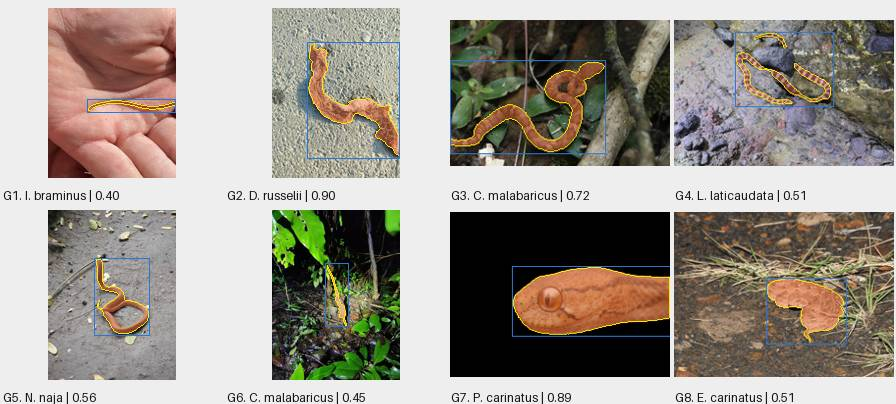

,species,WHO,det_score,mask_area_fraction,fill_ratio,reason,licence,credit
G1,Indotyphlops braminus,Not listed,0.40,0.02,0.29,ok,cc0,no rights reserved
G2,Daboia russelii,WHO category 1,0.90,0.12,0.25,ok,cc-by,"(c) Aryan K, some rights reserved (CC BY)"
G3,Craspedocephalus malabaricus,WHO category 2,0.72,0.11,0.24,ok,cc-by,"(c) madhavan a.p, some rights reserved (CC BY)"
G4,Laticauda laticaudata,Not listed,0.51,0.04,0.20,ok,cc-by,"(c) 張家瑜, some rights reserved (CC BY)"
G5,Naja naja,WHO category 1,0.56,0.05,0.25,ok,cc0,no rights reserved
G6,Craspedocephalus malabaricus,WHO category 2,0.45,0.01,0.16,ok,cc-by,"(c) Ashwin Viswanathan, some rights reserved (CC BY)"
G7,Pareas carinatus,Not listed,0.89,0.23,0.75,ok,cc-by,"(c) Borja Fierro-Leva, some rights reserved (CC BY)"
G8,Echis carinatus,WHO category 1,0.51,0.07,0.51,ok,cc-by,"(c) Ashwin Viswanathan, some rights reserved (CC BY)"


In [275]:
img_good = img_mask_rows(img_mstats[~img_mstats["flagged"]], 8, "who_category")
img_mask_grid(img_good, "good", lambda r: f"{r.det_score:.2f}")

#### Flagged masks
Flagged masks, mixed over the flag reasons. The text after the species is the reason. The table shows the numbers behind it, so we can judge whether each flag was fair.

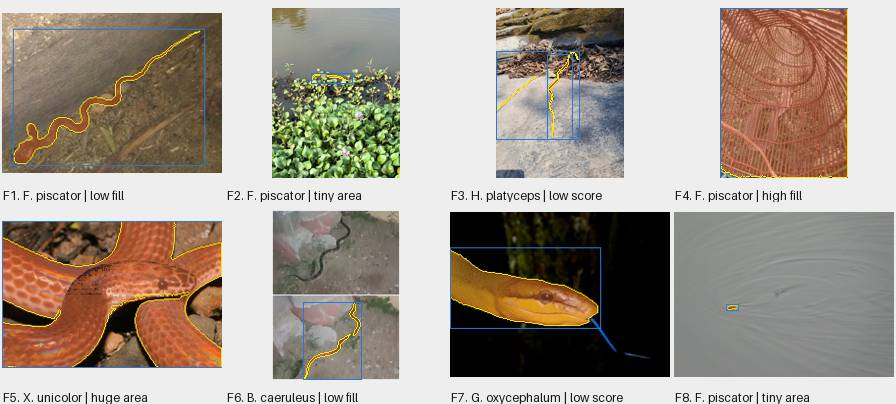

,species,WHO,det_score,mask_area_fraction,fill_ratio,reason,licence,credit
F1,Fowlea piscator,Not listed,0.79,0.06,0.08,low fill,cc-by,"(c) renjus box, some rights reserved (CC BY)"
F2,Fowlea piscator,Not listed,0.46,0.00,0.17,tiny area,cc-by,"(c) Pranav Chandra Bose, some rights reserved (CC BY)"
F3,Herpetoreas platyceps,Not listed,0.38,0.01,0.14,low score,cc-by,"(c) Tarun Meena, some rights reserved (CC BY)"
F4,Fowlea piscator,Not listed,0.43,0.99,0.99,high fill,cc-by,"(c) Siya ul haque, some rights reserved (CC BY)"
F5,Xenopeltis unicolor,Not listed,0.92,0.65,0.66,huge area,cc0,no rights reserved
F6,Bungarus caeruleus,WHO category 1,0.51,0.02,0.08,low fill,cc0,no rights reserved
F7,Gonyosoma oxycephalum,Not listed,0.36,0.17,0.50,low score,cc-by,"(c) Jay Paroline, some rights reserved (CC BY)"
F8,Fowlea piscator,Not listed,0.44,0.00,0.64,tiny area,cc-by,"(c) Aryan K, some rights reserved (CC BY)"


In [276]:
img_flagged = img_mask_rows(img_mstats[img_mstats["flagged"]], 8, "reason")
img_mask_grid(img_flagged, "flagged", lambda r: r.reason)

#### Before and after hand removal
People often hold the snake. The detector looks for hands and gloves in a second pass and cuts them out of the snake mask. On the left the boxes the detector found (blue for the snake, white for the hand or glove), on the right the final mask.

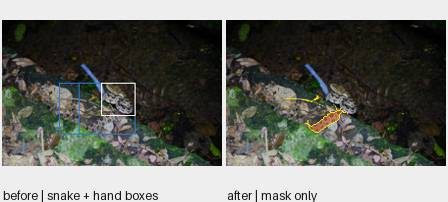

Protobothrops mucrosquamatus (cc-by), 1 hand or glove box removed, credit: (c) Jay Paroline, some rights reserved (CC BY)


In [277]:
img_hands = img_mask_rows(img_mstats[img_mstats["n_removed_boxes"] > 0], 1, "who_category")
if img_hands.empty:
    print("no hand-removal example with a usable CC photo on disk, skipped")
else:
    hand = next(img_hands.itertuples())
    pair = [(img_overlay(hand, show_mask=False), "before | snake + hand boxes"), (img_overlay(hand, show_boxes=False), "after | mask only")]
    img_show(img_grid(pair, cols=2))
    print(f"{hand.species} ({hand.license}), {hand.n_removed_boxes} hand or glove box removed, credit: {hand.attribution}")

A last size check for the mask pictures.

In [278]:
img_mask_mb = sum(IMG_BYTES[img_mask_start:]) / 1e6
check("mask overlay pictures stay under 0.8 MB together", img_mask_mb <= 0.8, f"{len(IMG_BYTES) - img_mask_start} pictures, {img_mask_mb:.2f} MB")

PASS  mask overlay pictures stay under 0.8 MB together  (3 pictures, 0.14 MB)


## 9. Summary
The notebook ends with three things: one table of the main numbers, a tally of every check that ran, and what the data means for modelling. All numbers in the table are computed here from the tables above.

### 9.1 Key numbers
First the numbers about the data, the labels and the class balance.

In [279]:
tab_key = []

def tab_add(group, name, value):
    tab_key.append((group, name, round(float(value), 2)))

tab_add("data", "photos", len(meta))
tab_add("data", "classes", len(classes))
tab_add("data", "families", meta["family"].nunique())
tab_add("data", "photos in the unknown pool", (meta["tier"] == "unknown_pool").sum())
tab_add("labels", "WHO category 1 photos (%)", 100 * (meta["who_category"] == "1").mean())
tab_add("labels", "WHO category 2 photos (%)", 100 * (meta["who_category"] == "2").mean())
tab_add("labels", "classes in WHO category 1 or 2", (classes["who_category"] != "not_listed").sum())
tab_add("balance", "share of photos in the 10 largest classes (%)", 100 * tab_n.head(10).sum() / tab_n.sum())
tab_add("balance", "imbalance ratio, largest to smallest class", tab_imb.loc["imbalance ratio (largest / smallest)", "all splits"])
tab_add("balance", "Gini of class counts", tab_imb.loc["Gini of class counts", "all splits"])
tab_add("balance", "effective number of classes (1 / sum p^2)", tab_imb.loc["effective classes (1 / sum p^2)", "all splits"])

Next the splits, the leakage checks and the cleaning funnel.

In [280]:
tab_add("splits", "test photos (% of all photos)", 100 * (meta["split"] == "test").mean())
tab_add("splits", "classes with no test photos", len(tab_zero))
tab_add("splits", "classes with no val photos", (classes["val"] == 0).sum())
tab_add("splits", "keys shared between train, val and test (sum of the leakage table)", tab_leak.values.sum())
tab_add("splits", "test photos that break the test rule", tab_viol.sum())
tab_add("cleaning", "raw rows", tab_raw)
tab_add("cleaning", "rows in excluded.csv", len(excluded))
tab_add("cleaning", "near-duplicates removed from val and test", len(tab_nd))
tab_add("cleaning", "largest share of a species lost (%)", tab_loss["share lost %"].max())

Last the images, the context columns and the masks.

In [281]:
tab_add("images", "median file size (KB)", tab_kb.median())
tab_add("images", "largest file (MB)", tab_img["bytes"].max() / 1e6)
tab_add("images", "photos with the short side below 224 px (%)", 100 * tab_small_share[224])
tab_add("images", "photos with a non-jpg address in the url column", (~tab_img["url_ext"].isin(["jpg", "jpeg"])).sum())
tab_add("context", "photographers", len(tab_obs))
tab_add("context", "share of photos from the top 1% of photographers (%)", 100 * tab_top1)
tab_add("context", "photos inside India (%)", 100 * meta["in_india"].mean())
tab_add("context", "photos that can be shown first, CC0 or CC BY (%)", 100 * (tab_show == "show first").mean())
tab_add("context", "classes with no CC0 or CC BY photo", tab_few.iloc[0])
tab_add("masks", "masks in mask_stats.csv", len(tab_mk))
tab_add("masks", "flagged masks (%)", 100 * tab_mk["flagged"].mean())

In [282]:
tab_keydf = pd.DataFrame(tab_key, columns=["group", "number", "value"]).set_index(["group", "number"])
tab_keydf

value
group    number                                                       
data     photos                                              121566.00
         classes                                                184.00
         families                                                14.00
         photos in the unknown pool                             815.00
labels   WHO category 1 photos (%)                                7.60
         WHO category 2 photos (%)                                5.35
         classes in WHO category 1 or 2                          16.00
balance  share of photos in the 10 largest classes (%)           45.10
         imbalance ratio, largest to smallest class             547.18
         Gini of class counts                                     0.73
         effective number of classes (1 / sum p^2)               32.58
splits   test photos (% of all photos)                            4.23
         classes with no test photos                             36.00
         classes with no val photos                               8.00
         keys shared between train, val and test (sum of...       0.00
         test photos that break the test rule                     0.00
cleaning raw rows                                            182497.00
         rows in excluded.csv                                   994.00
         near-duplicates removed from val and test              185.00
         largest share of a species lost (%)                     24.10
images   median file size (KB)                                  124.11
         largest file (MB)                                       26.16
         photos with the short side below 224 px (%)              0.70
         photos with a non-jpg address in the url column        407.00
context  photographers                                        15842.00
         share of photos from the top 1% of photographer...      28.08
         photos inside India (%)                                 37.84
         photos that can be shown first, CC0 or CC BY (%)        13.52
         classes with no CC0 or CC BY photo                      13.00
masks    masks in mask_stats.csv                              85067.00
         flagged masks (%)                                       25.43

### 9.2 How the checks went
Every `check()` call in the notebook prints PASS or FAIL and keeps its result. Here is the tally.

In [283]:
tab_pass = sum(ok for _, ok in CHECKS)
print(f"{len(CHECKS)} checks ran: {tab_pass} passed, {len(CHECKS) - tab_pass} failed")
for label, ok in CHECKS:
    if not ok:
        print("FAIL  ", label)
if tab_pass == len(CHECKS):
    print("no check failed")

87 checks ran: 87 passed, 0 failed
no check failed


A failed check means the data differs from what the earlier reports said, so it is a finding and not an error in the notebook. Each one is worth reading next to the cell that printed it.

### 9.3 What this means for modelling
These points follow from the tables and charts above. They refer to the tables instead of repeating the numbers, so they stay true when the data is refreshed.

- **Class imbalance.** The imbalance table in section 2.2 shows a very large ratio between the largest and smallest class, and an effective number of classes far below the real one. Plain accuracy would mostly reflect a few big species. Use macro-averaged scores, per-class recall and per-tier results, and try class-balanced sampling or loss weights.
- **Tiny classes.** Many classes have only a few dozen photos (2.2 and 2.5). Training them from scratch is not realistic: use a pretrained backbone, strong augmentation, and consider grouping the rarest classes under a coarser label such as the genus. Scores on these classes rest on very few val and test photos, so they move a lot.
- **Classes with no test photos.** Some classes, including some in WHO categories 1 and 2, have no test photos (3.3). They can only be checked on val or test_extra, which do not follow the test rule. Report them separately instead of calling the test score a score over all classes.
- **Near-duplicates and repeated uploads.** Exact duplicates were dropped everywhere, and near-duplicates only from val and test (7a). Copies can still sit inside train, which inflates its size without adding information, so it is worth looking for them before choosing a model size.
- **Look-alikes.** The dangerous and not-listed sides of each pair are rarely balanced, and the smaller side of a pair limits how well it can be tested (7). A dangerous snake called harmless costs far more than the reverse, so report the confusion between the two sides of every pair, favour recall for WHO categories 1 and 2, and check that photo style does not separate the pairs (7.1). The pairs with two dangerous snakes (7.2) deserve their own confusion counts too.
- **Photographers and place.** A few photographers take a large share of the photos, and small classes lean on a handful of them (6.3). Keep splits grouped by observer, limit how many photos one person adds to a class, and expect a gap between val and test, since test is India only and recent while train and val mix many countries (3.4 and 6.1).
- **Licences.** All-rights-reserved and no-derivatives photos were removed from this dataset. Only a minority of what's left is CC0 or CC BY, and some classes have none (6.4). Any shared dataset, demo or figure has to follow the licence of each photo and credit the photographer.
- **Image files.** Every photo is at most 500 px on its long side, many are portrait, and a few files came from .gif or .png addresses and are very large (4.6). Resize while keeping the aspect ratio, take a single frame from animated files, and consider re-encoding or dropping the extreme files.
- **Coordinates.** Some coordinates are missing and many are obscured, so location is a weak feature. The `in_india` flag is filled for every photo and is safer to use.
- **Masks.** Flagged masks need a manual look before use, and photos with no snake or two snakes tend to be flagged (7b). Train mask-based steps on unflagged masks, and check how much of the training set the attached version of the masks covers.

### 9.4 Order of operations: what is done, and where to find it
Image data is usually prepared in a fixed order, because some steps only make sense after others. For example, anything that is learned from the data, like colour statistics, has to wait until the split exists. This table lines up that order with what has been done for this project and where in the notebook it shows.

| # | Step | What it protects against | Status | Where |
|---|---|---|---|---|
| 1 | Keep source, licence and photographer for every photo | Using photos we are not allowed to show or share | Done in the dataset | 4.7, 4.8, 6.4 |
| 2 | Check that every file opens and matches the table | Broken files, wrong sizes | Done, and checked again here | 1.3, 5.4, 5.20 |
| 3 | One format and one size | Mixed formats and sizes | Done in the dataset (JPEG, long side 500 px) | 4.1 to 4.4 |
| 4 | Remove exact duplicates (file hash and picture hash) | The same photo in train and test | Done | 3.5, 7a |
| 5 | Look for near-duplicates | Near copies that lift the test score | Done: anything within 4 bits of an earlier split was dropped from val and test. Measured again here | 3.6, 5.6, 5.14, 5.19 |
| 6 | Check the labels | Wrong or mixed-up labels | Checked here: class table, subspecies, label-issue list | 1.4, 3.6, 5.15 |
| 7 | Split first, grouped by photographer | Information leaking from test into training | Done | 3.1 to 3.5 |
| 8 | Work out normalisation numbers on training photos only | Test statistics leaking into training | Estimated here from the sample. To be redone on the full training set | 5.13 |
| 9 | Resize, crop and normalise inside the model input pipeline | Train and test photos treated differently | Done in notebook 06 | |
| 10 | Augment training photos only | Changing the photos we test on | Done in notebook 06. Hints: photo shape (3.6), colour (5.13), snake size (5.16), look-alike pairs (5.18) | |
| 11 | Deal with class imbalance while training | A model that ignores rare species | Done in notebook 06; losses compared in Milestone 3 | 2.2 |
| 12 | Keep a record of what was done | Results nobody can reproduce | Done: `processing_report.json`, `excluded.csv`, `splits.csv`, and this notebook with a fixed seed | 1.5, 7a |

Steps 1 to 8 are about the data and are covered in this notebook. Steps 9 to 11 are built in notebook 06, and training tests them in Milestone 3.

### 9.5 What sections 5.13 to 5.20 add
- **Colour:** normalise with the training numbers from 5.13 (redone on the full training set) and not the ImageNet defaults. test_extra is darker than train, so keep brightness and contrast augmentation.
- **Do the splits look alike?** On embeddings, a classifier cannot tell val or test photos from training photos (5.14), so there is no large hidden shift. The size and shape gaps found in 3.6 are what is left.
- **Near-copies:** the embedding found photos from different photographers that look almost the same, one pair across test and val. Look at them before the split is frozen.
- **Labels:** the label-issue list in 5.15 is a ranking to check by hand, not a list of errors. Its top is mostly photos where the snake is hard to see.
- **Input size:** about 7 snakes in 100 are shorter than 64 px at 224 px and about 1 in 100 at 384 px (5.16). Compare 224 and 384, and try cropping to the snake.
- **Cleaning rule:** drop only blurry and tiny photos. Dark photos are often night-time photos of whole species (5.17).
- **Taxonomy and look-alikes:** genus and family are visible in the embedding (5.18). Many dangerous species have a close relative that is not WHO-listed, so check those pairs as well.
- **Coverage and files:** test photos are covered as well as val (5.19). Convert every photo to RGB, because a few PNG files are stored under a `.jpg` name (5.20).